# Informe técnico del MVP · Mtabolic
## Estimación temprana del riesgo de no renovación de membresías

**Proyecto:** Sistema inteligente para la estimación temprana del riesgo de no renovación de membresías mediante aprendizaje automático: caso de estudio en Mtabolic
**Programa:** Maestría en Inteligencia Artificial Aplicada · Universidad de Las Américas
**Autores:** Carlos Andrés Mejía Hidalgo · Jair Didier Quezada Molina · Juan Pablo Del Salto Granja
**Fecha:** septiembre de 2026

---

Este notebook es, al mismo tiempo, **el código que construye el MVP** y **el informe que explica cómo se construyó**. Se escribió para que lo pueda seguir cualquier integrante del equipo, sin importar si su formación es en inteligencia artificial, ingeniería industrial o administración de empresas.

> **Nota metodológica:** el notebook **no modifica los archivos Excel originales**. Solo los lee y crea tablas nuevas en memoria y en la carpeta `salidas_mvp`.

## Resumen ejecutivo

**Problema.** Mtabolic no tiene una forma consolidada de saber, con anticipación, qué socios probablemente **no renovarán** su membresía. Hoy la asesora revisa socio por socio y muchas veces el contacto llega cuando la persona ya decidió no continuar.

**Solución desarrollada.** Un sistema que, **30 días antes de que venza cada membresía**, calcula una probabilidad de no renovación y ordena a los socios de mayor a menor riesgo. El resultado práctico es una **lista mensual priorizada**: "a estas 25 personas conviene llamarlas primero".

**Metodología.**
Excel → limpieza → identificar a cada socio → reconstruir sus membresías → decidir quién renovó y quién no → calcular variables con información disponible 30 días antes → entrenar dos modelos → compararlos con reglas definidas de antemano → probar el ganador en meses que nunca vio → generar las listas.

**Resultados principales.**
- Se compararon **Regresión Logística** y **Random Forest**. Se seleccionó **Random Forest**.
- En los meses de prueba (mayo–agosto 2026), de cada **25 socios** que el modelo pone al inicio de la lista, **20 realmente no renovaron**. Si se eligieran 25 socios sin ningún criterio, se esperarían unos **16–17**. Es decir, la lista concentra aproximadamente **20 % más** casos correctos que una selección sin priorizar.
- Cada socio de la lista va acompañado de los **factores principales** que explican su riesgo (explicación individual), además de la importancia global de las variables.
- Se entrega una **lista operativa hacia adelante**: socios que vencen del 1 al 30 de septiembre de 2026, con **una fila por socio**, excluyendo a quienes ya renovaron.
- El modelo **ordena** mejor que el azar, pero **sus probabilidades todavía no son un porcentaje exacto** de riesgo. Por eso debe usarse para **priorizar**, no para afirmar "este socio tiene exactamente 73 % de probabilidad de irse".

**Alcance.** El sistema no demuestra que una llamada logre la renovación (no es un análisis causal), no envía mensajes automáticamente y no reemplaza el criterio del personal de Mtabolic.

## Estructura del informe

Cada sección del informe se presenta con la misma estructura:

| Elemento | Contenido |
|---|---|
| **Descripción** | Procedimiento realizado en la sección. |
| **Justificación** | Razón por la que el procedimiento es necesario. |
| **Objetivo** | Resultado que se busca obtener. |
| **Código** | Implementación en Python, con comentarios que explican cada paso. |
| **Interpretación de los resultados** | Lectura de las tablas y gráficos obtenidos y su significado para el proyecto. |

Los textos que acompañan a cada celda permiten seguir el proceso sin necesidad de revisar el código línea por línea.

## Glosario básico

| Término | Significado en este proyecto | Analogía |
|---|---|---|
| **Registro** | Una fila de las hojas mensuales del Excel. | Una línea de un libro de ventas. |
| **Socio** | La persona. Un socio puede tener varios registros (varias membresías en el tiempo). | Un cliente con varias facturas. |
| **Ciclo de membresía** | Un período pagado: desde la fecha de inicio hasta la fecha de vencimiento. | Un contrato con fecha de inicio y fin. |
| **Renovación** | El socio vuelve a registrar una membresía entre el vencimiento y 30 días después. | Renovar el seguro del auto a tiempo. |
| **No renovación** | Pasaron 30 días después del vencimiento y no aparece una nueva membresía. | No renovar el seguro. |
| **Variable (o característica)** | Un dato que describe el ciclo: plan, monto, antigüedad, etc. | Las columnas de una ficha de cliente. |
| **Variable objetivo** | Lo que queremos predecir: `no_renovo` (1 = no renovó, 0 = renovó). | La respuesta del examen. |
| **Modelo** | Una fórmula aprendida de los datos que convierte variables en una probabilidad. | Un analista experimentado que, viendo la ficha, estima el riesgo. |
| **Entrenar** | Mostrar al modelo casos pasados con su respuesta para que aprenda patrones. | Estudiar con exámenes resueltos. |
| **Validar / Probar** | Medir el modelo en casos que no usó para aprender. | Rendir un examen con preguntas nuevas. |
| **Probabilidad de no renovación** | Un número entre 0 y 1 que expresa el riesgo estimado. | Un puntaje de riesgo crediticio. |
| **Umbral** | Punto de corte para convertir la probabilidad en "sí/no". | La nota mínima para aprobar. |
| **Fuga de información (leakage)** | Usar sin querer datos del futuro para predecir. Hace que el modelo parezca mejor de lo que es. | Ver las respuestas antes del examen. |

## La línea de tiempo del problema: T−30, T y T+30

Todo el proyecto gira alrededor de tres fechas para cada membresía:

| Fecha | Nombre | Qué ocurre |
|---|---|---|
| **T−30** | Momento de predicción | 30 días antes del vencimiento. El modelo calcula el riesgo **solo con lo que se sabía hasta ese día**. |
| **T** | Vencimiento | Fecha de fin del plan. |
| **T+30** | Fin de la ventana de observación | Si hasta este día no hay una nueva membresía, el ciclo se considera **no renovado**. |
| **Fecha de corte** | Último día con datos | 31 de agosto de 2026. Lo que pasa después no lo conocemos. |

**Regla clave:** si la ventana T+30 todavía **no terminó** en la fecha de corte, el caso **no se clasifica como no renovación**: queda **pendiente de observación**.

**Ejemplo de la retroalimentación docente:** una membresía vence el 20 de agosto. La renovación solo puede verificarse hasta el 19 de septiembre, mientras que los datos disponibles llegan hasta el 31 de agosto. Conclusión correcta: **todavía no se puede confirmar la no renovación**.

La siguiente celda dibuja esta línea de tiempo.

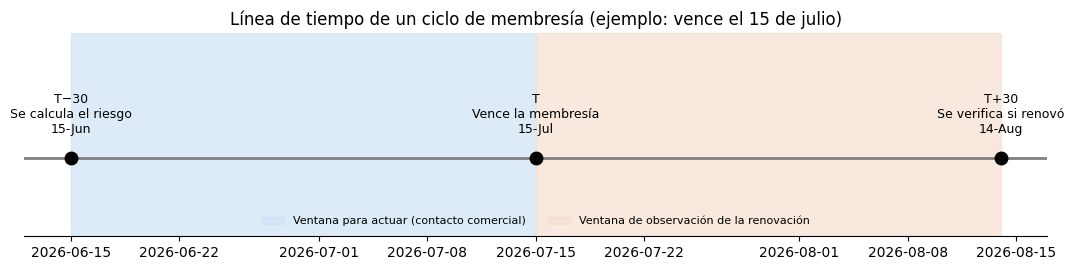

In [1]:
# Dibujamos la línea de tiempo T-30 / T / T+30 con un ejemplo concreto.
import matplotlib.pyplot as plt
import pandas as pd

T = pd.Timestamp("2026-07-15")                 # fecha de vencimiento de ejemplo
hitos = {
    "T−30\nSe calcula el riesgo": T - pd.Timedelta(days=30),
    "T\nVence la membresía": T,
    "T+30\nSe verifica si renovó": T + pd.Timedelta(days=30),
}

fig, ax = plt.subplots(figsize=(11, 2.8))
ax.axhline(0, color="gray", lw=2)                          # la línea del tiempo
ax.axvspan(hitos["T−30\nSe calcula el riesgo"], T, color="#cfe3f7", alpha=0.7,
           label="Ventana para actuar (contacto comercial)")
ax.axvspan(T, hitos["T+30\nSe verifica si renovó"], color="#f7dfcf", alpha=0.7,
           label="Ventana de observación de la renovación")
for texto, fecha in hitos.items():
    ax.plot(fecha, 0, "o", color="black", ms=9)
    ax.annotate(f"{texto}\n{fecha:%d-%b}", (fecha, 0), xytext=(0, 18),
                textcoords="offset points", ha="center", fontsize=9)
ax.set_yticks([])
ax.set_ylim(-1, 1.6)
ax.set_title("Línea de tiempo de un ciclo de membresía (ejemplo: vence el 15 de julio)")
ax.legend(loc="lower center", ncol=2, fontsize=8, frameon=False)
for lado in ["left", "right", "top"]:
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

#### Interpretación de los resultados

La franja azul es el tiempo que tiene Mtabolic para actuar después de recibir la lista (30 días). La franja naranja es el tiempo que esperamos para saber qué pasó realmente. La información de la franja naranja **nunca** se entrega al modelo para predecir; solo se usa para calificar si acertó.

## Mapa del proceso

El trabajo sigue las fases de la metodología **CRISP-DM**, el estándar más usado en proyectos de analítica. Para un ingeniero industrial, puede verse como un **proceso productivo**: la materia prima (Excel) pasa por estaciones de trabajo hasta convertirse en un producto terminado (la lista priorizada), con **controles de calidad** en el camino.

| Parte | Fase CRISP-DM | Qué se hace | Producto de la fase |
|---|---|---|---|
| **1** | Preparación | Cargar herramientas y fijar las reglas del negocio | Configuración única |
| **2** | Comprensión de los datos | Encontrar y explorar los Excel | Inventario de hojas |
| **3** | Preparación de datos | Leer, limpiar y estandarizar | Tabla única y limpia |
| **4** | Preparación de datos | Identificar socios, planes y pagos | Datos normalizados |
| **5** | Definición del problema | Decidir quién renovó y quién no | Variable objetivo |
| **6** | Análisis exploratorio | Ver la no renovación mes a mes | Diagnóstico del fenómeno |
| **7** | Ingeniería de variables | Construir variables conocidas en T−30 | Tabla para el modelo |
| **8** | Modelado | Separar pasado/validación/prueba | Conjuntos de datos |
| **9** | Modelado | Explicar y entrenar los dos modelos | Modelos entrenados |
| **10** | Evaluación | Explicar las métricas | Catálogo de métricas |
| **11** | Evaluación | Comparar y seleccionar | Modelo ganador |
| **12** | Evaluación | Prueba final e interpretación | Evidencia de desempeño |
| **13** | Despliegue | Listas mensuales priorizadas | Producto operativo |
| **14** | Despliegue | Exportar y controlar | Archivos y verificaciones |
| **15** | Cierre | Conclusiones, limitaciones y recomendaciones | Discusión |

---
# Parte 1 · Preparación del entorno y reglas del negocio

## Sección 1.1 · Herramientas utilizadas

**Descripción.** Se cargan las librerías (paquetes de código ya hechos) que usaremos.

**Justificación.** Python por sí solo es un lenguaje general. Las librerías aportan funciones especializadas: leer Excel, hacer tablas, graficar y entrenar modelos.

**Objetivo.** tener todas las herramientas disponibles antes de empezar.

| Librería | Para qué sirve | Analogía |
|---|---|---|
| **pandas** | Manejar tablas (como un Excel dentro de Python). | Hoja de cálculo |
| **numpy** | Cálculos numéricos rápidos. | Calculadora científica |
| **matplotlib** | Gráficos. | Asistente de gráficos de Excel |
| **scikit-learn** | Modelos de aprendizaje automático y métricas. | Caja de herramientas de IA |
| **joblib** | Guardar el modelo entrenado en un archivo. | "Guardar como…" |

In [2]:
# --- Librerías estándar de Python ---
import re                      # búsqueda de patrones en textos (expresiones regulares)
import unicodedata             # quitar tildes y caracteres especiales
import hashlib                 # crear códigos anónimos para los socios
import warnings                # controlar mensajes de advertencia
from pathlib import Path       # manejar rutas de archivos de forma segura
from datetime import datetime  # trabajar con fechas

# --- Librerías de análisis de datos ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display   # mostrar tablas con buen formato

# --- Librerías de aprendizaje automático (scikit-learn) ---
from sklearn.compose import ColumnTransformer        # aplica transformaciones distintas a cada tipo de columna
from sklearn.ensemble import RandomForestClassifier  # modelo Random Forest
from sklearn.impute import SimpleImputer             # completa valores faltantes
from sklearn.inspection import permutation_importance  # mide qué variables son importantes
from sklearn.linear_model import LogisticRegression  # modelo de Regresión Logística
from sklearn.metrics import (                        # métricas de evaluación
    accuracy_score, average_precision_score, brier_score_loss,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, precision_recall_curve,
)
from sklearn.calibration import calibration_curve    # para revisar la calidad de las probabilidades
from sklearn.pipeline import Pipeline                # encadena pasos en una "línea de producción"
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import joblib

# Colores usados en los gráficos (para que cada concepto tenga siempre el mismo color)
COLORES = {"azul": "#1F4E79", "azul_claro": "#4C8BC9", "verde": "#2E8B57", "rojo": "#C0392B",
           "naranja": "#E67E22", "gris": "#9AA5B1"}

def es(x, d=3, signo=False):
    # Escribe un número con coma decimal (formato español). Ej.: es(0.7899) -> "0,790"
    t = f"{x:{'+' if signo else ''},.{d}f}"
    return t.replace(",", "X").replace(".", ",").replace("X", ".")

warnings.filterwarnings("ignore")          # ocultamos advertencias no críticas para que el informe sea legible
pd.set_option("display.max_columns", 100)  # mostrar todas las columnas de las tablas
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)  # mostrar textos completos en las tablas

print("Herramientas cargadas correctamente.")

Herramientas cargadas correctamente.


## Sección 1.2 · Parámetros y reglas de negocio del MVP

**Descripción.** Se escriben como "parámetros" las decisiones de negocio que usa todo el notebook.

**Justificación.** Si Mtabolic decide cambiar una regla (por ejemplo, predecir 45 días antes en lugar de 30), basta con modificar este bloque, sin buscar el valor en todo el código. Es el equivalente a tener una **hoja de supuestos** en un modelo financiero.

**Objetivo.** que las reglas sean visibles, auditables y fáciles de cambiar.

| Parámetro | Valor | Significado para el negocio |
|---|---|---|
| `SEMILLA` | 42 | Fija el azar interno para que el resultado sea siempre el mismo (reproducibilidad). |
| `DIAS_ANTES_PREDICCION` | 30 | La lista se genera 30 días antes del vencimiento (T−30). |
| `DIAS_OBSERVACION` | 30 | Se esperan 30 días después del vencimiento para decidir si renovó (T+30). |
| `DIAS_RENOVACION_ANTICIPADA` | 0 | Por ahora no se cuentan renovaciones hechas **antes** del vencimiento (pendiente de confirmar con Mtabolic). |
| `TOP_K` | 25 | Capacidad operativa supuesta: la asesora puede contactar 25 socios prioritarios por mes. |
| `UMBRAL_CLASIFICACION` | 0,50 | Corte por defecto para convertir probabilidad en "sí/no". La lista **no** depende de él. |

In [3]:
SEMILLA = 42                     # número fijo para que los resultados aleatorios sean repetibles

DIAS_ANTES_PREDICCION = 30       # T-30: momento en que se estima el riesgo
DIAS_OBSERVACION = 30            # T+30: días que esperamos para saber si renovó
DIAS_RENOVACION_ANTICIPADA = 0   # 0 = no contamos renovaciones hechas antes de T

TOP_K = 25                       # tamaño de la lista mensual (capacidad de contacto)
UMBRAL_CLASIFICACION = 0.50      # umbral por defecto (solo para la referencia trivial)

np.random.seed(SEMILLA)          # fijamos la semilla de numpy
print("Configuración general lista.")

Configuración general lista.


---
# Parte 2 · Comprensión de los datos: ¿qué información tenemos?

## Sección 2.1 · Carga de los archivos

**Descripción.** Se ponen a disposición del notebook los dos libros de Excel de Mtabolic: **Control Gym 2025** y **Control Gym 2026**. El notebook puede trabajarse en dos entornos, y cada uno tiene su propia forma de cargar los archivos:

| Entorno | Dónde están los archivos | Sección |
|---|---|---|
| **Google Colab** (en la nube, desde el navegador) | Se suben desde el computador a la sesión de Colab. | 2.1.1 |
| **Local** (Jupyter, VS Code o Anaconda en el computador) | Se leen directamente desde una carpeta del computador. | 2.1.2 |

Se ejecuta **únicamente la celda del entorno que se esté utilizando**. Ambas celdas terminan definiendo la variable `CARPETA_DATOS`, que indica dónde están los archivos; a partir de la Sección 2.2 el proceso es idéntico en los dos entornos.

**Justificación.** Google Colab trabaja en un servidor remoto y no tiene acceso a los archivos del computador hasta que se suben; en cambio, un entorno local puede leerlos directamente desde una carpeta.

**Objetivo.** que el notebook pueda ejecutarse de principio a fin en cualquiera de los dos entornos.

### Sección 2.1.1 · Carga en Google Colab

**Procedimiento.**

1. Abrir el notebook en Google Colab.
2. Ejecutar la celda siguiente. Aparecerá un botón **"Elegir archivos"**.
3. Seleccionar los dos archivos: **Control Gym 2025** y **Control Gym 2026**.
4. Esperar a que la carga llegue al 100 %. Los archivos quedan guardados en la carpeta `/content` de la sesión de Colab.

**Consideración.** Los archivos subidos a Colab se borran al cerrar la sesión, por lo que este paso debe repetirse cada vez que se abra el notebook.

In [ ]:
# ===== CARGA EN GOOGLE COLAB =====
from google.colab import files        # herramienta de Colab para subir archivos desde el computador

print("Seleccione los archivos 'Control Gym 2025' y 'Control Gym 2026'.")
archivos_subidos = files.upload()    # abre el selector de archivos del navegador

CARPETA_DATOS = Path("/content")     # carpeta donde Colab guarda los archivos subidos
print("Archivos cargados en Colab:")
for nombre in archivos_subidos:
    print("  -", nombre)

### Sección 2.1.2 · Carga en entorno local

**Procedimiento.**

1. Guardar los dos archivos Excel en una carpeta del computador. Lo más sencillo es colocarlos **en la misma carpeta que este notebook**.
2. Si los archivos están en otra carpeta, escribir su ruta en la variable `CARPETA_DATOS` de la celda siguiente (hay un ejemplo en el comentario).
3. Ejecutar la celda. Debe listar los dos archivos encontrados.

In [5]:
# ===== CARGA EN ENTORNO LOCAL =====
# Carpeta donde están los dos archivos Excel. Por defecto: la misma carpeta de este notebook.
CARPETA_DATOS = Path.cwd()
# Ejemplo si están en otra carpeta (Windows):
# CARPETA_DATOS = Path(r"C:\Users\usuario\Documents\Mtabolic\datos")

excel_encontrados = sorted(CARPETA_DATOS.glob("*Control*Gym*.xlsx"))
print("Carpeta de datos:", CARPETA_DATOS)
print("Archivos Excel encontrados:")
for ruta in excel_encontrados:
    print("  -", ruta.name)

Carpeta de datos: (carpeta del notebook)
Archivos Excel encontrados:
  - Control Gym 2025 (1).xlsx
  - Control Gym 2026 (2).xlsx


## Sección 2.2 · Localización de las fuentes de datos

**Descripción.** Dentro de `CARPETA_DATOS` (definida en la Sección 2.1.1 o 2.1.2) se identifican los archivos cuyo nombre contiene `Control Gym` y el año (`2025` o `2026`).

**Justificación.** Evita escribir a mano el nombre exacto de cada archivo, que puede variar (por ejemplo, "Control Gym 2025 (1).xlsx"), y reduce errores.

**Objetivo.** identificar los dos libros de Excel que son la **materia prima** del proyecto. Si alguno no se encuentra, el notebook se detiene con un mensaje claro.

In [6]:
def buscar_archivo(anio):
    # Devuelve el Excel cuyo nombre contenga "Control", "Gym" y el año indicado.
    patron = f"*Control*Gym*{anio}*.xlsx"          # el * significa "cualquier texto"
    candidatos = sorted(CARPETA_DATOS.glob(patron))
    if not candidatos:                             # si no hay coincidencias, se detiene con un mensaje claro
        raise FileNotFoundError(
            f"No se encontró el archivo de {anio} en {CARPETA_DATOS}. "
            "Revisar la Sección 2.1 (carga en Colab o carpeta local)."
        )
    return candidatos[0]

archivo_2025 = buscar_archivo(2025)
archivo_2026 = buscar_archivo(2026)
print("Archivo 2025:", archivo_2025.name)
print("Archivo 2026:", archivo_2026.name)

Archivo 2025: Control Gym 2025 (1).xlsx
Archivo 2026: Control Gym 2026 (2).xlsx


## Sección 2.3 · Inventario de hojas de los libros Excel

**Descripción.** Se listan todas las hojas (pestañas) de cada libro.

**Justificación.** Los libros de Mtabolic mezclan distintos tipos de hojas: **mensuales** (consolidado del mes), **diarias** ("07 ene", "13 ene"…), **novedades**, **ventas**, **pendientes**, bases auxiliares, etc. Antes de leer datos hay que saber qué hay y decidir qué se usa.

**Objetivo.** tener un inventario completo de las hojas para justificar cuáles entran al análisis.

In [7]:
libro_2025 = pd.ExcelFile(archivo_2025)   # abre el libro sin leer todavía los datos
libro_2026 = pd.ExcelFile(archivo_2026)

print("Cantidad de hojas en 2025:", len(libro_2025.sheet_names))
print("Cantidad de hojas en 2026:", len(libro_2026.sheet_names))

# Mostramos ambos listados lado a lado
display(pd.concat([
    pd.Series(libro_2025.sheet_names, name="hojas_2025"),
    pd.Series(libro_2026.sheet_names, name="hojas_2026"),
], axis=1).fillna(""))

Cantidad de hojas en 2025: 43
Cantidad de hojas en 2026: 36


,hojas_2025,hojas_2026
0,07 ene,07 ene
1,13 ene,13 ene
2,06 ene,06 ene
3,08 ene,08 ene
4,09 ene,09 ene
5,10 ene,10 ene
6,11 ene,11 ene
7,14 ene,14 ene
8,15 ene,15 ene
9,16 ene,16 ene


## Sección 2.4 · Selección de las hojas mensuales

**Descripción.** Se clasifica cada hoja como **incluida** (si su nombre es un mes: ENERO, FEBRERO…) o **excluida** (todo lo demás).

**Justificación.** Las hojas mensuales contienen el registro consolidado de membresías del mes. Las hojas diarias repiten información y las administrativas tienen otro propósito. Usarlas todas duplicaría socios y mezclaría conceptos.

**Objetivo.** trabajar con una fuente homogénea: **una hoja por mes**. No se borra nada del Excel original; solo se **excluye del análisis**.

In [8]:
# Diccionario que traduce el nombre del mes a su número
MESES = {
    "ENERO": 1, "FEBRERO": 2, "MARZO": 3, "ABRIL": 4, "MAYO": 5, "JUNIO": 6,
    "JULIO": 7, "AGOSTO": 8, "SEPTIEMBRE": 9, "OCTUBRE": 10, "NOVIEMBRE": 11, "DICIEMBRE": 12,
}
nombres_meses = set(MESES.keys())

def clasificar_hojas(sheet_names, anio):
    # Para cada hoja decide si se usa (nombre = mes) y registra el motivo.
    filas = []
    for hoja in sheet_names:
        nombre_normalizado = hoja.strip().upper()     # quitamos espacios y pasamos a mayúsculas ("JUNIO " -> "JUNIO")
        incluida = nombre_normalizado in nombres_meses
        filas.append({
            "anio": anio,
            "hoja": hoja,
            "usar_en_modelo": "Sí" if incluida else "No",
            "motivo": "Hoja mensual" if incluida else "Hoja auxiliar / diaria / administrativa",
        })
    return pd.DataFrame(filas)

revision_hojas = pd.concat([
    clasificar_hojas(libro_2025.sheet_names, 2025),
    clasificar_hojas(libro_2026.sheet_names, 2026),
], ignore_index=True)

hojas_mensuales = revision_hojas.query("usar_en_modelo == 'Sí'").copy()

print("Resumen de la clasificación:")
display(revision_hojas.groupby(["anio", "usar_en_modelo"]).size().unstack(fill_value=0))
print("Hojas mensuales seleccionadas:", len(hojas_mensuales))
display(hojas_mensuales.groupby("anio")["hoja"].apply(lambda s: ", ".join(h.strip() for h in s))
        .reset_index(name="hojas mensuales incluidas"))

Resumen de la clasificación:


usar_en_modelo,No,Sí
anio,,
2025,31,12
2026,28,8


Hojas mensuales seleccionadas: 20


,anio,hojas mensuales incluidas
0,2025,"ENERO, FEBRERO, MARZO, ABRIL, MAYO, JUNIO, JULIO, AGOSTO, SEPTIEMBRE, OCTUBRE, NOVIEMBRE, DICIEMBRE"
1,2026,"ENERO, FEBRERO, MARZO, ABRIL, MAYO, JUNIO, JULIO, AGOSTO"


#### Interpretación de los resultados

Se identificaron **20 hojas mensuales**: 12 de 2025 (enero a diciembre) y 8 de 2026 (enero a agosto), que conforman el período de análisis del proyecto. Las 59 hojas restantes (diarias, novedades, ventas, pendientes y bases auxiliares) quedaron excluidas del análisis.

## Sección 2.5 · Estructura original de una hoja mensual

**Descripción.** Se leyeron las primeras 12 filas de la hoja ENERO 2025 **sin** indicar la posición del encabezado.

**Justificación.** En los Excel reales los títulos de columna no siempre están en la primera fila: puede haber fechas, títulos o filas vacías arriba. La revisión de la hoja original permite identificar dónde empieza realmente la tabla.

**Objetivo.** entender la estructura real antes de automatizar la lectura.

In [9]:
ejemplo_crudo = pd.read_excel(archivo_2025, sheet_name="ENERO", header=None, nrows=12)

# Por privacidad, en el informe ocultamos las columnas con datos personales (nombre, cédula, celular, correo).
vista = ejemplo_crudo.copy().astype(object)
vista.iloc[3:, 1:5] = "•••"
display(vista)

,0,1,2,3,4,5,6,7,8,9,10,11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,2025-01-06 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Nombres y apellidos del socio,Cédula,Celular,Correo,Tipo de plan,Fecha inscripción,Fecha fin plan,Tipo pago,No transaccion,MONTO A FACTURAR,MONTO A COBRAR
3,NaN,•••,•••,•••,•••,MENSUAL,2025-01-06 00:00:00,2025-02-06 00:00:00,Efectivo,efectivo,39,39
4,NaN,•••,•••,•••,•••,SEMESTRAL 2X1,2025-01-06 00:00:00,2025-06-06 00:00:00,transaccion Pichincha,233452468,225,225
5,NaN,•••,•••,•••,•••,ANUAL 2x1,2025-01-06 00:00:00,2026-01-05 00:00:00,transaccion Produbanco,260168020900,225,225
6,NaN,•••,•••,•••,•••,ANUAL 2x1,2025-01-06 00:00:00,2026-01-05 00:00:00,transf diners,BNK25006FD0CHMCG,225,225
7,NaN,•••,•••,•••,•••,MENSUAL,2025-01-06 00:00:00,2025-02-05 00:00:00,transfef diners,BNK25006FD0CHMCG,39,39
8,NaN,•••,•••,•••,•••,ANUAL 2X1,2025-01-06 00:00:00,2026-01-05 00:00:00,TRANSFERENCIA,287301087,225,225
9,NaN,•••,•••,•••,•••,ANUAL 2X1,2025-01-08 00:00:00,2026-01-07 00:00:00,TRANFERENCIA,45258133,450,450


#### Interpretación de los resultados

Los nombres de columna ("Nombres y apellidos del socio", "Cédula", "Tipo de plan"…) aparecen en la **fila 2** (Python cuenta desde 0), no en la primera. Además, en otros meses los nombres cambian (por ejemplo, "Fecha inscripción" pasa a llamarse "FECHA INICIO"). Por eso necesitamos una lectura **inteligente**, que se construye en la Parte 3.

---
# Parte 3 · Lectura y consolidación de los datos

## Sección 3.1 · Detección automática del encabezado

**Descripción.** Se crea una función que recorre las primeras 10 filas de una hoja y encuentra aquella que contiene a la vez las palabras **CEDULA** y **NOMBRE**.

**Justificación.** Cada mes el encabezado puede estar en una fila diferente (2, 3, 4 o 5). En lugar de indicar la fila a mano 20 veces (con riesgo de error), la función la encuentra sola.

**Objetivo.** leer cualquier hoja mensual sin intervención manual.

Primero se "normaliza" el texto: mayúsculas, sin tildes y sin espacios repetidos. Así "Cédula", "CEDULA" y "cédula " se reconocen como lo mismo.

In [10]:
def normalizar_texto_encabezado(valor):
    # Convierte un texto a MAYÚSCULAS, sin tildes y con espacios simples. Ej.: " Cédula  " -> "CEDULA"
    if pd.isna(valor):
        return ""
    texto = str(valor).strip().upper()
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()  # quita tildes
    texto = re.sub(r"\s+", " ", texto)                                                # une espacios repetidos
    return texto

def encontrar_fila_encabezado(tabla_sin_encabezado, max_filas=10):
    # Recorre las primeras filas y devuelve la posición de la que tiene "CEDULA" y "NOMBRE".
    limite = min(max_filas, len(tabla_sin_encabezado))
    for i in range(limite):
        fila = [normalizar_texto_encabezado(v) for v in tabla_sin_encabezado.iloc[i].tolist()]
        texto_fila = " | ".join(fila)
        if "CEDULA" in texto_fila and "NOMBRE" in texto_fila:
            return i
    return None   # si no la encuentra, devuelve "nada" y más adelante se mostrará un error

# Prueba con enero de 2025
print("Fila de encabezado detectada en ENERO 2025:", encontrar_fila_encabezado(ejemplo_crudo),
      "(Python comienza a contar desde 0)")

Fila de encabezado detectada en ENERO 2025: 2 (Python comienza a contar desde 0)


## Sección 3.2 · Equivalencia de nombres de columnas

**Descripción.** Se define, para cada dato que necesitamos, la lista de nombres con que puede aparecer en los Excel.

**Justificación.** El significado de una columna no cambió en el tiempo, pero su nombre sí: `Fecha inscripción` → `FECHA INICIO`, `Fecha fin plan` → `FECHA FIN`, `Monto a cobrar` → `MONTO COBRAR`. Este diccionario funciona como una **tabla de equivalencias**.

**Objetivo.** que todas las hojas terminen con los **mismos nombres estándar** de columna.

In [11]:
# campo estándar  ->  nombres posibles en el Excel (ya normalizados)
ALIAS_COLUMNAS = {
    "status":        ["STATUS"],
    "nombre":        ["NOMBRES Y APELLIDOS", "NOMBRES Y APELLIDOS DEL SOCIO"],
    "cedula":        ["CEDULA"],
    "celular":       ["CELULAR"],
    "correo":        ["CORREO"],
    "plan":          ["TIPO DE PLAN"],
    "fecha_inicio":  ["FECHA INSCRIPCION", "FECHA INICIO"],
    "fecha_fin":     ["FECHA FIN PLAN", "FECHA FIN"],
    "forma_pago":    ["TIPO PAGO"],
    "monto_cobrado": ["MONTO A COBRAR", "MONTO COBRAR"],
}

def buscar_indice_columna(encabezados_normalizados, aliases):
    # Devuelve la posición de la primera columna cuyo título contiene alguno de los alias.
    for i, encabezado in enumerate(encabezados_normalizados):
        for alias in aliases:
            if alias in encabezado:
                return i
    return None

display(pd.DataFrame({
    "campo_estandar": ALIAS_COLUMNAS.keys(),
    "posibles_nombres_en_excel": [", ".join(v) for v in ALIAS_COLUMNAS.values()],
}))

,campo_estandar,posibles_nombres_en_excel
0,status,STATUS
1,nombre,"NOMBRES Y APELLIDOS, NOMBRES Y APELLIDOS DEL SOCIO"
2,cedula,CEDULA
3,celular,CELULAR
4,correo,CORREO
5,plan,TIPO DE PLAN
6,fecha_inicio,"FECHA INSCRIPCION, FECHA INICIO"
7,fecha_fin,"FECHA FIN PLAN, FECHA FIN"
8,forma_pago,TIPO PAGO
9,monto_cobrado,"MONTO A COBRAR, MONTO COBRAR"


## Sección 3.3 · Conversión de fechas y montos

**Descripción.** Se crean dos "traductores": uno que convierte cualquier forma de fecha a una fecha real, y otro que convierte montos escritos como texto a números.

**Justificación.** En los Excel una fecha puede estar guardada como fecha real, como texto ("06/01/2025") o como el número interno de Excel (por ejemplo, 45663). Un monto puede aparecer como "39", "39,00" o "$39". Sin esta conversión no se podrían restar fechas ni sumar montos.

**Objetivo.** que todas las fechas y montos tengan un formato único y calculable.

In [12]:
def convertir_fecha(valor):
    # Convierte distintas representaciones de fecha a una fecha estándar (sin hora).
    if pd.isna(valor):
        return pd.NaT                                   # NaT = "fecha vacía"
    if isinstance(valor, (pd.Timestamp, datetime)):     # caso 1: ya es una fecha real
        return pd.Timestamp(valor).normalize()
    if isinstance(valor, (int, float)) and not isinstance(valor, bool):
        if 20000 <= float(valor) <= 60000:              # caso 2: número interno de Excel (días desde 1899-12-30)
            return (pd.Timestamp("1899-12-30") + pd.to_timedelta(float(valor), unit="D")).normalize()
    texto = str(valor).strip()                          # caso 3: la fecha viene como texto
    if not texto:
        return pd.NaT
    fecha = pd.to_datetime(texto, errors="coerce", dayfirst=True)   # primero probamos día/mes/año
    if pd.isna(fecha):
        fecha = pd.to_datetime(texto, errors="coerce", dayfirst=False)
    return fecha.normalize() if not pd.isna(fecha) else pd.NaT

def convertir_numero(valor):
    # Extrae el número de un texto: "39,50 USD" -> 39.5
    if pd.isna(valor):
        return np.nan
    if isinstance(valor, (int, float)) and not isinstance(valor, bool):
        return float(valor)
    texto = str(valor).replace(",", ".")                # la coma decimal se convierte en punto
    coincidencia = re.search(r"-?\d+(?:\.\d+)?", texto) # busca el primer número dentro del texto
    return float(coincidencia.group(0)) if coincidencia else np.nan

# Pequeña demostración
print(convertir_fecha("06/01/2025"), "|", convertir_fecha(45663), "|", convertir_numero("39,50 USD"))

2025-01-06 00:00:00 | 2025-01-06 00:00:00 | 39.5


## Sección 3.4 · Lectura estandarizada de una hoja mensual

**Descripción.** Se arma una función que, para una hoja: (1) localiza el encabezado, (2) identifica las columnas útiles con el diccionario de alias, (3) copia solo esos campos y (4) guarda de dónde vino cada fila (año, hoja y número de fila).

**Justificación.** El punto 4 es la **trazabilidad**: cualquier dato del análisis puede rastrearse hasta la celda exacta del Excel original. Es el mismo principio de un lote de producción con código de origen.

**Objetivo.** tener un procedimiento estándar que se aplique igual a las 20 hojas.

In [13]:
def leer_hoja_mensual(ruta_archivo, hoja, anio):
    tabla = pd.read_excel(ruta_archivo, sheet_name=hoja, header=None)   # leemos la hoja completa sin encabezado

    fila_encabezado = encontrar_fila_encabezado(tabla)                  # (1) ¿dónde están los títulos?
    if fila_encabezado is None:
        raise ValueError(f"No se encontró encabezado en la hoja {hoja} de {anio}.")

    encabezados = [normalizar_texto_encabezado(v) for v in tabla.iloc[fila_encabezado].tolist()]
    indices = {campo: buscar_indice_columna(encabezados, aliases)       # (2) ¿en qué columna está cada dato?
               for campo, aliases in ALIAS_COLUMNAS.items()}

    datos = tabla.iloc[fila_encabezado + 1:].copy()                     # los datos empiezan debajo del encabezado

    def tomar_columna(campo):
        # Si la columna no existe en esa hoja, se devuelve una columna vacía
        indice = indices[campo]
        if indice is None:
            return pd.Series([np.nan] * len(datos), index=datos.index)
        return datos.iloc[:, indice]

    salida = pd.DataFrame({                                             # (3) solo los campos necesarios
        "anio_origen": anio,                                            # (4) trazabilidad
        "hoja_origen": hoja,
        "fila_origen": datos.index + 1,                                 # fila tal como se ve en Excel
        "status_origen": tomar_columna("status"),
        "nombre": tomar_columna("nombre"),
        "cedula": tomar_columna("cedula"),
        "celular": tomar_columna("celular"),
        "correo": tomar_columna("correo"),
        "plan_crudo": tomar_columna("plan"),
        "fecha_inicio": tomar_columna("fecha_inicio"),
        "fecha_fin": tomar_columna("fecha_fin"),
        "forma_pago_cruda": tomar_columna("forma_pago"),
        "monto_cobrado": tomar_columna("monto_cobrado"),
    })
    salida["mes_hoja"] = pd.Timestamp(anio, MESES[hoja.strip().upper()], 1)  # primer día del mes de la hoja
    return salida

## Sección 3.5 · Consolidación de las 20 hojas mensuales

**Descripción.** Se aplica la función anterior a cada hoja mensual de 2025 y 2026 y se apilan todos los resultados en una sola tabla.

**Justificación.** Para analizar el comportamiento de un socio a lo largo del tiempo necesitamos toda su historia en un mismo lugar.

**Objetivo.** obtener una tabla única, todavía **sin limpiar**, con todo lo que contienen las hojas mensuales.

In [14]:
tablas_mensuales = []
for ruta, libro, anio in [(archivo_2025, libro_2025, 2025), (archivo_2026, libro_2026, 2026)]:
    for hoja in libro.sheet_names:
        if hoja.strip().upper() in nombres_meses:          # solo hojas mensuales
            tablas_mensuales.append(leer_hoja_mensual(ruta, hoja, anio))

datos_crudos = pd.concat(tablas_mensuales, ignore_index=True)   # apilamos todo
print("Filas leídas (incluye vacías, totales y resúmenes):", len(datos_crudos))

Filas leídas (incluye vacías, totales y resúmenes): 7769


## Sección 3.6 · Depuración de filas que no corresponden a socios

**Descripción.** Se descartan filas vacías, filas de totales/subtotales y filas que repiten el encabezado.

**Justificación.** Las hojas de Excel contienen espacios en blanco y resúmenes ("TOTAL", "SUMA"…). Si no se eliminan, se contarían como si fueran clientes.

**Objetivo.** quedarnos solo con filas que corresponden a un socio real.

In [15]:
datos_crudos["nombre"] = datos_crudos["nombre"].astype("string")
nombre_limpio_temporal = datos_crudos["nombre"].fillna("").str.strip()
nombre_mayuscula = nombre_limpio_temporal.str.upper()

es_fila_util = (
    nombre_limpio_temporal.ne("")                                                    # el nombre no está vacío
    & ~nombre_mayuscula.str.contains("TOTAL|SUBTOTAL|SUMA|MONTO", regex=True)       # no es una fila de totales
    & ~nombre_mayuscula.isin(["STATUS", "NOMBRES Y APELLIDOS", "NOMBRES Y APELLIDOS DEL SOCIO"])  # no es un encabezado repetido
)

filas_antes = len(datos_crudos)
datos_crudos = datos_crudos.loc[es_fila_util].copy()
n_filas_utiles = len(datos_crudos)   # guardamos la cifra para la reconciliación final
print("Filas descartadas (vacías / totales / encabezados):", filas_antes - len(datos_crudos))
print("Filas útiles (registros de socios):", len(datos_crudos))

Filas descartadas (vacías / totales / encabezados): 4998
Filas útiles (registros de socios): 2771


#### Interpretación de los resultados

Con los archivos actuales se obtuvieron **2.771 registros**. Esta cifra coincide con la reportada en el documento final (Tabla 1). El número **no está escrito a mano en el código**: se recalcula siempre desde los Excel, de modo que si llegan archivos nuevos, la cifra se actualiza sola.

## Sección 3.7 · Conversión de tipos de datos

**Descripción.** Se aplican los "traductores" de la Sección 3.3 a todas las filas, y los textos de plan y forma de pago se pasan a mayúsculas sin espacios sobrantes.

**Justificación.** Para que las fechas se puedan restar (calcular duraciones), los montos sumar, y los textos compararse sin que importen mayúsculas o espacios.

**Objetivo.** tener columnas con el tipo de dato correcto.

In [16]:
datos_crudos["fecha_inicio"] = datos_crudos["fecha_inicio"].apply(convertir_fecha)
datos_crudos["fecha_fin"] = datos_crudos["fecha_fin"].apply(convertir_fecha)
datos_crudos["monto_cobrado"] = datos_crudos["monto_cobrado"].apply(convertir_numero)

for col in ["plan_crudo", "forma_pago_cruda"]:
    datos_crudos[col] = datos_crudos[col].fillna("").astype(str).str.strip().str.upper()

# Vista de ejemplo SIN datos personales
display(datos_crudos[["anio_origen", "hoja_origen", "fila_origen", "plan_crudo",
                      "fecha_inicio", "fecha_fin", "forma_pago_cruda", "monto_cobrado"]].head(5))

,anio_origen,hoja_origen,fila_origen,plan_crudo,fecha_inicio,fecha_fin,forma_pago_cruda,monto_cobrado
0,2025,ENERO,4,MENSUAL,2025-01-06,2025-02-06,EFECTIVO,39.0
1,2025,ENERO,5,SEMESTRAL 2X1,2025-01-06,2025-06-06,TRANSACCION PICHINCHA,225.0
2,2025,ENERO,6,ANUAL 2X1,2025-01-06,2026-01-05,TRANSACCION PRODUBANCO,225.0
3,2025,ENERO,7,ANUAL 2X1,2025-01-06,2026-01-05,TRANSF DINERS,225.0
4,2025,ENERO,8,MENSUAL,2025-01-06,2025-02-05,TRANSFEF DINERS,39.0


## Sección 3.8 · Diagnóstico de calidad de los datos

**Descripción.** Se mide, para cada campo importante, qué porcentaje de valores está vacío y cuántos valores distintos tiene.

**Justificación.** Antes de tomar decisiones de limpieza es necesario **medir** el problema. Es el equivalente a un control de calidad de entrada de materia prima: permite conocer qué tan "defectuosos" llegan los datos.

**Objetivo.** cuantificar la calidad y justificar las decisiones posteriores.

,campo,faltante_%,valores_unicos
0,nombre,0.0,1437
1,cedula,8.2,1425
2,plan_crudo,7.0,281
3,fecha_inicio,35.7,393
4,fecha_fin,31.7,534
5,forma_pago_cruda,8.3,515
6,monto_cobrado,6.7,299


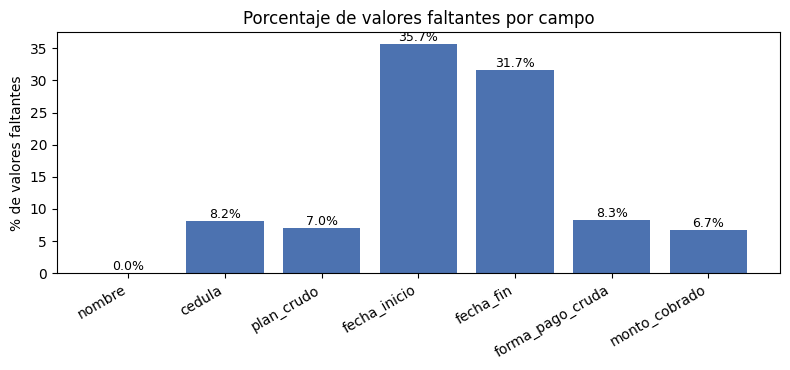

In [17]:
campos_diagnostico = ["nombre", "cedula", "plan_crudo", "fecha_inicio", "fecha_fin",
                      "forma_pago_cruda", "monto_cobrado"]

filas_diagnostico = []
for campo in campos_diagnostico:
    serie = datos_crudos[campo]
    # En campos de texto consideramos faltante tanto el vacío real como el texto "" (cadena vacía)
    if pd.api.types.is_string_dtype(serie) or serie.dtype == object:
        faltante = serie.isna() | serie.astype(str).str.strip().isin(["", "nan", "<NA>"])
    else:
        faltante = serie.isna()
    filas_diagnostico.append({
        "campo": campo,
        "faltante_%": round(100 * faltante.mean(), 1),
        "valores_unicos": serie.nunique(dropna=True),
    })

diagnostico_calidad = pd.DataFrame(filas_diagnostico)
display(diagnostico_calidad)

fig, ax = plt.subplots(figsize=(8, 3.8))
barras = ax.bar(diagnostico_calidad["campo"], diagnostico_calidad["faltante_%"], color="#4C72B0")
ax.bar_label(barras, fmt="%.1f%%", fontsize=9)
ax.set_title("Porcentaje de valores faltantes por campo")
ax.set_ylabel("% de valores faltantes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

#### Interpretación de los resultados


- **Fechas de inicio y fin** son los campos con más faltantes (alrededor de un tercio). Esto es crítico porque sin fecha de fin **no se puede saber cuándo vence** una membresía; esos ciclos no podrán evaluarse.
- **Cédula** falta en cerca del 8 %: será necesario un respaldo por nombre para identificar al socio.
- **Plan** tiene **281 formas distintas** de escribirse, aunque en realidad son unas pocas categorías. Se corrige en la Parte 4.

Este diagnóstico coincide con la causa "**Datos**" del diagrama de Ishikawa del documento final.

---
# Parte 4 · Estandarización: socios, planes y formas de pago

## Sección 4.1 · Normalización de nombres

**Descripción.** Cada nombre se convierte a mayúsculas, sin tildes, sin números ni signos, y con espacios simples. Luego se descartan los registros cuyo nombre queda con menos de 5 letras.

**Justificación.** "José Pérez", "JOSE PEREZ" y "jose  perez " son la misma persona. Si no se normalizan, el sistema creería que son tres socios distintos y su historial quedaría partido. Los nombres de menos de 5 letras suelen ser textos operativos o números, no personas.

**Objetivo.** tener un nombre comparable que sirva de respaldo para identificar al socio.

In [18]:
def normalizar_nombre(texto):
    texto = "" if pd.isna(texto) else str(texto)
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()  # quita tildes
    texto = texto.upper()
    texto = re.sub(r"[^A-Z ]", " ", texto)       # conserva solo letras y espacios
    texto = re.sub(r"\s+", " ", texto).strip()   # espacios simples
    return texto

datos_crudos["nombre_normalizado"] = datos_crudos["nombre"].apply(normalizar_nombre)
datos_crudos["identidad_utilizable"] = datos_crudos["nombre_normalizado"].str.len() >= 5

print("Registros antes del control de identidad:", len(datos_crudos))
print("Registros con identidad utilizable:     ", datos_crudos["identidad_utilizable"].sum())
print("Registros excluidos por identidad insuficiente:", (~datos_crudos["identidad_utilizable"]).sum())

datos_crudos = datos_crudos.loc[datos_crudos["identidad_utilizable"]].copy()

Registros antes del control de identidad: 2771
Registros con identidad utilizable:      2748
Registros excluidos por identidad insuficiente: 23


#### Interpretación de los resultados

De 2.771 registros quedan **2.748** con identidad utilizable (se excluyen 23). Cifra idéntica a la del documento final y del Informe S5.

## Sección 4.2 · Depuración de la cédula

**Descripción.** De la cédula se extraen solo los dígitos. Se acepta como identificador si tiene al menos 9 dígitos; si no (por ejemplo, cuando dice "RENOVACIÓN"), se deja vacía.

**Justificación.** La cédula es el identificador más confiable de una persona, pero en los Excel a veces contiene texto o números incompletos.

**Objetivo.** obtener un identificador numérico confiable **solo para reconocer a la persona**.

**Criterio ético (minimización de datos):** la cédula, el nombre, el celular y el correo **nunca** se usan para calcular el riesgo. Solo sirven para saber qué registros pertenecen al mismo socio.

In [19]:
def normalizar_cedula(valor):
    if pd.isna(valor):
        return np.nan
    digitos = re.sub(r"\D", "", str(valor))   # \D = todo lo que NO es dígito; se elimina
    return digitos if len(digitos) >= 9 else np.nan

datos_crudos["cedula_normalizada"] = datos_crudos["cedula"].apply(normalizar_cedula)

print("Registros identificados por cédula:            ", datos_crudos["cedula_normalizada"].notna().sum())
print("Registros que necesitarán respaldo por nombre: ", datos_crudos["cedula_normalizada"].isna().sum())

Registros identificados por cédula:             2129
Registros que necesitarán respaldo por nombre:  619


## Sección 4.3 · Identidad única de cada socio (`socio_id`)

**Descripción.** Se asigna un código a cada persona con una regla simple:
- si hay cédula válida → `C:` + cédula;
- si no la hay → `N:` + nombre normalizado.

**Justificación.** Para reconstruir la historia de cada socio: cuántas membresías tuvo, cuándo, cuánto pagó. Sin una identidad única no se puede saber si alguien **volvió** (renovó).

**Objetivo.** unir todos los registros de una misma persona bajo un mismo código.

In [20]:
datos_crudos["socio_id"] = np.where(
    datos_crudos["cedula_normalizada"].notna(),
    "C:" + datos_crudos["cedula_normalizada"].fillna(""),   # identidad por cédula
    "N:" + datos_crudos["nombre_normalizado"],              # respaldo por nombre
)
print("Socios distintos identificados:", datos_crudos["socio_id"].nunique())

Socios distintos identificados: 1410


#### Interpretación de los resultados

Esta regla identifica **1.410 socios**. El documento final y el Informe S5 reportan **1.474**. La diferencia se explica porque aquella versión usaba una regla de identidad distinta (combinaba cédula y nombre de otra manera). Ninguna de las dos es "incorrecta", pero **el documento y el código deben usar la misma regla**. En la Parte 15 se presenta la tabla completa de reconciliación.

## Sección 4.4 · Duración de cada membresía

**Descripción.** Se resta: `fecha_fin − fecha_inicio` = días de duración.

**Justificación.** La duración sirve para (1) reconocer el tipo de plan cuando el texto está mal escrito y (2) detectar registros imposibles (por ejemplo, una membresía de 2 días o de 3 años).

**Objetivo.** tener una medida objetiva del largo de cada ciclo.

In [21]:
datos_crudos["duracion_dias"] = (datos_crudos["fecha_fin"] - datos_crudos["fecha_inicio"]).dt.days
display(datos_crudos[["fecha_inicio", "fecha_fin", "duracion_dias"]].head(8))

,fecha_inicio,fecha_fin,duracion_dias
0,2025-01-06,2025-02-06,31.0
1,2025-01-06,2025-06-06,151.0
2,2025-01-06,2026-01-05,364.0
3,2025-01-06,2026-01-05,364.0
4,2025-01-06,2025-02-05,30.0
5,2025-01-06,2026-01-05,364.0
6,2025-01-08,2026-01-07,364.0
7,NaT,NaT,NaN


## Sección 4.5 · Normalización del tipo de plan (de 281 variantes a 6 categorías)

**Descripción.** Primero se observa cómo está escrito el plan; luego se agrupan las variantes en: **MENSUAL, TRIMESTRAL, SEMESTRAL, ANUAL, DIARIO y OTRO**.

**Justificación.** "3 MESES", "PROMO 3 MESES", "TRES MESES", "TRESMESES", "TRIMESTRE PROMO" significan lo mismo. Un modelo no puede aprender de 281 categorías con pocos casos cada una. Además, en varios registros el campo "plan" contiene por error una **forma de pago** (DATAFAST, TRANSFERENCIA).

**Objetivo.** tener un catálogo de planes limpio y comprensible.

**Regla de clasificación (en orden):**
1. Si el texto contiene una forma de pago, se ignora el texto.
2. Se buscan palabras clave: DIARIO, ANUAL/AÑO, SEMESTR/6 MES, 3 MES/TRES MES/TRIMEST, MENSUAL/1 MES.
3. Si el texto no alcanza, se usa la duración: 21–45 días → mensual; 80–130 → trimestral; 160–200 → semestral; 330–400 → anual.
4. Si nada funciona → OTRO.

In [22]:
conteo_planes_crudos = (datos_crudos["plan_crudo"].value_counts(dropna=False)
                        .rename_axis("plan_crudo").reset_index(name="cantidad"))
print("Cantidad de formas distintas de escribir el plan:", datos_crudos["plan_crudo"].nunique())
display(conteo_planes_crudos.head(15))

Cantidad de formas distintas de escribir el plan: 281


,plan_crudo,cantidad
0,MENSUAL,1195
1,DATAFAST,336
2,,171
3,3 MESES,110
4,PROMO 3 MESES,97
5,TRES MESES,50
6,DIARIO,48
7,ANUAL,46
8,PROMO 3 M,41
9,TRIMESTRE PROMO,26


In [23]:
FORMAS_PAGO_EN_CAMPO_PLAN = ("DATAFAST", "TRANSF", "EFECTIVO", "TARJETA", "DEPOSITO")

def normalizar_plan(texto, duracion):
    texto = str(texto or "").upper().strip()
    if any(pago in texto for pago in FORMAS_PAGO_EN_CAMPO_PLAN):   # regla 1: era una forma de pago
        texto = ""
    # regla 2: palabras clave
    if "DIARIO" in texto:
        return "DIARIO"
    if "ANUAL" in texto or "AÑO" in texto or "ANO" in texto:
        return "ANUAL"
    if "SEMESTR" in texto or "6 MES" in texto:
        return "SEMESTRAL"
    if any(x in texto for x in ("3 MES", "TRES MES", "TRIMEST")):
        return "TRIMESTRAL"
    if "MENSUAL" in texto or re.search(r"\b1\s*MES\b", texto) or "PLAN MES" in texto:
        return "MENSUAL"
    # regla 3: usar la duración observada
    if pd.notna(duracion):
        if 21 <= duracion <= 45:   return "MENSUAL"
        if 80 <= duracion <= 130:  return "TRIMESTRAL"
        if 160 <= duracion <= 200: return "SEMESTRAL"
        if 330 <= duracion <= 400: return "ANUAL"
    return "OTRO"                                                  # regla 4

datos_crudos["plan"] = [normalizar_plan(t, d) for t, d in
                        zip(datos_crudos["plan_crudo"], datos_crudos["duracion_dias"])]

print("Registros donde el campo plan contenía una forma de pago:",
      datos_crudos["plan_crudo"].str.contains("|".join(FORMAS_PAGO_EN_CAMPO_PLAN)).sum())
display(datos_crudos["plan"].value_counts().rename_axis("plan").reset_index(name="cantidad"))

Registros donde el campo plan contenía una forma de pago: 344


,plan,cantidad
0,MENSUAL,1388
1,OTRO,607
2,TRIMESTRAL,524
3,ANUAL,119
4,SEMESTRAL,56
5,DIARIO,54


#### Interpretación de los resultados

El plan **MENSUAL** domina, seguido de **TRIMESTRAL**. La categoría **OTRO** es grande porque muchos registros no tienen ni texto de plan útil ni fechas para calcular su duración; muchos de ellos se excluirán luego por no tener fecha de vencimiento. Los planes **ANUAL** y **SEMESTRAL** tienen pocos casos, por lo que los resultados del modelo para esos segmentos deben tomarse con cautela (limitación ya señalada en el Informe S5).

## Sección 4.6 · Normalización de la forma de pago

**Descripción.** Las más de 500 formas de escribir el pago se agrupan en: **TRANSFERENCIA, EFECTIVO, TARJETA_DATAFAST, OTRO, SIN_DATO**.

**Justificación.** "TRANSF DINERS", "TRANSFEF DINERS", "TRANSACCION PICHINCHA" son todas transferencias. Agrupar permite que el modelo detecte si el medio de pago se relaciona con la renovación.

**Objetivo.** una variable de pago limpia y útil para el modelo.

In [24]:
def normalizar_forma_pago(texto):
    texto = str(texto or "").upper()
    if not texto.strip():
        return "SIN_DATO"
    if "EFECT" in texto:
        return "EFECTIVO"
    if "DATAFAST" in texto or "TARJ" in texto:
        return "TARJETA_DATAFAST"
    if any(x in texto for x in ("TRANS", "PICH", "PROD", "DINERS", "INTER")):   # bancos y transferencias
        return "TRANSFERENCIA"
    return "OTRO"

datos_crudos["forma_pago"] = datos_crudos["forma_pago_cruda"].apply(normalizar_forma_pago)
display(datos_crudos["forma_pago"].value_counts().rename_axis("forma_pago").reset_index(name="cantidad"))

,forma_pago,cantidad
0,TRANSFERENCIA,1540
1,OTRO,443
2,EFECTIVO,400
3,SIN_DATO,209
4,TARJETA_DATAFAST,156


---
# Parte 5 · Definir la variable objetivo: ¿renovó o no renovó?

Esta es la parte **más importante conceptualmente**. Un modelo solo puede aprender lo que se le enseña; si la definición de "no renovó" está mal, todo lo demás estará mal, aunque el código funcione perfectamente.

## Sección 5.1 · Fecha de corte de los datos

**Descripción.** Se toma el último mes disponible (agosto 2026) y se fija como fecha de corte su último día: **31 de agosto de 2026**.

**Justificación.** Todo lo que ocurra después de esta fecha es desconocido para nosotros. Sirve para saber qué ciclos ya pueden evaluarse y cuáles todavía no.

**Objetivo.** tener una referencia temporal explícita y calculada desde los datos.

In [25]:
ultimo_mes_disponible = datos_crudos["mes_hoja"].max()
fecha_corte_datos = ultimo_mes_disponible + pd.offsets.MonthEnd(0)   # último día de ese mes

# Fecha límite para observar una renovación: T + 30 días
datos_crudos["fecha_limite_observacion"] = datos_crudos["fecha_fin"] + pd.to_timedelta(DIAS_OBSERVACION, unit="D")

print("Último mes disponible:", ultimo_mes_disponible.strftime("%Y-%m"))
print("Fecha de corte de datos:", fecha_corte_datos.date())

Último mes disponible: 2026-08
Fecha de corte de datos: 2026-08-31


## Sección 5.2 · Verificación del ejemplo planteado por el tutor

**Descripción.** Se programa exactamente el caso planteado en la retroalimentación: vencimiento el 20 de agosto.

**Justificación.** Para demostrar que la regla está **implementada en el código**, no solo descrita en el texto.

**Objetivo.** que el notebook concluya por sí mismo "Todavía no se puede confirmar la no renovación".

In [26]:
ejemplo_docente = pd.DataFrame([{
    "Situación": "Vencimiento de la membresía", "Ejemplo": pd.Timestamp("2026-08-20").date()},
    {"Situación": "Fecha hasta la que deben observarse renovaciones (T+30)",
     "Ejemplo": (pd.Timestamp("2026-08-20") + pd.Timedelta(days=DIAS_OBSERVACION)).date()},
    {"Situación": "Último día disponible en los archivos", "Ejemplo": fecha_corte_datos.date()},
])
limite = pd.Timestamp("2026-08-20") + pd.Timedelta(days=DIAS_OBSERVACION)
conclusion = ("Ya puede determinarse el resultado" if limite <= fecha_corte_datos
              else "Todavía no se puede confirmar la no renovación")
ejemplo_docente.loc[len(ejemplo_docente)] = ["Conclusión válida (calculada por el código)", conclusion]
display(ejemplo_docente)

,Situación,Ejemplo
0,Vencimiento de la membresía,2026-08-20
1,Fecha hasta la que deben observarse renovaciones (T+30),2026-09-19
2,Último día disponible en los archivos,2026-08-31
3,Conclusión válida (calculada por el código),Todavía no se puede confirmar la no renovación


## Sección 5.3 · Clasificación de ciclos: evaluable, pendiente o excluido

**Descripción.** Cada registro recibe un **estado** según reglas aplicadas en orden:

| Orden | Condición | Estado | Por qué |
|---|---|---|---|
| 1 | No tiene fecha de vencimiento | EXCLUIDO | No se sabe cuándo vence. |
| 2 | Vence antes de dic-2024 | EXCLUIDO | Fecha fuera del período (error de digitación). |
| 3 | Vence después del 31-ago-2026 | EXCLUIDO | Aún no ocurre el vencimiento dentro de los datos. |
| 4 | Es un pase diario | EXCLUIDO | No es una membresía que se renueve. |
| 5 | Dura ≤ 21 días o > 400 días | EXCLUIDO | Duración imposible → error de dato. |
| 6 | T+30 cae después del 31-ago-2026 | **PENDIENTE** | El dato es válido, pero aún no pasaron los 30 días. |
| 7 | Todo lo demás | **EVALUABLE** | Se puede saber si renovó. |

**Justificación.** Para separar dos cosas muy distintas: un **problema de calidad del dato** (excluido) y una **observación todavía incompleta** (pendiente). **Un caso pendiente nunca es una no renovación.**

**Objetivo.** que cada exclusión tenga un motivo registrado y auditable.

,estado,registros,porcentaje
0,EVALUABLE,1564,56.9
1,EXCLUIDO - Sin fecha de vencimiento,855,31.1
2,EXCLUIDO - Vencimiento posterior al período disponible,160,5.8
3,PENDIENTE - Ventana T+30 incompleta,96,3.5
4,EXCLUIDO - Duración implausible,49,1.8
5,EXCLUIDO - Pase diario,16,0.6
6,EXCLUIDO - Fecha fuera de rango,8,0.3


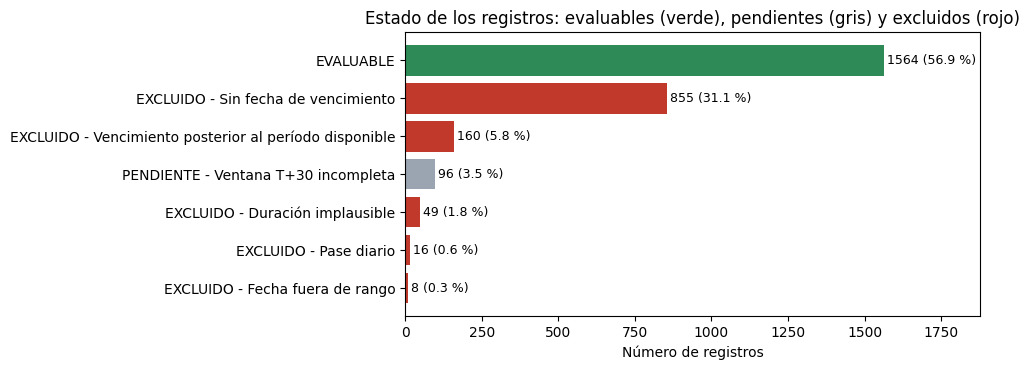

In [27]:
FECHA_MINIMA_RAZONABLE = pd.Timestamp("2024-12-01")

def motivo_estado_ciclo(fila):
    if pd.isna(fila["fecha_fin"]):
        return "EXCLUIDO - Sin fecha de vencimiento"
    if fila["fecha_fin"] < FECHA_MINIMA_RAZONABLE:
        return "EXCLUIDO - Fecha fuera de rango"
    if fila["fecha_fin"] > fecha_corte_datos:
        return "EXCLUIDO - Vencimiento posterior al período disponible"
    if fila["plan"] == "DIARIO":
        return "EXCLUIDO - Pase diario"
    if pd.notna(fila["duracion_dias"]) and (fila["duracion_dias"] <= 21 or fila["duracion_dias"] > 400):
        return "EXCLUIDO - Duración implausible"
    if fila["fecha_limite_observacion"] > fecha_corte_datos:
        return "PENDIENTE - Ventana T+30 incompleta"
    return "EVALUABLE"

datos_crudos["estado_ciclo"] = datos_crudos.apply(motivo_estado_ciclo, axis=1)

trazabilidad = (datos_crudos["estado_ciclo"].value_counts()
                .rename_axis("estado").reset_index(name="registros"))
trazabilidad["porcentaje"] = (100 * trazabilidad["registros"] / len(datos_crudos)).round(1)
display(trazabilidad)

# Gráfico: cuántos registros quedan en cada estado
colores_estado = [COLORES["verde"] if e == "EVALUABLE" else COLORES["gris"] if e.startswith("PENDIENTE")
                  else COLORES["rojo"] for e in trazabilidad["estado"]]
fig, ax = plt.subplots(figsize=(10, 3.8))
t = trazabilidad.iloc[::-1]
ax.barh(t["estado"], t["registros"], color=colores_estado[::-1])
for y_, (r, pc) in enumerate(zip(t["registros"], t["porcentaje"])):
    ax.text(r + 10, y_, f"{r} ({pc:.1f} %)", va="center", fontsize=9)
ax.set_xlabel("Número de registros")
ax.set_title("Estado de los registros: evaluables (verde), pendientes (gris) y excluidos (rojo)")
ax.set_xlim(0, trazabilidad["registros"].max() * 1.2)
plt.tight_layout()
plt.show()

#### Interpretación de los resultados

Cerca del **57 %** de los registros son evaluables. La principal causa de exclusión es la **falta de fecha de vencimiento** (~31 %), lo que confirma que mejorar el registro de fechas en Mtabolic aumentaría directamente la información disponible. Los **96 pendientes** corresponden a membresías que vencen en agosto 2026 y cuya ventana T+30 aún no termina.

## Sección 5.4 · Fecha de actividad y posibles duplicados

**Descripción.**
1. Se define la **fecha de actividad** de cada registro: la fecha de inicio; si falta, el primer día del mes de la hoja (y se marca con una bandera `inicio_aproximado`).
2. Se **cuentan** (sin borrar) las filas que parecen duplicadas.

**Justificación.** La fecha de actividad permite saber **cuándo** apareció una nueva membresía (para detectar renovaciones). Los duplicados se identifican pero no se eliminan automáticamente, porque dos filas parecidas pueden ser movimientos reales distintos; esa regla debe confirmarla Mtabolic.

**Objetivo.** reconstruir la línea de tiempo de cada socio y dejar documentado el posible problema de duplicados.

In [28]:
datos_crudos["inicio_aproximado"] = datos_crudos["fecha_inicio"].isna()                 # bandera de aproximación
datos_crudos["fecha_actividad"] = datos_crudos["fecha_inicio"].fillna(datos_crudos["mes_hoja"])
print("Registros con fecha de inicio aproximada por el mes de la hoja:", datos_crudos["inicio_aproximado"].sum())

columnas_duplicado = ["socio_id", "fecha_actividad", "fecha_fin", "plan", "monto_cobrado"]
duplicados_exactos = datos_crudos.duplicated(subset=columnas_duplicado, keep=False)
print("Filas que participan en un posible duplicado exacto:", duplicados_exactos.sum())

datos = datos_crudos.copy()   # en este MVP conservamos todos los registros

Registros con fecha de inicio aproximada por el mes de la hoja: 966
Filas que participan en un posible duplicado exacto: 73


## Sección 5.5 · Construcción de la variable objetivo (renovación entre T y T+30)

**Descripción.** Para cada ciclo evaluable, se revisa el historial del mismo socio y se busca **otra membresía** (que no sea pase diario) cuya fecha de actividad esté entre el vencimiento (T) y T+30.
- Si se encuentra → **renovó** (`no_renovo = 0`).
- Si no se encuentra → **no renovó** (`no_renovo = 1`).
- Si el ciclo es pendiente o excluido → **sin etiqueta** (vacío).

**Justificación.** Es la "respuesta correcta" que el modelo aprenderá a anticipar. En aprendizaje supervisado, el modelo necesita ejemplos resueltos.

**Objetivo.** crear la variable objetivo `no_renovo` con una definición clara, temporal y reproducible.

In [29]:
# 1) Historial de membresías por socio (sin pases diarios), ordenado por fecha
registros_membresia = datos.loc[datos["plan"].ne("DIARIO") & datos["fecha_actividad"].notna()].copy()
actividades_por_socio = {socio: grupo.sort_values("fecha_actividad")
                         for socio, grupo in registros_membresia.groupby("socio_id")}

# 2) Función que busca una nueva membresía dentro de la ventana [T, T+30]
def buscar_renovacion(fila):
    if fila["estado_ciclo"] != "EVALUABLE":
        return pd.NaT
    historial = actividades_por_socio.get(fila["socio_id"])
    if historial is None:
        return pd.NaT
    inicio_ventana = fila["fecha_fin"] - pd.Timedelta(days=DIAS_RENOVACION_ANTICIPADA)   # T
    fin_ventana = fila["fecha_limite_observacion"]                                         # T+30
    candidatos = historial.loc[
        (historial.index != fila.name)                         # que no sea el mismo registro
        & (historial["fecha_actividad"] >= inicio_ventana)
        & (historial["fecha_actividad"] <= fin_ventana)
    ]
    return pd.NaT if candidatos.empty else candidatos["fecha_actividad"].min()

# 3) Aplicar a todos los registros y crear la etiqueta 0/1
datos["fecha_renovacion_detectada"] = datos.apply(buscar_renovacion, axis=1)
datos["no_renovo"] = np.nan
es_evaluable = datos["estado_ciclo"].eq("EVALUABLE")
datos.loc[es_evaluable & datos["fecha_renovacion_detectada"].notna(), "no_renovo"] = 0   # renovó
datos.loc[es_evaluable & datos["fecha_renovacion_detectada"].isna(), "no_renovo"] = 1    # no renovó

# 4) Traducir a palabras
def nombre_resultado(fila):
    if fila["estado_ciclo"].startswith("PENDIENTE"): return "Pendiente de observación"
    if fila["estado_ciclo"].startswith("EXCLUIDO"):  return "No evaluable"
    return "No renovó" if fila["no_renovo"] == 1 else "Renovó"

datos["resultado_real"] = datos.apply(nombre_resultado, axis=1)
display(datos["resultado_real"].value_counts().rename_axis("resultado").reset_index(name="cantidad"))

n_eval = int(datos["no_renovo"].notna().sum()); n_nr = int((datos["no_renovo"] == 1).sum())
print(f"Tasa de no renovación sobre ciclos evaluables: {n_nr}/{n_eval} = {100*n_nr/n_eval:.1f}%")

,resultado,cantidad
0,No renovó,1098
1,No evaluable,1088
2,Renovó,466
3,Pendiente de observación,96


Tasa de no renovación sobre ciclos evaluables: 1098/1564 = 70.2%


#### Interpretación de los resultados

De los ciclos evaluables, aproximadamente **7 de cada 10 no renovaron** dentro de los 30 días. Es una proporción alta y tiene una consecuencia importante que se explica en la Parte 10: **un sistema que diga "todos se van" acertaría la mayoría de las veces sin analizar nada**. Por eso todo modelo debe compararse contra esa referencia (el "piso").

---
# Parte 6 · Análisis mes a mes del fenómeno de no renovación

*Responde a la observación del tutor: "Realicen un análisis mes a mes".*

## Sección 6.1 · Vencimientos, renovaciones y pendientes por mes

**Descripción.** Para cada mes de vencimiento se cuentan: ciclos que vencieron, cuántos ya se pueden evaluar, cuántos siguen pendientes, cuántos renovaron y cuántos no. La tasa de no renovación se calcula **solo con los resultados conocidos**.

**Justificación.** Un promedio global puede ocultar cambios en el tiempo (temporadas, promociones, cambios de política). Además, muestra con claridad que el último mes está casi todo **pendiente**.

**Objetivo.** entender la evolución del fenómeno y construir el indicador mensual de no renovación que hoy Mtabolic no tiene.

In [30]:
datos["mes_vencimiento"] = datos["fecha_fin"].dt.to_period("M").astype("string")

# Solo ciclos con calidad suficiente (evaluables + pendientes); los excluidos se reportan aparte
datos_mensuales_validos = datos.loc[~datos["estado_ciclo"].str.startswith("EXCLUIDO")].copy()

resumen_mensual = (datos_mensuales_validos.groupby("mes_vencimiento").agg(
    ciclos=("socio_id", "size"),
    evaluables=("estado_ciclo", lambda s: (s == "EVALUABLE").sum()),
    pendientes=("estado_ciclo", lambda s: s.str.startswith("PENDIENTE").sum()),
    renovaron=("no_renovo", lambda s: (s == 0).sum()),
    no_renovaron=("no_renovo", lambda s: (s == 1).sum()),
).reset_index())

resumen_mensual["tasa_no_renovacion_%"] = (
    100 * resumen_mensual["no_renovaron"] / resumen_mensual["evaluables"].replace(0, np.nan)).round(1)
display(resumen_mensual)

,mes_vencimiento,ciclos,evaluables,pendientes,renovaron,no_renovaron,tasa_no_renovacion_%
0,2025-02,43,43,0,13,30,69.8
1,2025-03,43,43,0,3,40,93.0
2,2025-04,28,28,0,4,24,85.7
3,2025-05,31,31,0,0,31,100.0
4,2025-06,54,54,0,10,44,81.5
5,2025-07,116,116,0,26,90,77.6
6,2025-08,132,132,0,35,97,73.5
7,2025-09,143,143,0,40,103,72.0
8,2025-10,131,131,0,46,85,64.9
9,2025-11,119,119,0,37,82,68.9


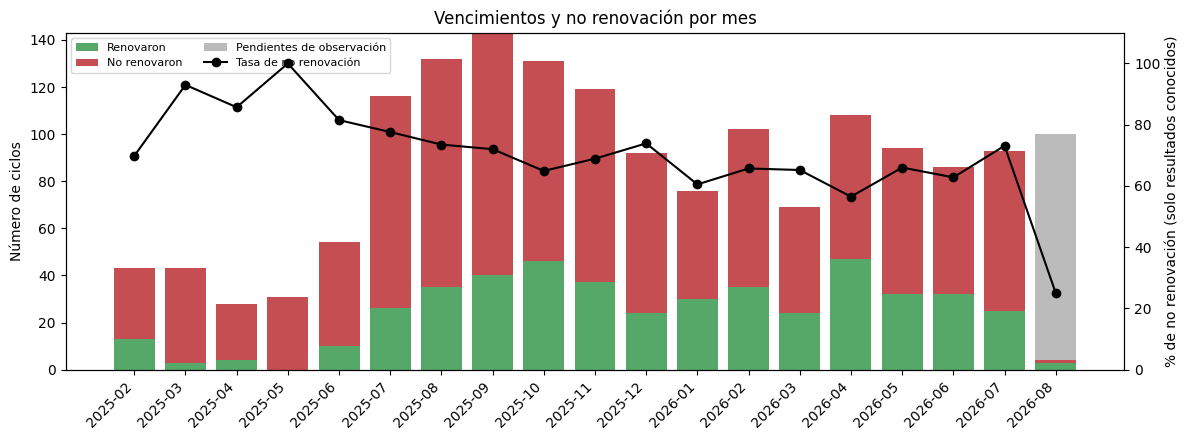

In [31]:
fig, ax1 = plt.subplots(figsize=(12, 4.5))
x = resumen_mensual["mes_vencimiento"]

# Barras apiladas: cuántos renovaron, no renovaron y siguen pendientes cada mes
ax1.bar(x, resumen_mensual["renovaron"], label="Renovaron", color="#55A868")
ax1.bar(x, resumen_mensual["no_renovaron"], bottom=resumen_mensual["renovaron"],
        label="No renovaron", color="#C44E52")
ax1.bar(x, resumen_mensual["pendientes"],
        bottom=resumen_mensual["renovaron"] + resumen_mensual["no_renovaron"],
        label="Pendientes de observación", color="#BBBBBB")
ax1.set_ylabel("Número de ciclos")

# Línea: tasa de no renovación (eje derecho)
ax2 = ax1.twinx()
ax2.plot(x, resumen_mensual["tasa_no_renovacion_%"], color="black", marker="o", label="Tasa de no renovación")
ax2.set_ylabel("% de no renovación (solo resultados conocidos)")
ax2.set_ylim(0, 110)

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, ncol=2)
ax1.set_title("Vencimientos y no renovación por mes")
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Interpretación de los resultados


1. **Primeros meses de 2025 (feb–may):** pocos ciclos y tasas muy altas (hasta 100 %). Con tan pocos casos, un solo socio cambia mucho el porcentaje; además, al inicio del historial es más difícil detectar renovaciones porque hay menos registros previos. Se deben leer con cautela.
2. **Jul–dic 2025:** el volumen se estabiliza (90–140 ciclos por mes) y la tasa ronda **65–78 %**.
3. **2026 (ene–jul):** la tasa baja a un rango de **57–73 %**. El comportamiento de los socios **cambió** entre 2025 y 2026. Este cambio es importante porque el modelo aprende de 2025 y se evalúa en 2026 (se analiza en la Parte 12).
4. **Agosto 2026:** casi todo está en gris (**pendiente**). Solo 4 ciclos pueden evaluarse; su tasa (25 %) **no es representativa**. Esto es exactamente lo que pide el ejemplo del tutor: no se declara "no renovado" a quien aún no cumplió su ventana T+30.

In [32]:
# Cambio de comportamiento entre años (solo resultados conocidos)
por_anio = (datos.loc[datos["no_renovo"].notna()]
            .assign(anio_vencimiento=lambda d: d["fecha_fin"].dt.year)
            .groupby("anio_vencimiento")["no_renovo"].agg(ciclos="size", tasa_no_renovacion="mean"))
por_anio["tasa_no_renovacion"] = (100 * por_anio["tasa_no_renovacion"]).round(1).astype(str) + " %"
display(por_anio)

,ciclos,tasa_no_renovacion
anio_vencimiento,,
2025,932,74.5 %
2026,632,63.9 %


---
# Parte 7 · Ingeniería de variables: qué sabe el modelo en T−30

## Sección 7.1 · Información admitida y excluida como predictora

**Descripción.** Se decide la lista de variables predictoras.

**Justificación.** Para evitar dos errores graves:
- **Fuga de información:** usar datos que en la vida real no se conocerían 30 días antes del vencimiento (por ejemplo, si renovó). Haría que el modelo "parezca" excelente en el laboratorio y fracase en la práctica.
- **Uso indebido de datos personales:** el riesgo no debe depender de quién es la persona (nombre, cédula), sino de su relación comercial con el gimnasio.

**Objetivo.** un conjunto de variables legítimo, ético y disponible en el momento de la predicción.

| Se utilizan (conocidas en T−30) | Qué representan | Familia (según la literatura) |
|---|---|---|
| `ciclos_previos` | Cuántas membresías tuvo antes | Permanencia |
| `antiguedad_dias` | Días desde su primera membresía hasta T−30 | Permanencia |
| `duracion_modelo` | Largo del plan actual | Permanencia |
| `dias_desde_ultima_membresia` | Tiempo entre la membresía anterior y la actual | Permanencia / recencia |
| `monto_actual` | Cuánto pagó por el ciclo actual | Valor |
| `monto_historico` | Cuánto pagó en total antes | Valor |
| `plan` | Tipo de plan | Valor |
| `forma_pago` | Medio de pago | Valor |
| `mes_vencimiento` | Mes calendario del vencimiento | Estacionalidad |
| `inicio_aproximado` | Si la fecha de inicio fue aproximada | Calidad del dato |

| NO se utilizan | Motivo |
|---|---|
| nombre, cédula, celular, correo | Datos personales: solo sirven para identificar. |
| `no_renovo`, `fecha_renovacion_detectada` | Son la respuesta: usarlas sería "copiar en el examen". |
| cualquier dato posterior a T−30 | No existiría en el momento real de la predicción. |

**Limitación:** Mtabolic no registra la **asistencia** de los socios, que según la literatura (Sobreiro et al., 2021) es la señal más predictiva del abandono. Las variables de pago y antigüedad la sustituyen parcialmente.

## Sección 7.2 · Momento de predicción y variables históricas

**Descripción.** Se calcula la fecha de predicción (T−30) y, para cada ciclo, se resume la historia **previa** del socio: cuántas membresías tuvo antes, cuánto pagó, hace cuánto fue la última y desde cuándo es cliente.

**Justificación.** El pasado de un cliente suele anticipar su comportamiento futuro (un cliente fiel con varias renovaciones tiende a seguir renovando).

**Objetivo.** convertir el historial en números que el modelo pueda usar, **mirando solo hacia atrás**.

In [33]:
datos["fecha_prediccion"] = datos["fecha_fin"] - pd.to_timedelta(DIAS_ANTES_PREDICCION, unit="D")   # T-30

# Ciclos con calidad suficiente (evaluables + pendientes)
datos_modelables = (datos.loc[~datos["estado_ciclo"].str.startswith("EXCLUIDO")]
                    .copy().sort_values(["socio_id", "fecha_actividad", "fecha_fin"]))
historial_por_socio = {socio: grupo for socio, grupo in datos_modelables.groupby("socio_id")}
print("Ciclos con calidad suficiente para construir variables:", len(datos_modelables))

def resumir_historial_previo(indice, fila):
    historial = historial_por_socio[fila["socio_id"]]
    # SOLO registros del mismo socio que ocurrieron ANTES del ciclo actual (nunca después)
    previos = historial.loc[(historial.index != indice) & (historial["fecha_actividad"] < fila["fecha_actividad"])]

    ciclos_previos = len(previos)
    monto_historico = previos["monto_cobrado"].fillna(0).sum()
    if previos.empty:                       # socio nuevo: no hay membresía anterior
        dias_desde_ultima = np.nan
        primera_fecha = fila["fecha_actividad"]
    else:
        dias_desde_ultima = (fila["fecha_actividad"] - previos["fecha_actividad"].max()).days
        primera_fecha = min(previos["fecha_actividad"].min(), fila["fecha_actividad"])
    antiguedad_dias = max(0, (fila["fecha_prediccion"] - primera_fecha).days)   # medida en T-30

    return pd.Series({"ciclos_previos": ciclos_previos, "monto_historico": monto_historico,
                      "dias_desde_ultima_membresia": dias_desde_ultima, "antiguedad_dias": antiguedad_dias})

variables_historia = pd.DataFrame([resumir_historial_previo(i, f) for i, f in datos_modelables.iterrows()])
variables_historia.index = datos_modelables.index
datos_modelables = datos_modelables.join(variables_historia)

display(datos_modelables[["ciclos_previos", "antiguedad_dias", "monto_historico",
                          "dias_desde_ultima_membresia"]].describe().round(1))

Ciclos con calidad suficiente para construir variables: 1660


,ciclos_previos,antiguedad_dias,monto_historico,dias_desde_ultima_membresia
count,1660.0,1660.0,1660.0,658.0
mean,0.9,84.1,40.7,75.7
std,1.7,110.4,69.7,67.9
min,0.0,0.0,0.0,1.0
25%,0.0,1.0,0.0,31.0
50%,0.0,58.0,0.0,43.0
75%,1.0,120.2,69.0,98.8
max,13.0,571.0,507.0,532.0


## Sección 7.3 · Tratamiento de montos y duraciones faltantes

**Descripción.**
- **Monto:** si falta, se usa la **mediana** del mismo tipo de plan; si aún falta, la mediana general.
- **Duración:** si falta, se usa la duración estándar del plan (mensual 30, trimestral 90, semestral 180, anual 365).

**Justificación.** Eliminar todos los ciclos con un dato faltante reduciría mucho la base. La mediana es un valor "típico" que no se distorsiona con montos extremos (a diferencia del promedio).

**Objetivo.** conservar la mayor cantidad de ciclos sin inventar información engañosa. La duración estándar se usa **solo como variable del modelo**; nunca se inventa una fecha de vencimiento.

In [34]:
mediana_por_plan = datos_modelables.groupby("plan")["monto_cobrado"].median()
mediana_general = datos_modelables["monto_cobrado"].median()

datos_modelables["monto_actual"] = datos_modelables["monto_cobrado"]
faltan = datos_modelables["monto_actual"].isna()
datos_modelables.loc[faltan, "monto_actual"] = datos_modelables.loc[faltan, "plan"].map(mediana_por_plan)
datos_modelables["monto_actual"] = datos_modelables["monto_actual"].fillna(mediana_general)

DURACION_ESTANDAR = {"MENSUAL": 30, "TRIMESTRAL": 90, "SEMESTRAL": 180, "ANUAL": 365, "OTRO": 30}
datos_modelables["duracion_modelo"] = datos_modelables["duracion_dias"].fillna(
    datos_modelables["plan"].map(DURACION_ESTANDAR))

print("Montos completados con la mediana:", int(faltan.sum()))
print("Mediana de monto por plan (USD):")
display(mediana_por_plan.round(2).to_frame("mediana_USD"))

Montos completados con la mediana: 23
Mediana de monto por plan (USD):


,mediana_USD
plan,
ANUAL,250.00
MENSUAL,39.00
OTRO,65.00
SEMESTRAL,174.63
TRIMESTRAL,90.00


## Sección 7.4 · Variables finales del modelo

**Descripción.** Se separan las variables en **numéricas** (cantidades) y **categóricas** (etiquetas).

**Justificación.** Cada tipo necesita un tratamiento diferente antes de entrar al modelo (Parte 9).

**Objetivo.** dejar declarado explícitamente qué entra al modelo.

In [35]:
VARIABLES_NUMERICAS = ["ciclos_previos", "antiguedad_dias", "duracion_modelo",
                       "monto_actual", "monto_historico", "dias_desde_ultima_membresia"]
VARIABLES_CATEGORICAS = ["plan", "forma_pago", "mes_vencimiento", "inicio_aproximado"]
VARIABLES_MODELO = VARIABLES_NUMERICAS + VARIABLES_CATEGORICAS

# Las categóricas se guardan como texto simple (tipo "object") para que scikit-learn las procese sin problemas
for c in VARIABLES_CATEGORICAS:
    datos_modelables[c] = datos_modelables[c].astype(str).astype(object)

display(pd.DataFrame({"variable": VARIABLES_MODELO,
                      "tipo": ["Numérica" if v in VARIABLES_NUMERICAS else "Categórica" for v in VARIABLES_MODELO]}))

,variable,tipo
0,ciclos_previos,Numérica
1,antiguedad_dias,Numérica
2,duracion_modelo,Numérica
3,monto_actual,Numérica
4,monto_historico,Numérica
5,dias_desde_ultima_membresia,Numérica
6,plan,Categórica
7,forma_pago,Categórica
8,mes_vencimiento,Categórica
9,inicio_aproximado,Categórica


---
# Parte 8 · Separar el pasado del futuro: entrenamiento, validación y prueba

## Sección 8.1 · Conjunto analítico (solo ciclos con resultado conocido)

**Descripción.** Se toman únicamente los ciclos **evaluables** (con etiqueta 0 o 1).

**Justificación.** Para aprender y para calificar al modelo necesitamos conocer la respuesta real. Los **pendientes** no entran al entrenamiento ni a las métricas, pero sí recibirán una predicción en las listas mensuales (Parte 13).

**Objetivo.** construir la base de aprendizaje.

In [36]:
analitico = datos_modelables.loc[datos_modelables["no_renovo"].notna()].copy()
analitico["no_renovo"] = analitico["no_renovo"].astype(int)
print("Ciclos disponibles para aprendizaje y evaluación:", len(analitico))
print(f"Tasa global de no renovación: {100 * analitico['no_renovo'].mean():.1f}%")

Ciclos disponibles para aprendizaje y evaluación: 1564
Tasa global de no renovación: 70.2%


## Sección 8.2 · Partición cronológica

**Descripción.** Se divide la información **por fechas de vencimiento**, no al azar:

| Conjunto | Período | Función | Analogía |
|---|---|---|---|
| **Entrenamiento** | feb – dic 2025 | El modelo aprende patrones. | Estudiar con exámenes resueltos. |
| **Validación** | ene – abr 2026 | Se comparan modelos y se elige el umbral. | Simulacro de examen. |
| **Prueba** | may – ago 2026 | Se mide el desempeño final **una sola vez**. | El examen final. |

**Justificación.** En la vida real, el modelo se entrena con el pasado y se usa en el futuro. Si se mezclaran meses al azar, el modelo podría "ver" información de 2026 al aprender y su desempeño se inflaría. Muchos estudios de churn cometen este error (el documento final lo señala en el caso EightGym).

**Criterio metodológico:** el conjunto de prueba **no se utiliza para ninguna decisión**. Si se usara para elegir el modelo, dejaría de ser una evaluación independiente.

**Objetivo.** reproducir las condiciones reales de uso y obtener una medición honesta.

,particion,ciclos,no_renovaciones,prevalencia_pct,desde,hasta
0,1_entrenamiento,932,694,74.5,2025-02-05,2025-12-30
1,2_validacion,355,219,61.7,2026-01-01,2026-04-30
2,3_prueba,277,185,66.8,2026-05-02,2026-08-01


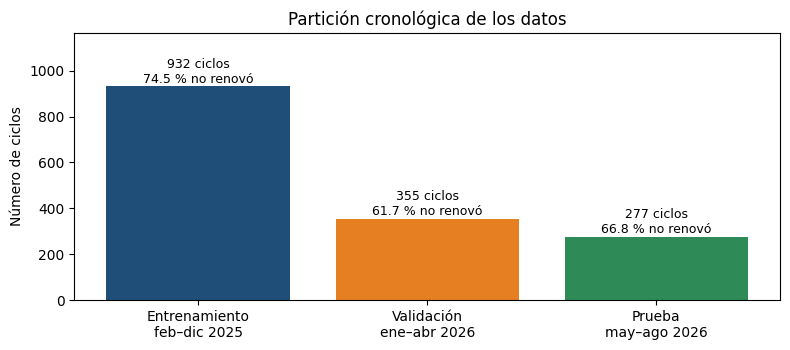

In [37]:
def asignar_particion(fecha_fin):
    if fecha_fin < pd.Timestamp("2026-01-01"):
        return "1_entrenamiento"
    if fecha_fin < pd.Timestamp("2026-05-01"):
        return "2_validacion"
    return "3_prueba"

analitico["particion"] = analitico["fecha_fin"].apply(asignar_particion)

resumen_particiones = analitico.groupby("particion").agg(
    ciclos=("no_renovo", "size"),
    no_renovaciones=("no_renovo", "sum"),
    prevalencia_pct=("no_renovo", "mean"),
    desde=("fecha_fin", "min"),
    hasta=("fecha_fin", "max"),
).reset_index()
resumen_particiones["prevalencia_pct"] = (100 * resumen_particiones["prevalencia_pct"]).round(1)
display(resumen_particiones)

# Gráfico: tamaño de cada conjunto y su porcentaje de no renovación
fig, ax = plt.subplots(figsize=(8, 3.6))
nombres = ["Entrenamiento\nfeb–dic 2025", "Validación\nene–abr 2026", "Prueba\nmay–ago 2026"]
ax.bar(nombres, resumen_particiones["ciclos"], color=[COLORES["azul"], COLORES["naranja"], COLORES["verde"]])
for i, (c, pv) in enumerate(zip(resumen_particiones["ciclos"], resumen_particiones["prevalencia_pct"])):
    ax.text(i, c + 15, f"{c} ciclos\n{pv:.1f} % no renovó", ha="center", fontsize=9)
ax.set_ylim(0, resumen_particiones["ciclos"].max() * 1.25)
ax.set_ylabel("Número de ciclos")
ax.set_title("Partición cronológica de los datos")
plt.tight_layout()
plt.show()

#### Interpretación de los resultados

La **prevalencia** (porcentaje de no renovación) es **74,5 %** en entrenamiento, **61,7 %** en validación y **66,8 %** en prueba. Esto confirma el cambio de comportamiento visto en la Parte 6: el modelo aprende de un período en el que la gente renovaba menos que en el período donde se evalúa. Es un reto real, y la partición cronológica lo hace visible en lugar de esconderlo.

In [38]:
# X = variables que el modelo puede ver;  y = respuesta real que debe aprender
train      = analitico.loc[analitico["particion"] == "1_entrenamiento"].copy()
validation = analitico.loc[analitico["particion"] == "2_validacion"].copy()
test       = analitico.loc[analitico["particion"] == "3_prueba"].copy()

X_train, y_train           = train[VARIABLES_MODELO], train["no_renovo"]
X_validation, y_validation = validation[VARIABLES_MODELO], validation["no_renovo"]
X_test, y_test             = test[VARIABLES_MODELO], test["no_renovo"]

print(f"Entrenamiento: {len(X_train)} | Validación: {len(X_validation)} | Prueba: {len(X_test)}")

Entrenamiento: 932 | Validación: 355 | Prueba: 277


---
# Parte 9 · Selección y construcción de los modelos

Esta parte explica **por qué** se eligieron estos modelos, **cómo funcionan** por dentro (en lenguaje sencillo) y **qué significa cada ajuste**.

## Sección 9.1 · Tipo de problema y alternativas consideradas

Queremos responder una pregunta de **sí o no** para cada ciclo: *¿este socio no renovará?* En aprendizaje automático esto se llama **clasificación binaria supervisada**:

- **Clasificación binaria:** la respuesta tiene dos valores (1 = no renovó, 0 = renovó).
- **Supervisada:** el modelo aprende de ejemplos pasados cuya respuesta ya conocemos.

Pero a Mtabolic no le basta un "sí/no": necesita **ordenar** a los socios por riesgo. Por eso usamos modelos que entregan una **probabilidad** (entre 0 y 1), no solo una etiqueta. Con la probabilidad se construye la lista priorizada.

**¿Por qué no otras alternativas?** (resumen de lo justificado en el documento final, Sección 2.1)

| Alternativa | Por qué no se usó en este MVP |
|---|---|
| **Análisis de supervivencia** | Modela "cuánto tiempo" permanece un socio. Es válido, pero Mtabolic no registra una fecha explícita de abandono y la necesidad es priorizar, no estimar duración. Puntaje 3,91 vs. 4,58 en la matriz ISO/IEC 25059. |
| **Redes neuronales profundas** | Requieren decenas o cientos de miles de registros (Mena et al., 2024 usaron 480.000 clientes). Aquí hay ~1.500 ciclos: sobreajustarían y serían difíciles de explicar. |
| **XGBoost / Gradient Boosting** | Muy buenos en datos tabulares, pero con más parámetros que ajustar y mayor riesgo de sobreajuste con pocos datos. Quedan como **cuarta alternativa** en el backlog del Informe S5. |

Se eligieron **dos modelos complementarios**, recomendados por la literatura como punto de partida (Lalwani et al., 2022; de Lima Lemos et al., 2022): uno **simple e interpretable** y otro **flexible**. Ambos se comparan contra una **referencia sin inteligencia** (el piso).

## Sección 9.2 · La referencia mínima: el "piso trivial" (Nivel 0)

**Qué es:** un "modelo" que no aprende nada. Siempre responde lo mismo: a todos les asigna la probabilidad promedio de no renovación observada en entrenamiento (≈ 0,745) y, por lo tanto, **marca a todos como "no renovará"**.

**Para qué sirve:** como la mayoría de socios no renueva, este sistema tonto **acierta mucho** sin analizar nada. Si un modelo no supera claramente a este piso, **no aporta valor**, aunque sus números "se vean altos".

**Analogía.** en un examen de verdadero/falso donde el 70 % de las respuestas son "verdadero", un estudiante que marca "verdadero" en todo saca 70/100 sin estudiar. Para demostrar que estudió, tiene que sacar **más** que eso.

## Sección 9.3 · Modelo 1: Regresión Logística

**¿Cómo funciona?** El modelo revisa cada característica del socio (plan, forma de pago, cuántas membresías tuvo antes, etc.) y a cada una le asigna **puntos a favor o en contra** de la no renovación. Por ejemplo, ser socio nuevo suma puntos de riesgo y haber renovado varias veces resta puntos. Luego suma todos esos puntos y los convierte en un porcentaje entre 0 % y 100 %: muchos puntos de riesgo se traducen en un porcentaje alto; pocos puntos, en un porcentaje bajo. Los puntos de cada característica los aprende el modelo a partir de los casos pasados.

**Analogía.** funciona como una **tarjeta de puntaje** de riesgo crediticio: "+ puntos si es socio nuevo, − puntos si ya renovó 3 veces, + puntos si paga en efectivo…". Al final, el puntaje total se traduce en un porcentaje.

> Aunque se llama "regresión", **se usa para clasificar**. El nombre es histórico.

| Ventajas | Desventajas |
|---|---|
| Muy **interpretable**: cada peso dice si la variable aumenta o reduce el riesgo. | Asume relaciones **lineales/aditivas**: no capta bien combinaciones ("socio nuevo **y** plan trimestral **y** pago en efectivo"). |
| Rápida, estable y difícil de sobreajustar. | Si la relación real es compleja, queda corta. |
| Estándar de referencia en la literatura (Hosmer et al., 2013). | Necesita que las variables numéricas estén en escalas comparables. |

**Parámetros utilizados y por qué:**

| Parámetro | Valor | Qué significa | Por qué este valor |
|---|---|---|---|
| `class_weight` | `"balanced"` | Da más peso a la clase minoritaria (los que **sí** renuevan) durante el aprendizaje. | Sin esto, el modelo tendería a decir "no renueva" a todos, como el piso. |
| `max_iter` | 2000 | Número máximo de intentos del algoritmo para encontrar los mejores pesos. | Garantiza que el cálculo termine correctamente. |
| `random_state` | 42 | Semilla fija. | Reproducibilidad. |

## Sección 9.4 · Modelo 2: Random Forest (bosque aleatorio)

**¿Cómo funciona?** Construye **muchos árboles de decisión**. Un árbol de decisión es una secuencia de preguntas de sí/no, por ejemplo:

```
¿Tiene ciclos previos?
 ├── No → ¿Plan trimestral?
 │         ├── Sí → riesgo alto
 │         └── No → riesgo medio
 └── Sí → ¿Pagó más de 100 USD en total?
           ├── Sí → riesgo bajo
           └── No → riesgo medio
```

Un solo árbol es inestable (memoriza casos). El **bosque** entrena 300 árboles, cada uno con una **muestra distinta de socios** y un **subconjunto distinto de variables**, y luego **promedia** sus opiniones (Breiman, 2001).

**Analogía.** en lugar de preguntarle a un solo experto, se consulta a un **comité de 300 asesores**, cada uno con experiencia ligeramente diferente, y se toma el promedio de sus votos. Los errores individuales se compensan.

| Ventajas | Desventajas |
|---|---|
| Capta **relaciones no lineales** y **combinaciones** de variables. | Menos interpretable: no hay un "peso" simple por variable. |
| Robusto ante valores extremos y variables irrelevantes. | Puede **sobreajustar** (memorizar) si se deja crecer sin límites. |
| Muy usado y efectivo en churn con datos tabulares. | Sus probabilidades suelen estar **menos calibradas**. |

**Parámetros utilizados y por qué:**

| Parámetro | Valor | Qué significa | Por qué este valor |
|---|---|---|---|
| `n_estimators` | 300 | Número de árboles del bosque. | Suficientes para que el promedio sea estable; más árboles apenas cambian el resultado. |
| `max_depth` | 6 | Máximo de preguntas encadenadas por árbol. | Limita la complejidad: con ~900 casos de entrenamiento, árboles más profundos memorizarían ruido. |
| `min_samples_leaf` | 20 | Cada "hoja" final debe contener al menos 20 socios. | Evita reglas basadas en 1 o 2 personas. |
| `class_weight` | `"balanced"` | Igual que en la logística. | Compensa que la mayoría no renueva. |
| `random_state` | 42 | Semilla fija. | Reproducibilidad. |

> Estos valores se fijaron **antes** de ver los resultados de prueba, con criterio conservador. No se hizo una búsqueda exhaustiva de hiperparámetros para no "sobreajustar" la validación con tan pocos datos.

## Sección 9.5 · Preprocesamiento de los datos

**Descripción.** Antes de llegar al modelo, cada variable pasa por una transformación:

| Tipo | Paso | Qué hace | Ejemplo |
|---|---|---|---|
| Numérica | **Imputación con mediana** | Rellena vacíos con el valor típico (aprendido **solo** en entrenamiento). | `dias_desde_ultima_membresia` vacío en socios nuevos → mediana. |
| Numérica | **Estandarización** | Lleva las variables numéricas a una escala comparable, para que ninguna pese más solo por usar números más grandes. | Monto en USD (0–500) y ciclos previos (0–10) quedan comparables. |
| Categórica | **Imputación con moda** | Rellena vacíos con la categoría más frecuente. | — |
| Categórica | **One-Hot Encoding** | Convierte cada categoría en una columna 0/1. | `plan = TRIMESTRAL` → `plan_MENSUAL=0, plan_TRIMESTRAL=1, …` |

**Justificación.** Los modelos solo entienden números y no aceptan vacíos. La estandarización es clave para la Regresión Logística (si no, el monto "pesaría" más solo por tener números grandes).

**Objetivo.** que ambos modelos reciban **exactamente la misma información**, preparada de forma correcta y sin fuga.

**¿Qué es un `Pipeline`?** Es una **línea de producción**: los datos entran por un extremo, pasan por cada estación (imputar → escalar/codificar → modelo) y sale la probabilidad. Ventaja: las transformaciones se "aprenden" solo con entrenamiento y se aplican idénticas a validación, prueba y a los datos futuros. Así se evita la fuga de información y los errores manuales.

In [39]:
def crear_preprocesador():
    # Estación para variables numéricas: rellenar vacíos con la mediana y estandarizar
    pipeline_numerico = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    # Estación para variables categóricas: rellenar con la categoría más frecuente y crear columnas 0/1
    pipeline_categorico = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),   # si aparece una categoría nueva, no falla
    ])
    return ColumnTransformer([
        ("numericas", pipeline_numerico, VARIABLES_NUMERICAS),
        ("categoricas", pipeline_categorico, VARIABLES_CATEGORICAS),
    ])

# Modelo 1: preprocesamiento + Regresión Logística
modelo_logistico = Pipeline([
    ("preparacion", crear_preprocesador()),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEMILLA)),
])

# Modelo 2: preprocesamiento + Random Forest
modelo_random_forest = Pipeline([
    ("preparacion", crear_preprocesador()),
    ("modelo", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20,
                                      class_weight="balanced", random_state=SEMILLA)),
])

modelos = {"Regresión Logística": modelo_logistico, "Random Forest": modelo_random_forest}
print("Modelos definidos:", ", ".join(modelos))

Modelos definidos: Regresión Logística, Random Forest


## Sección 9.6 · Entrenamiento de los modelos

**Descripción.** Se ejecuta `fit` (ajustar): cada modelo estudia los ciclos de 2025 (≈930) con sus respuestas.

**Justificación.** Para que descubran patrones que relacionan las variables con la no renovación.

**Objetivo.** tener dos modelos entrenados en **igualdad de condiciones** (mismos datos, mismas variables, misma semilla), para que cualquier diferencia se deba al método.

In [40]:
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)          # aquí ocurre el "aprendizaje"
    print("Entrenado:", nombre)

Entrenado: Regresión Logística


Entrenado: Random Forest


## Sección 9.7 · Coeficientes de la Regresión Logística

**Descripción.** Se muestran los pesos (coeficientes) más grandes del modelo logístico.

**Justificación.** Es la gran ventaja de este modelo: se puede "abrir" y leer. Un peso **positivo** aumenta el riesgo de no renovación; uno **negativo** lo reduce.

**Objetivo.** verificar que lo aprendido tenga sentido de negocio.

In [41]:
nombres_columnas = modelo_logistico.named_steps["preparacion"].get_feature_names_out()
coeficientes = pd.DataFrame({
    "variable_transformada": [n.replace("numericas__", "").replace("categoricas__", "") for n in nombres_columnas],
    "peso": modelo_logistico.named_steps["modelo"].coef_[0],
})
coeficientes["efecto"] = np.where(coeficientes["peso"] > 0, "aumenta el riesgo", "reduce el riesgo")
coeficientes = coeficientes.reindex(coeficientes["peso"].abs().sort_values(ascending=False).index)
display(coeficientes.loc[~coeficientes["variable_transformada"].str.startswith("mes_vencimiento")]
        .head(12).round(3).reset_index(drop=True))

,variable_transformada,peso,efecto
0,plan_MENSUAL,-0.943,reduce el riesgo
1,plan_SEMESTRAL,0.601,aumenta el riesgo
2,ciclos_previos,-0.549,reduce el riesgo
3,forma_pago_OTRO,0.480,aumenta el riesgo
4,plan_ANUAL,0.446,aumenta el riesgo
5,monto_actual,-0.330,reduce el riesgo
6,forma_pago_TRANSFERENCIA,-0.258,reduce el riesgo
7,antiguedad_dias,0.248,aumenta el riesgo
8,forma_pago_TARJETA_DATAFAST,-0.159,reduce el riesgo
9,plan_TRIMESTRAL,-0.151,reduce el riesgo


#### Interpretación de los resultados

En las variables numéricas (estandarizadas), el peso indica cuánto cambia el riesgo cuando la variable aumenta en una cantidad habitual para esa variable. En las categóricas, el peso compara esa categoría con las demás. Se ocultan los meses de vencimiento para facilitar la lectura. Lo relevante es la **dirección**: por ejemplo, si `ciclos_previos` o `monto_historico` tienen peso negativo, significa que los socios con más historia y más inversión tienden a **renovar más**, lo cual es coherente con la experiencia del negocio y con lo reportado en el Informe S5.

---
# Parte 10 · Las métricas: cómo se califica a un modelo

*Responde a la observación del tutor: "presenten una tabla comparativa… con todas las métricas utilizadas, sus nombres técnicos, umbrales y valores de referencia".*

## Sección 10.1 · Matriz de confusión

Todas las métricas "con umbral" nacen de una tabla de 2×2 que cruza **lo que dijo el modelo** con **lo que realmente pasó**:

| | **Modelo dijo: renovará** | **Modelo dijo: NO renovará** |
|---|---|---|
| **Realidad: renovó** | **VN** · Verdadero Negativo ✔ | **FP** · Falso Positivo ✘ (contacto innecesario) |
| **Realidad: NO renovó** | **FN** · Falso Negativo ✘ (socio perdido sin aviso) | **VP** · Verdadero Positivo ✔ (alerta correcta) |

**Costo de negocio de cada error:**
- **Falso Positivo (FP):** se llama a alguien que igual iba a renovar → se gasta tiempo de la asesora y quizá un descuento innecesario.
- **Falso Negativo (FN):** no se alerta sobre alguien que se va → se pierde la oportunidad de retenerlo.

En Mtabolic, con la no renovación tan frecuente, el FN suele ser más costoso (pérdida de ingreso recurrente), pero la **capacidad de contacto es limitada**, por lo que los FP también importan.

## Sección 10.2 · Definición de las métricas

Para explicar cada métrica se usa un **ejemplo sencillo**. Supongamos un mes con **100 socios** que vencen:

- **70 no renuevan** y **30 sí renuevan**.
- El modelo marca a **80 socios** como "en riesgo" y a **20** como "renovará".
- De los 80 marcados en riesgo, **65 efectivamente no renovaron** (aciertos) y **15 sí renovaron** (falsas alarmas).
- De los 20 marcados como "renovará", **15 efectivamente renovaron** (aciertos) y **5 no renovaron** (bajas que se escaparon).

| | El modelo dijo "renovará" | El modelo dijo "en riesgo" | Total |
|---|---|---|---|
| **Realmente renovaron** | 15 (bien reconocidos) | 15 (falsas alarmas) | 30 |
| **Realmente no renovaron** | 5 (se escaparon) | 65 (alertas correctas) | 70 |
| **Total** | 20 | 80 | 100 |

Todas las métricas se leen como **"de cada 100, cuántos"**, y todas van de 0 a 1 (0 % a 100 %).

### Grupo 1 · Métricas que califican la decisión "sí / no" (dependen del umbral)

**1. Accuracy (exactitud).**
*Pregunta que responde:* ¿en cuántos socios, del total, acertó el modelo?
*Cómo se obtiene en el ejemplo:* acertó con los 65 que marcó en riesgo y efectivamente se fueron, y con los 15 que dijo que renovarían y renovaron. Son 80 aciertos de 100 socios, es decir, **0,80 (80 %)**.
*Por qué no se usa para decidir:* como 70 de cada 100 socios no renuevan, un sistema que marque a **todos** como "en riesgo" ya acierta 70 de 100 sin analizar nada. Por eso un 80 % no es tan impresionante como parece.

**2. Precisión (Precision).**
*Pregunta que responde:* de los socios que el modelo marcó como "en riesgo", ¿cuántos realmente se fueron?
*Cómo se obtiene en el ejemplo:* marcó a 80 y, de ellos, 65 se fueron. 65 de 80 es **0,81 (81 %)**.
*Lectura de negocio:* de cada 100 llamadas de retención que haga la asesora, unas 81 serán a personas que realmente lo necesitaban y 19 a personas que igual iban a renovar.
*Referencia:* llamando al azar se acertaría en el 70 % de los casos (la proporción general de no renovación).

**3. Recall (sensibilidad).**
*Pregunta que responde:* de todos los socios que se fueron, ¿a cuántos logró detectar el modelo?
*Cómo se obtiene en el ejemplo:* se fueron 70 y el modelo detectó a 65. 65 de 70 es **0,93 (93 %)**.
*Lectura de negocio:* el sistema "vio venir" a 93 de cada 100 bajas; solo 7 de cada 100 se escaparon sin aviso.
*Referencia:* el sistema que marca a todos como "en riesgo" detecta al 100 %, así que un recall alto, por sí solo, no demuestra que el modelo sea bueno.

**4. Especificidad.**
*Pregunta que responde:* de los socios que sí renovaron, ¿a cuántos reconoció el modelo como "tranquilos"?
*Cómo se obtiene en el ejemplo:* renovaron 30 y el modelo reconoció a 15. 15 de 30 es **0,50 (50 %)**.
*Lectura de negocio:* mide cuántas **llamadas innecesarias se evitan**. Con 50 %, la mitad de los que iban a renovar no reciben una llamada que no necesitaban.
*Referencia:* el sistema que marca a todos obtiene 0 %.

**5. F1-score.**
*Pregunta que responde:* ¿el modelo logra a la vez buena precisión y buen recall?
*Cómo se obtiene:* es un **promedio especial** entre la precisión y el recall que **castiga** cuando una de las dos es mala. Si ambas son buenas, el F1 es alto; si una es muy baja, el F1 baja aunque la otra sea excelente. En el ejemplo, con precisión 0,81 y recall 0,93, el F1 es **0,87**.
*Referencia:* el F1 del sistema que marca a todos (≈0,77–0,80 según el período).

### Grupo 2 · Métricas que califican el orden de la lista y la calidad de los porcentajes (no dependen del umbral)

**6. PR-AUC (Average Precision).**
*Pregunta que responde:* cuando se ordena a los socios de mayor a menor riesgo, ¿los que realmente se van quedan arriba de la lista?
*Cómo se obtiene:* se recorre la lista desde el primer puesto hacia abajo y, en cada punto, se revisa qué proporción de los socios vistos hasta ahí realmente se fue. La PR-AUC es el **promedio** de esas proporciones. Si los primeros puestos están llenos de socios que realmente se van, la PR-AUC es alta.
*Lectura de negocio:* **es la métrica más alineada con Mtabolic**, porque el producto es una lista ordenada.
*Referencia:* la proporción general de no renovación (≈0,62–0,67). Estar por encima significa que el orden es mejor que el azar.

**7. ROC-AUC.**
*Pregunta que responde:* si se toma al azar un socio que se fue y otro que se quedó, ¿con qué frecuencia el modelo le asigna más riesgo al que se fue?
*Cómo se lee:* 0,50 equivale a lanzar una moneda; 1,00 sería acertar siempre. Escala orientativa: 0,6–0,7 moderado; 0,7–0,8 aceptable; 0,8–0,9 bueno; más de 0,9 excelente.

**8. Brier Score.**
*Pregunta que responde:* ¿qué tan cercanos a la realidad son los porcentajes que da el modelo?
*Cómo se obtiene:* para cada socio se mide la distancia entre el porcentaje que dijo el modelo y lo que pasó, y esa distancia se eleva al cuadrado para castigar más los errores grandes. Luego se promedia entre todos los socios.
*Ejemplo:* si el modelo dijo "90 % de riesgo" y el socio se fue, el error es pequeño (0,01); si el socio se quedó, el error es grande (0,81).
*Cómo se lee:* **al revés que las demás: menor es mejor.** 0 sería perfecto.
*Referencia:* el Brier del sistema que da el mismo porcentaje a todos (≈0,23–0,25).

### Grupo 3 · Métricas de utilidad operativa (califican la lista de 25 contactos)

**9. Precisión@25.**
*Pregunta que responde:* de los 25 primeros socios de la lista, ¿cuántos realmente no renovaron?
*Ejemplo:* si 20 de los 25 primeros se fueron, la Precisión@25 es 20 de 25 = **0,80**.
*Lectura de negocio:* responde directamente "si la asesora solo puede llamar a 25 personas, ¿cuántas de esas llamadas serán útiles?".

**10. Lift@25 (elevación).**
*Pregunta que responde:* ¿cuántas veces mejor es la lista del modelo que elegir 25 socios al azar?
*Cómo se obtiene:* se compara la Precisión@25 con la proporción general de no renovación. Ejemplo: si la lista acierta 80 % y al azar se acertaría 67 %, el lift es 80 ÷ 67 ≈ **1,20**.
*Cómo se lee:* 1,00 = igual que el azar; 1,20 = **20 % más aciertos con el mismo esfuerzo**.

## Sección 10.3 · Catálogo de métricas y valores de referencia

**Descripción.** Se construye la tabla que pide el tutor: nombre, nombre técnico, pregunta que responde, si usa umbral, dirección deseada, valor de referencia y rol en la selección.

**Objetivo.** que cualquier lector sepa **cómo leer** la tabla de resultados antes de verla.

In [42]:
catalogo_metricas = pd.DataFrame([
    ["Accuracy", "Accuracy", "¿Qué proporción total fue clasificada correctamente?", "Sí", "Mayor", "Accuracy del piso trivial (= prevalencia)", "Diagnóstico"],
    ["Precisión", "Precision / Positive Predictive Value", "De los marcados como riesgo, ¿cuántos realmente no renovaron?", "Sí", "Mayor", "Prevalencia de no renovación", "Diagnóstico"],
    ["Recall", "Recall / Sensitivity / True Positive Rate", "De los que no renovaron, ¿cuántos detectamos?", "Sí", "Mayor", "Piso = 1,00 (marca a todos)", "Diagnóstico"],
    ["Especificidad", "Specificity / True Negative Rate", "De los que sí renovaron, ¿cuántos reconocemos?", "Sí", "Mayor", "Piso = 0,00", "Diagnóstico"],
    ["F1", "F1-score", "¿Qué tan equilibradas están precisión y recall?", "Sí", "Mayor", "F1 del piso trivial", "Criterio de selección"],
    ["PR-AUC", "Average Precision (área bajo curva Precisión-Recall)", "¿Qué tan bien ordena la clase no renovación?", "No", "Mayor", "Prevalencia del conjunto", "Criterio de selección"],
    ["ROC-AUC", "Area Under the ROC Curve", "¿Qué tan bien separa ambas clases?", "No", "Mayor", "0,50 = azar", "Diagnóstico"],
    ["Brier", "Brier Score", "¿Qué tan confiables son las probabilidades?", "No", "Menor", "Brier del piso (probabilidad constante)", "Criterio de selección"],
    [f"Precisión@{TOP_K}", f"Precision at K (K={TOP_K})", f"De los {TOP_K} primeros, ¿cuántos no renovaron?", "No", "Mayor", "Prevalencia", "Utilidad operativa"],
    [f"Lift@{TOP_K}", f"Lift at K (K={TOP_K})", "¿Cuánto mejora la lista frente al azar?", "No", "Mayor", "1,00 = sin mejora", "Utilidad operativa"],
], columns=["métrica", "nombre_técnico", "pregunta", "usa_umbral", "mejor_dirección", "valor_referencia", "rol"])
display(catalogo_metricas)

,métrica,nombre_técnico,pregunta,usa_umbral,mejor_dirección,valor_referencia,rol
0,Accuracy,Accuracy,¿Qué proporción total fue clasificada correctamente?,Sí,Mayor,Accuracy del piso trivial (= prevalencia),Diagnóstico
1,Precisión,Precision / Positive Predictive Value,"De los marcados como riesgo, ¿cuántos realmente no renovaron?",Sí,Mayor,Prevalencia de no renovación,Diagnóstico
2,Recall,Recall / Sensitivity / True Positive Rate,"De los que no renovaron, ¿cuántos detectamos?",Sí,Mayor,"Piso = 1,00 (marca a todos)",Diagnóstico
3,Especificidad,Specificity / True Negative Rate,"De los que sí renovaron, ¿cuántos reconocemos?",Sí,Mayor,"Piso = 0,00",Diagnóstico
4,F1,F1-score,¿Qué tan equilibradas están precisión y recall?,Sí,Mayor,F1 del piso trivial,Criterio de selección
5,PR-AUC,Average Precision (área bajo curva Precisión-Recall),¿Qué tan bien ordena la clase no renovación?,No,Mayor,Prevalencia del conjunto,Criterio de selección
6,ROC-AUC,Area Under the ROC Curve,¿Qué tan bien separa ambas clases?,No,Mayor,"0,50 = azar",Diagnóstico
7,Brier,Brier Score,¿Qué tan confiables son las probabilidades?,No,Menor,Brier del piso (probabilidad constante),Criterio de selección
8,Precisión@25,Precision at K (K=25),"De los 25 primeros, ¿cuántos no renovaron?",No,Mayor,Prevalencia,Utilidad operativa
9,Lift@25,Lift at K (K=25),¿Cuánto mejora la lista frente al azar?,No,Mayor,"1,00 = sin mejora",Utilidad operativa


## Sección 10.4 · Cálculo de las métricas

**Descripción.** Una sola función recibe las respuestas reales y las probabilidades, y devuelve las 10 métricas.

**Justificación.** Garantiza que **todos los modelos se califiquen con exactamente la misma regla** (igual que usar la misma rúbrica para todos los estudiantes).

In [43]:
def calcular_metricas(y_real, probabilidades, umbral=UMBRAL_CLASIFICACION, top_k=TOP_K):
    y_real = np.asarray(y_real)
    probabilidades = np.asarray(probabilidades)
    prediccion = (probabilidades >= umbral).astype(int)          # probabilidad >= umbral -> "no renovará"

    tn, fp, fn, tp = confusion_matrix(y_real, prediccion, labels=[0, 1]).ravel()
    especificidad = tn / (tn + fp) if (tn + fp) else np.nan

    orden = np.argsort(probabilidades)[::-1]                     # índices de mayor a menor riesgo
    k_real = min(top_k, len(y_real))
    precision_top_k = y_real[orden[:k_real]].mean() if k_real else np.nan
    prevalencia = y_real.mean()

    return {
        "Accuracy": accuracy_score(y_real, prediccion),
        "Precisión": precision_score(y_real, prediccion, zero_division=0),
        "Recall": recall_score(y_real, prediccion, zero_division=0),
        "Especificidad": especificidad,
        "F1": f1_score(y_real, prediccion, zero_division=0),
        "PR-AUC": average_precision_score(y_real, probabilidades),
        "ROC-AUC": roc_auc_score(y_real, probabilidades),
        "Brier": brier_score_loss(y_real, probabilidades),
        f"Precisión@{top_k}": precision_top_k,
        f"Lift@{top_k}": precision_top_k / prevalencia if prevalencia > 0 else np.nan,
    }

---
# Parte 11 · Comparación y selección del modelo (en VALIDACIÓN)

## Sección 11.1 · Selección del umbral en validación

**Descripción.** Para cada modelo se prueban umbrales de 0,20 a 0,80 y se elige el que maximiza el **F1** en validación.

**Justificación.** El umbral convierte una probabilidad en decisión. Ejemplo: probabilidad 0,72 con umbral 0,60 → "no renovará". Con `class_weight="balanced"`, los modelos entregan probabilidades "desplazadas" hacia el centro, así que el umbral 0,50 por defecto no necesariamente es el mejor.

**Objetivo.** un umbral elegido con datos **que no son la prueba final**.

**Nota metodológica:** la **lista priorizada no depende del umbral**. La lista solo ordena por probabilidad. El umbral afecta únicamente las métricas "sí/no" (precisión, recall, especificidad, F1, accuracy).

,Modelo,Umbral elegido en validación
0,Regresión Logística,0.22
1,Random Forest,0.31


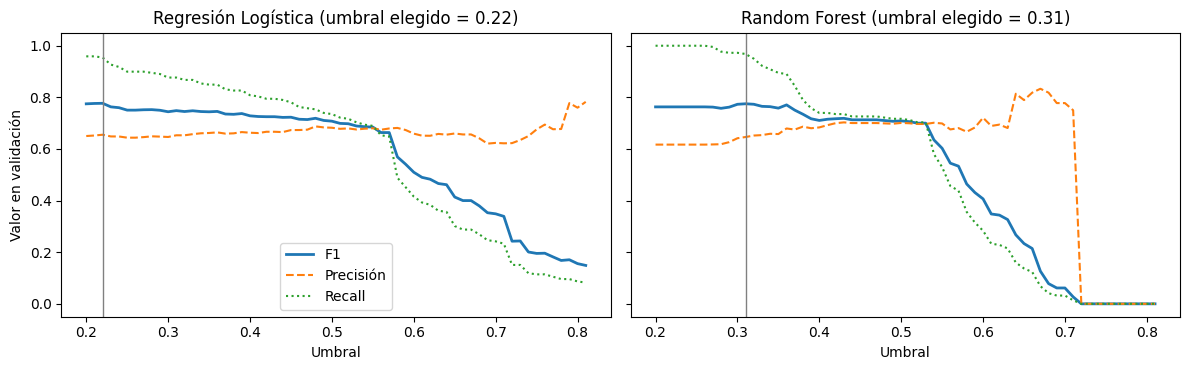

In [44]:
def buscar_umbral_f1(modelo, X_val, y_val):
    probabilidades = modelo.predict_proba(X_val)[:, 1]          # columna 1 = probabilidad de "no renovó"
    candidatos = []
    for umbral in np.arange(0.20, 0.81, 0.01):
        pred = (probabilidades >= umbral).astype(int)
        candidatos.append({"umbral": round(float(umbral), 2),
                           "f1": f1_score(y_val, pred, zero_division=0),
                           "precision": precision_score(y_val, pred, zero_division=0),
                           "recall": recall_score(y_val, pred, zero_division=0)})
    tabla = pd.DataFrame(candidatos)
    mejor = tabla.sort_values(["f1", "precision", "recall"], ascending=False).iloc[0]
    return float(mejor["umbral"]), tabla

umbrales_modelos, tablas_umbrales = {}, {}
for nombre, modelo in modelos.items():
    umbrales_modelos[nombre], tablas_umbrales[nombre] = buscar_umbral_f1(modelo, X_validation, y_validation)

display(pd.DataFrame({"Modelo": list(umbrales_modelos), "Umbral elegido en validación": list(umbrales_modelos.values())}))

# Gráfico: cómo cambia F1, precisión y recall según el umbral
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (nombre, tabla) in zip(axes, tablas_umbrales.items()):
    ax.plot(tabla["umbral"], tabla["f1"], label="F1", lw=2)
    ax.plot(tabla["umbral"], tabla["precision"], label="Precisión", ls="--")
    ax.plot(tabla["umbral"], tabla["recall"], label="Recall", ls=":")
    ax.axvline(umbrales_modelos[nombre], color="gray", lw=1)
    ax.set_title(f"{nombre} (umbral elegido = {umbrales_modelos[nombre]:.2f})")
    ax.set_xlabel("Umbral")
axes[0].set_ylabel("Valor en validación"); axes[0].legend()
plt.tight_layout(); plt.show()

#### Interpretación de los resultados

A medida que el umbral **baja**, el modelo marca a más socios como riesgo: el **recall sube** (detecta más bajas) y la **precisión baja** (más falsas alarmas). El F1 se maximiza con umbrales bajos (≈0,2–0,3) porque, al ser la no renovación tan frecuente, "marcar a casi todos" da un F1 alto. **Consecuencia práctica:** con estos umbrales el modelo se parece mucho al piso en sus decisiones sí/no (marca a casi todos). Por eso, más adelante también se reportan las métricas con umbral 0,50 y, sobre todo, se evalúa la **lista ordenada**, que es donde el modelo aporta valor.

## Sección 11.2 · Comparación de modelos en validación

**Descripción.** Se calculan las 10 métricas para el piso trivial, la Regresión Logística y el Random Forest en el período de validación (ene–abr 2026).

**Objetivo.** tener la evidencia sobre la cual se **decide** qué modelo usar.

In [45]:
prevalencia_entrenamiento = y_train.mean()   # probabilidad constante del piso (aprendida SOLO en entrenamiento)
print("Probabilidad constante del piso trivial:", round(prevalencia_entrenamiento, 4))

def comparar_en_conjunto(X, y, nombre_conjunto, umbrales=None):
    umbrales = umbrales or umbrales_modelos
    filas = []
    proba_piso = np.full(len(y), prevalencia_entrenamiento)
    m_piso = calcular_metricas(y, proba_piso, umbral=UMBRAL_CLASIFICACION)
    m_piso[f"Precisión@{TOP_K}"] = y.mean()   # sin orden, los 25 primeros equivalen a una selección al azar
    m_piso[f"Lift@{TOP_K}"] = 1.0
    filas.append({"Conjunto": nombre_conjunto, "Modelo": "Piso trivial (Nivel 0)", "Umbral": UMBRAL_CLASIFICACION, **m_piso})
    for nombre, modelo in modelos.items():
        proba = modelo.predict_proba(X)[:, 1]
        filas.append({"Conjunto": nombre_conjunto, "Modelo": nombre, "Umbral": umbrales[nombre],
                      **calcular_metricas(y, proba, umbral=umbrales[nombre])})
    return pd.DataFrame(filas)

columnas_metricas = ["Modelo", "Umbral", "Accuracy", "Precisión", "Recall", "Especificidad", "F1",
                     "PR-AUC", "ROC-AUC", "Brier", f"Precisión@{TOP_K}", f"Lift@{TOP_K}"]

comparacion_validacion = comparar_en_conjunto(X_validation, y_validation, "Validación")
display(comparacion_validacion[columnas_metricas].round(4))

Probabilidad constante del piso trivial: 0.7446


,Modelo,Umbral,Accuracy,Precisión,Recall,Especificidad,F1,PR-AUC,ROC-AUC,Brier,Precisión@25,Lift@25
0,Piso trivial (Nivel 0),0.50,0.6169,0.6169,1.0000,0.0000,0.7631,0.6169,0.5000,0.2526,0.6169,1.0000
1,Regresión Logística,0.22,0.6620,0.6552,0.9543,0.1912,0.7770,0.6799,0.5945,0.2467,0.7600,1.2320
2,Random Forest,0.31,0.6535,0.6463,0.9680,0.1471,0.7751,0.7069,0.6243,0.2367,0.8400,1.3616


## Sección 11.3 · Criterio de selección del modelo

**Descripción.** Se aplica una regla formal: un modelo **reemplaza al piso** solo si, en validación, cumple **simultáneamente** tres condiciones:

| # | Criterio | Qué garantiza | Por qué se eligió |
|---|---|---|---|
| 1 | **F1 > F1 del piso** | Sus decisiones sí/no son mejores que marcar a todos. | Resume precisión y recall en un número. |
| 2 | **PR-AUC > PR-AUC del piso** | Ordena mejor que el azar. | Es lo que necesita la lista priorizada. |
| 3 | **Brier < Brier del piso** | Sus probabilidades son más confiables que un promedio fijo. | Si se muestran porcentajes al personal, deben tener sentido. |

Si **varios** modelos cumplen, se elige el de **mayor PR-AUC** (mejor ordenamiento) y, en empate, el de menor Brier.

**Justificación.** Definir la regla **antes** evita elegir "a conveniencia" después de ver los números (sesgo del investigador). Es el mismo principio de fijar los criterios de una licitación antes de abrir las ofertas.

**Objetivo.** una selección **objetiva, reproducible y auditable**.

In [46]:
piso_val = comparacion_validacion.iloc[0]      # primera fila = piso trivial
evaluacion_criterios = comparacion_validacion.iloc[1:].copy()
evaluacion_criterios["Supera F1"] = evaluacion_criterios["F1"] > piso_val["F1"]
evaluacion_criterios["Supera PR-AUC"] = evaluacion_criterios["PR-AUC"] > piso_val["PR-AUC"]
evaluacion_criterios["Mejora Brier"] = evaluacion_criterios["Brier"] < piso_val["Brier"]
evaluacion_criterios["Cumple 3 criterios"] = evaluacion_criterios[["Supera F1", "Supera PR-AUC", "Mejora Brier"]].all(axis=1)

display(evaluacion_criterios[["Modelo", "F1", "PR-AUC", "Brier", "Supera F1", "Supera PR-AUC",
                              "Mejora Brier", "Cumple 3 criterios"]].round(4))

candidatos = evaluacion_criterios.loc[evaluacion_criterios["Cumple 3 criterios"]]
seleccion_formal = len(candidatos) > 0
base = candidatos if seleccion_formal else evaluacion_criterios
modelo_seleccionado_nombre = base.sort_values(["PR-AUC", "Brier"], ascending=[False, True]).iloc[0]["Modelo"]
modelo_seleccionado = modelos[modelo_seleccionado_nombre]
umbral_seleccionado = umbrales_modelos[modelo_seleccionado_nombre]

print("\nModelo seleccionado:", modelo_seleccionado_nombre)
print("Selección formal:", "Sí" if seleccion_formal else "No (selección provisional)")

,Modelo,F1,PR-AUC,Brier,Supera F1,Supera PR-AUC,Mejora Brier,Cumple 3 criterios
1,Regresión Logística,0.7770,0.6799,0.2467,True,True,True,True
2,Random Forest,0.7751,0.7069,0.2367,True,True,True,True



Modelo seleccionado: Random Forest
Selección formal: Sí


#### Interpretación de los resultados


- En validación, **ambos modelos cumplen los tres criterios**: superan al piso en F1, en PR-AUC y en Brier.
- El desempate por **PR-AUC** favorece al **Random Forest** (≈0,71 vs ≈0,68), que además tiene el **mejor Brier** (≈0,237 vs ≈0,247) y la mejor **Precisión@25** (0,84 vs 0,76).
- Por lo tanto, **Random Forest es el modelo seleccionado**, de forma coherente con el Informe S5.

**Nota de coherencia con el Informe S5:** en esa corrida la Regresión Logística **no** pasó el filtro de Brier; en esta corrida sí lo pasa, pero pierde en el desempate. **La conclusión es la misma** (Random Forest), y la regla de selección no se modificó.

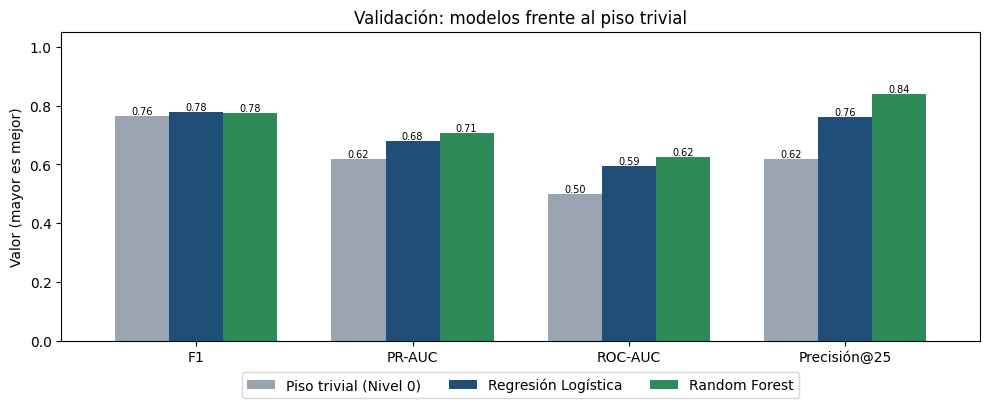

In [47]:
# Visualización de la comparación en validación
metricas_graf = ["F1", "PR-AUC", "ROC-AUC", f"Precisión@{TOP_K}"]
tabla_g = comparacion_validacion.set_index("Modelo")[metricas_graf]
ax = tabla_g.T.plot(kind="bar", figsize=(10, 4.2), rot=0, color=[COLORES["gris"], COLORES["azul"], COLORES["verde"]], width=0.75)
ax.set_ylim(0, 1.05); ax.set_ylabel("Valor (mayor es mejor)"); ax.set_xlabel("")
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
ax.set_title("Validación: modelos frente al piso trivial")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.show()

---
# Parte 12 · Evaluación final en PRUEBA y análisis de resultados

A partir de aquí **ya no se toma ninguna decisión**: el modelo y el umbral están fijados. Solo se mide.

## Sección 12.1 · Comparación final de modelos en prueba

**Descripción.** Se abre el conjunto de prueba (may–ago 2026) **una sola vez** y se calculan todas las métricas para los tres competidores, con el **nombre técnico**, el **umbral** y el **valor de referencia** del piso.

**Objetivo.** la evidencia principal del desempeño del MVP.

,Modelo,Umbral,Accuracy,Precisión,Recall,Especificidad,F1,PR-AUC,ROC-AUC,Brier,Precisión@25,Lift@25,Seleccionado
0,Piso trivial (Nivel 0),0.50,0.6679,0.6679,1.0000,0.0000,0.8009,0.6679,0.5000,0.2277,0.6679,1.0000,
1,Regresión Logística,0.22,0.6787,0.7017,0.9027,0.2283,0.7896,0.7974,0.6743,0.2343,0.8400,1.2577,
2,Random Forest,0.31,0.7112,0.7027,0.9838,0.1630,0.8198,0.7899,0.6952,0.2299,0.8000,1.1978,✔


Umbrales: piso = 0.5 | Regresión Logística = 0.22 | Random Forest = 0.31


,Métrica,Nombre técnico,¿Usa umbral?,Mejor si es,Referencia (piso),Regresión Logística,Random Forest,¿El seleccionado supera al piso?
0,Accuracy,Accuracy,Sí,Mayor,0.6679,0.6787,0.7112,Sí
1,Precisión,Precision / Positive Predictive Value,Sí,Mayor,0.6679,0.7017,0.7027,Sí
2,Recall,Recall / Sensitivity / True Positive Rate,Sí,Mayor,1.0000,0.9027,0.9838,No
3,Especificidad,Specificity / True Negative Rate,Sí,Mayor,0.0000,0.2283,0.1630,Sí
4,F1,F1-score,Sí,Mayor,0.8009,0.7896,0.8198,Sí
5,PR-AUC,Average Precision (área bajo curva Precisión-Recall),No,Mayor,0.6679,0.7974,0.7899,Sí
6,ROC-AUC,Area Under the ROC Curve,No,Mayor,0.5000,0.6743,0.6952,Sí
7,Brier,Brier Score,No,Menor,0.2277,0.2343,0.2299,No
8,Precisión@25,Precision at K (K=25),No,Mayor,0.6679,0.8400,0.8000,Sí
9,Lift@25,Lift at K (K=25),No,Mayor,1.0000,1.2577,1.1978,Sí


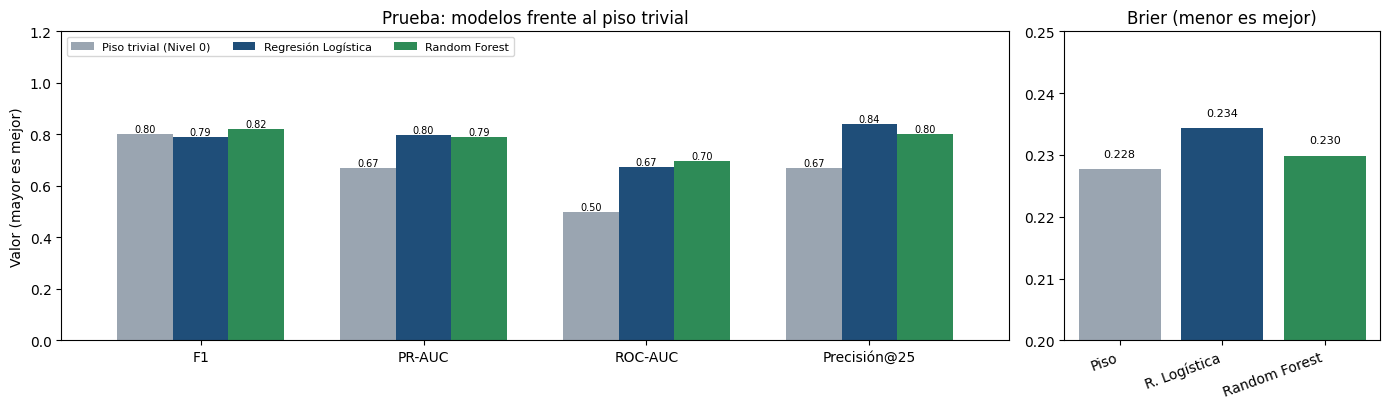

In [48]:
comparacion_prueba = comparar_en_conjunto(X_test, y_test, "Prueba")
tabla_docente = comparacion_prueba[columnas_metricas].copy()
tabla_docente["Seleccionado"] = np.where(tabla_docente["Modelo"] == modelo_seleccionado_nombre, "✔", "")
display(tabla_docente.round(4))

# Versión "larga": una fila por métrica, con nombre técnico, referencia y diferencia frente al piso
piso_t = comparacion_prueba.iloc[0]
larga = []
for _, fila_cat in catalogo_metricas.iterrows():
    m = fila_cat["métrica"]
    fila = {"Métrica": m, "Nombre técnico": fila_cat["nombre_técnico"], "¿Usa umbral?": fila_cat["usa_umbral"],
            "Mejor si es": fila_cat["mejor_dirección"], "Referencia (piso)": round(piso_t[m], 4)}
    for _, r in comparacion_prueba.iloc[1:].iterrows():
        fila[r["Modelo"]] = round(r[m], 4)
    sel = comparacion_prueba.set_index("Modelo").loc[modelo_seleccionado_nombre, m]
    mejora = (sel - piso_t[m]) if fila_cat["mejor_dirección"] == "Mayor" else (piso_t[m] - sel)
    fila["¿El seleccionado supera al piso?"] = "Sí" if mejora > 0 else "No"
    larga.append(fila)
tabla_metricas_larga = pd.DataFrame(larga)
print(f"Umbrales: piso = {UMBRAL_CLASIFICACION} | " +
      " | ".join(f"{k} = {v}" for k, v in umbrales_modelos.items()))
display(tabla_metricas_larga)

# Gráfico: métricas "mayor es mejor" del piso y de los dos modelos en prueba
metricas_graf = ["F1", "PR-AUC", "ROC-AUC", f"Precisión@{TOP_K}"]
tabla_g = comparacion_prueba.set_index("Modelo")[metricas_graf]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [3, 1]})
tabla_g.T.plot(kind="bar", ax=axes[0], rot=0, width=0.75, color=[COLORES["gris"], COLORES["azul"], COLORES["verde"]])
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", fontsize=7)
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel("Valor (mayor es mejor)"); axes[0].set_xlabel("")
axes[0].set_ylim(0, 1.2); axes[0].set_title("Prueba: modelos frente al piso trivial"); axes[0].legend(loc="upper left", ncol=3, fontsize=8)

# Brier por separado porque "menor es mejor"
axes[1].bar(["Piso", "R. Logística", "Random Forest"], comparacion_prueba["Brier"],
            color=[COLORES["gris"], COLORES["azul"], COLORES["verde"]])
for i, v in enumerate(comparacion_prueba["Brier"]):
    axes[1].text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=8)
axes[1].set_ylim(0.20, 0.25); axes[1].set_title("Brier (menor es mejor)")
plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Sección 12.2 · Análisis de los resultados en prueba

**Fortalezas observadas**

- **Ordenamiento (PR-AUC):** el Random Forest obtiene ≈**0,79** frente a **0,67** del piso (+0,12). Es decir, cuando se ordena a los socios por riesgo, los que realmente se van quedan claramente más arriba que con una lista al azar. **Esta es la capacidad central que necesita Mtabolic.**
- **ROC-AUC ≈ 0,69:** el modelo separa las dos clases mejor que el azar (0,50), en un nivel **moderado**. Es consistente con no tener datos de asistencia, la señal más fuerte según la literatura.
- **F1:** ≈0,82 frente a 0,80 del piso. Mejora, pero por un **margen estrecho** (igual que en el Informe S5).
- **Precisión@25 = 0,80 y Lift@25 ≈ 1,20:** de los 25 socios de mayor riesgo, 20 no renovaron; al azar se esperarían ≈16,7. **20 % más de efectividad con el mismo esfuerzo comercial.**

**Aspectos que requieren cautela**

- **Especificidad baja (≈0,15–0,16) con el umbral 0,31:** el modelo marca como riesgo a casi todos, incluidos muchos que sí renovaron. En decisiones sí/no, se comporta parecido al piso. Por eso **no se recomienda usarlo como un clasificador "sí/no"**, sino como **ordenador** de la lista.
- **Brier en prueba ≈ 0,230 vs 0,228 del piso:** en prueba, las probabilidades del Random Forest **no son más confiables** que el promedio fijo (la diferencia es mínima y desfavorable). Se explica por el **cambio de comportamiento** 2025→2026 y por `class_weight="balanced"`, que desplaza las probabilidades. Es la misma conclusión del Informe S5: **los porcentajes requieren calibración** (backlog, tarea 1).
- **Regresión Logística:** en prueba ordena de forma muy similar (PR-AUC 0,80, incluso ligeramente mayor) y tiene mejor Precisión@25 (0,84), pero no supera al piso en F1. Las diferencias entre ambos modelos son pequeñas y pueden deberse al azar con solo 277 casos (se verifica en la Sección 12.7).

In [49]:
# Los tres criterios de selección, verificados también en PRUEBA (solo para transparencia, NO para decidir)
crit_prueba = comparacion_prueba.iloc[1:][["Modelo", "F1", "PR-AUC", "Brier"]].copy()
crit_prueba["Supera F1"] = crit_prueba["F1"] > piso_t["F1"]
crit_prueba["Supera PR-AUC"] = crit_prueba["PR-AUC"] > piso_t["PR-AUC"]
crit_prueba["Mejora Brier"] = crit_prueba["Brier"] < piso_t["Brier"]
print("Referencia del piso en prueba -> F1:", round(piso_t["F1"], 4), "| PR-AUC:", round(piso_t["PR-AUC"], 4),
      "| Brier:", round(piso_t["Brier"], 4))
display(crit_prueba.round(4))

Referencia del piso en prueba -> F1: 0.8009 | PR-AUC: 0.6679 | Brier: 0.2277


,Modelo,F1,PR-AUC,Brier,Supera F1,Supera PR-AUC,Mejora Brier
1,Regresión Logística,0.7896,0.7974,0.2343,False,True,False
2,Random Forest,0.8198,0.7899,0.2299,True,True,False


## Sección 12.3 · Sensibilidad al umbral de clasificación

**Descripción.** Se recalculan las métricas del modelo seleccionado en prueba con distintos umbrales.

**Justificación.** Para mostrar que la elección del umbral es una **decisión de negocio** (cuántas falsas alarmas se toleran), no un detalle técnico. Además, facilita la comparación con el Informe S5, cuyas métricas sí/no fueron reportadas con otro umbral.

**Objetivo.** que el equipo y Mtabolic entiendan el intercambio entre detectar más bajas y hacer menos llamadas innecesarias.

In [50]:
probabilidades_test = modelo_seleccionado.predict_proba(X_test)[:, 1]
filas = []
for u in [umbral_seleccionado, 0.40, 0.50, 0.55, 0.60]:
    m = calcular_metricas(y_test, probabilidades_test, umbral=u)
    marcados = int((probabilidades_test >= u).sum())
    filas.append({"Umbral": u, "Socios marcados como riesgo": marcados,
                  **{k: round(m[k], 3) for k in ["Accuracy", "Precisión", "Recall", "Especificidad", "F1"]}})
display(pd.DataFrame(filas))

,Umbral,Socios marcados como riesgo,Accuracy,Precisión,Recall,Especificidad,F1
0,0.31,259,0.711,0.703,0.984,0.163,0.820
1,0.40,183,0.704,0.781,0.773,0.565,0.777
2,0.50,170,0.686,0.788,0.724,0.609,0.755
3,0.55,101,0.531,0.772,0.422,0.750,0.545
4,0.60,56,0.455,0.804,0.243,0.880,0.373


#### Interpretación de los resultados

Al **subir** el umbral, el modelo marca a menos socios, la **especificidad** y la **precisión** aumentan (menos llamadas innecesarias) y el **recall** baja (se escapan más bajas). No hay un umbral "correcto" universal: depende del costo de una llamada frente al valor de retener a un socio, y de la capacidad real de contacto (dato pendiente de confirmar con Mtabolic). Para la **lista de 25**, el umbral no importa: se toman los 25 de mayor probabilidad.

## Sección 12.4 · Matriz de confusión del modelo seleccionado

**Descripción.** Se cuenta, en prueba, cuántos aciertos y errores de cada tipo tuvo el Random Forest con su umbral.

**Objetivo.** traducir las métricas a **personas concretas**.

Umbral usado: 0.31


,Predijo: Renovó,Predijo: No renovó
Real: Renovó,15,77
Real: No renovó,3,182


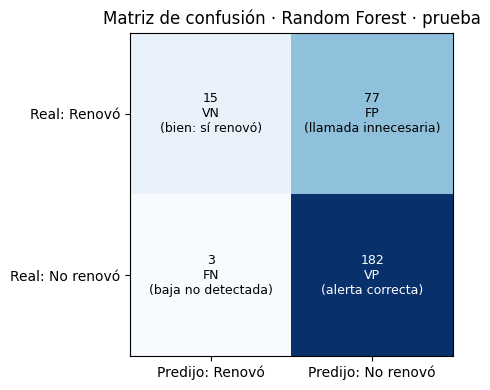

In [51]:
predicciones_test = (probabilidades_test >= umbral_seleccionado).astype(int)
matriz = confusion_matrix(y_test, predicciones_test, labels=[0, 1])
matriz_df = pd.DataFrame(matriz, index=["Real: Renovó", "Real: No renovó"],
                         columns=["Predijo: Renovó", "Predijo: No renovó"])
print("Umbral usado:", umbral_seleccionado)
display(matriz_df)

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(matriz, cmap="Blues")
etiquetas = [["VN\n(bien: sí renovó)", "FP\n(llamada innecesaria)"], ["FN\n(baja no detectada)", "VP\n(alerta correcta)"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{matriz[i, j]}\n{etiquetas[i][j]}", ha="center", va="center",
                color="white" if matriz[i, j] > matriz.max() / 2 else "black", fontsize=9)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Predijo: Renovó", "Predijo: No renovó"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Real: Renovó", "Real: No renovó"])
ax.set_title(f"Matriz de confusión · {modelo_seleccionado_nombre} · prueba")
plt.tight_layout(); plt.show()

#### Interpretación de los resultados

De los socios que **no renovaron**, el modelo detectó casi todos (muy pocos **FN**). Pero de los que **sí renovaron**, solo reconoció a unos pocos: la mayoría quedó como **FP** (llamadas innecesarias). Esto confirma que, con el umbral 0,31, el modelo prioriza no dejar escapar bajas a costa de muchas falsas alarmas. En la operación real esto se controla usando la **lista de los K primeros**, no el umbral.

## Sección 12.5 · Curvas de desempeño: Precisión-Recall, ganancia acumulada y calibración

**Descripción.** Se dibujan tres gráficos complementarios:
1. **Curva Precisión-Recall:** muestra la precisión que se obtiene para cada nivel de detección. Su área es la PR-AUC.
2. **Curva de ganancia acumulada:** si se contacta al X % de mayor riesgo, ¿qué % de todas las bajas se cubre? Es el gráfico más útil para un **administrador**.
3. **Curva de calibración:** compara la probabilidad que dice el modelo con la frecuencia real. Si el modelo dice "60 %", ¿realmente se va el 60 %?

**Objetivo.** ver el comportamiento completo del modelo, no solo un punto.

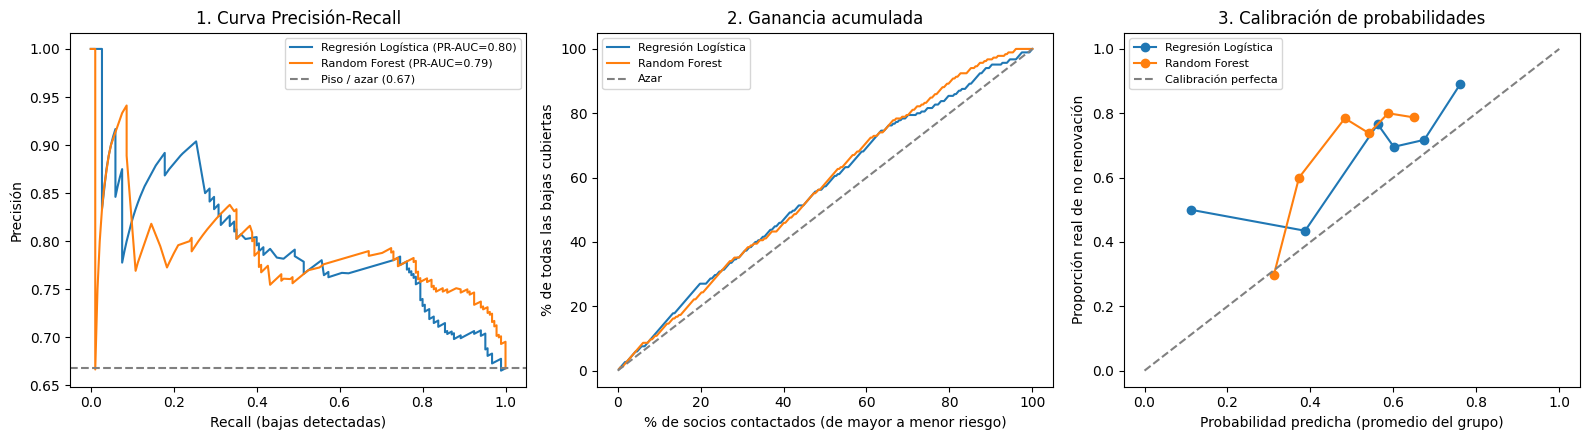

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
proba_modelos = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos.items()}
prev = y_test.mean()

# 1) Curva Precisión-Recall
for n, p in proba_modelos.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rc, pr, label=f"{n} (PR-AUC={average_precision_score(y_test, p):.2f})")
axes[0].axhline(prev, color="gray", ls="--", label=f"Piso / azar ({prev:.2f})")
axes[0].set_xlabel("Recall (bajas detectadas)"); axes[0].set_ylabel("Precisión")
axes[0].set_title("1. Curva Precisión-Recall"); axes[0].legend(fontsize=8)

# 2) Ganancia acumulada
y_arr = y_test.to_numpy()
for n, p in proba_modelos.items():
    orden = np.argsort(p)[::-1]
    capturadas = np.cumsum(y_arr[orden]) / y_arr.sum()
    pct_contactado = np.arange(1, len(y_arr) + 1) / len(y_arr)
    axes[1].plot(100 * pct_contactado, 100 * capturadas, label=n)
axes[1].plot([0, 100], [0, 100], color="gray", ls="--", label="Azar")
axes[1].set_xlabel("% de socios contactados (de mayor a menor riesgo)")
axes[1].set_ylabel("% de todas las bajas cubiertas")
axes[1].set_title("2. Ganancia acumulada"); axes[1].legend(fontsize=8)

# 3) Calibración
for n, p in proba_modelos.items():
    frac_real, prob_media = calibration_curve(y_test, p, n_bins=6, strategy="quantile")
    axes[2].plot(prob_media, frac_real, marker="o", label=n)
axes[2].plot([0, 1], [0, 1], color="gray", ls="--", label="Calibración perfecta")
axes[2].set_xlabel("Probabilidad predicha (promedio del grupo)")
axes[2].set_ylabel("Proporción real de no renovación")
axes[2].set_title("3. Calibración de probabilidades"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Interpretación de los resultados


1. **Precisión-Recall:** las curvas de ambos modelos están **por encima** de la línea del azar en casi todo el recorrido, sobre todo al inicio (izquierda), que corresponde a los primeros de la lista. Esa es la zona que usa Mtabolic.
2. **Ganancia acumulada:** las curvas quedan **por encima de la diagonal**. Contactando a una fracción de los socios de mayor riesgo se cubre un porcentaje de bajas mayor que esa fracción. La ventaja es moderada, consistente con un ROC-AUC ≈ 0,69.
3. **Calibración:** la mayoría de los puntos quedan **por encima** de la diagonal: cuando el modelo dice "50 %", en realidad no renueva bastante más. El modelo **subestima** el riesgo absoluto (efecto de `class_weight="balanced"`). **Conclusión práctica:** el **orden** es útil, pero los **porcentajes** no deben leerse literalmente hasta calibrarlos (tarea prioritaria del backlog).

## Sección 12.6 · Utilidad operativa: aciertos según el tamaño de la lista

**Descripción.** Se cuenta cuántos socios que realmente no renovaron aparecen entre los primeros K de la lista (K = 10, 25, 50, 100) y se compara con lo esperado al azar.

**Justificación.** La organización no puede contactar a todos. La pregunta de negocio es: **"con mi capacidad, ¿cuántas llamadas útiles gano?"**. Esta tabla replica la Tabla 5 del Informe S5.

,Socios contactados (K),Aciertos con el sistema,Aciertos esperados al azar,Aciertos adicionales,Mejora relativa
0,10,9,6.7,2.3,+35 %
1,25,20,16.7,3.3,+20 %
2,50,40,33.4,6.6,+20 %
3,100,77,66.8,10.2,+15 %


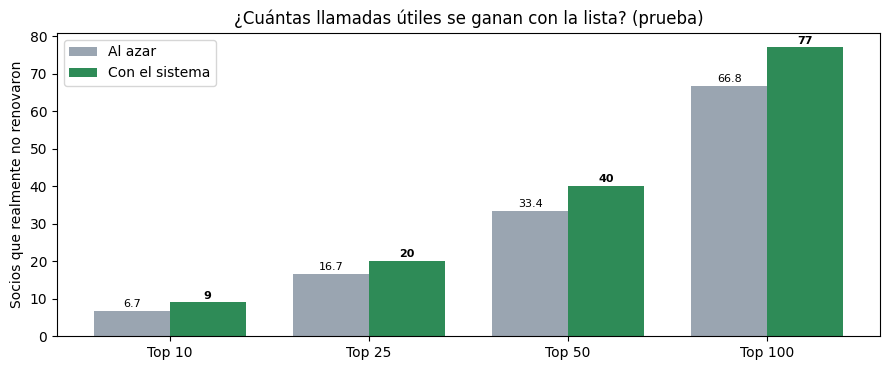

In [53]:
orden_test = np.argsort(probabilidades_test)[::-1]
filas = []
for k in [10, 25, 50, 100]:
    aciertos = int(y_test.iloc[orden_test[:k]].sum())
    azar = y_test.mean() * k
    filas.append({"Socios contactados (K)": k, "Aciertos con el sistema": aciertos,
                  "Aciertos esperados al azar": round(azar, 1),
                  "Aciertos adicionales": round(aciertos - azar, 1),
                  "Mejora relativa": f"{100 * (aciertos / azar - 1):+.0f} %"})
utilidad_top_k = pd.DataFrame(filas)
display(utilidad_top_k)

# Gráfico: aciertos del sistema vs aciertos esperados al azar para cada tamaño de lista
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(utilidad_top_k)); w = 0.38
ax.bar(x - w/2, utilidad_top_k["Aciertos esperados al azar"], w, label="Al azar", color=COLORES["gris"])
ax.bar(x + w/2, utilidad_top_k["Aciertos con el sistema"], w, label="Con el sistema", color=COLORES["verde"])
for i, (a_, s_) in enumerate(zip(utilidad_top_k["Aciertos esperados al azar"], utilidad_top_k["Aciertos con el sistema"])):
    ax.text(i - w/2, a_ + 1, f"{a_:.1f}", ha="center", fontsize=8)
    ax.text(i + w/2, s_ + 1, f"{s_}", ha="center", fontsize=8, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels([f"Top {k}" for k in utilidad_top_k["Socios contactados (K)"]])
ax.set_ylabel("Socios que realmente no renovaron")
ax.set_title("¿Cuántas llamadas útiles se ganan con la lista? (prueba)")
ax.legend()
plt.tight_layout()
plt.show()

#### Interpretación de los resultados

Con la capacidad supuesta de **25 contactos**, la lista del modelo acierta con **20** socios que realmente se iban a ir, frente a **≈16,7** si se eligieran al azar. Son **≈3 llamadas mejor dirigidas por cada 25**, es decir, **≈20 % más de efectividad** del trabajo comercial **sin contratar personal ni cambiar procesos**. (El Informe S5 reportó 19 vs 15,8 con la corrida anterior; la conclusión es la misma).

> **Advertencia:** esto no significa que esas 20 personas **se retendrán** al llamarlas. El modelo identifica riesgo; el efecto de la llamada es otro problema (causal) que no se evalúa aquí.

## Sección 12.7 · Verificación estadística de la mejora (bootstrap)

**Descripción.** Se aplica un **bootstrap**: se remuestrea el conjunto de prueba 1.000 veces (sacando socios al azar con reemplazo) y se recalcula la PR-AUC del modelo y la del piso en cada muestra.

**Justificación.** Con solo 277 casos, una diferencia pequeña podría ser suerte. El bootstrap da un **intervalo de confianza**: si en casi todas las muestras el modelo supera al piso, la mejora es real. Responde a la tarea 4 del backlog del Informe S5.

**Objetivo.** cuantificar la incertidumbre de los resultados.

In [54]:
rng = np.random.default_rng(SEMILLA)
y_np = y_test.to_numpy()
p_rf = proba_modelos[modelo_seleccionado_nombre]
p_lr = proba_modelos["Regresión Logística"]
dif_piso, dif_modelos, top25 = [], [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_np), len(y_np))       # muestra con reemplazo
    yb = y_np[idx]
    if yb.min() == yb.max():
        continue
    dif_piso.append(average_precision_score(yb, p_rf[idx]) - yb.mean())         # PR-AUC modelo - PR-AUC piso
    dif_modelos.append(average_precision_score(yb, p_rf[idx]) - average_precision_score(yb, p_lr[idx]))

def resumen(nombre, v):
    v = np.array(v)
    return {"Comparación": nombre, "Diferencia media": round(v.mean(), 3),
            "IC 95 % inferior": round(np.percentile(v, 2.5), 3), "IC 95 % superior": round(np.percentile(v, 97.5), 3),
            "% de muestras con diferencia > 0": es(100 * (v > 0).mean(), 1) + " %"}

display(pd.DataFrame([resumen(f"PR-AUC {modelo_seleccionado_nombre} − piso", dif_piso),
                      resumen(f"PR-AUC {modelo_seleccionado_nombre} − Regresión Logística", dif_modelos)]))

,Comparación,Diferencia media,IC 95 % inferior,IC 95 % superior,% de muestras con diferencia > 0
0,PR-AUC Random Forest − piso,0.124,0.073,0.175,"100,0 %"
1,PR-AUC Random Forest − Regresión Logística,-0.006,-0.045,0.035,"35,9 %"


#### Interpretación de los resultados


- **Modelo vs piso:** si el intervalo de confianza al 95 % está completamente **por encima de 0**, la mejora del ordenamiento **no es casualidad**: existe señal real en los datos.
- **Random Forest vs Regresión Logística:** si el intervalo **incluye el 0**, la diferencia entre ambos modelos **no es concluyente** con los datos actuales. Ambos son alternativas razonables; la elección del Random Forest se sostiene por la regla definida previamente en validación, no por una superioridad demostrada en prueba.

## Sección 12.8 · Desempeño mes a mes en prueba

**Descripción.** Se calculan las métricas del modelo seleccionado **por separado para cada mes** del período de prueba, y se compara la tasa real de no renovación con el riesgo promedio que predijo el modelo.

**Justificación.** Un buen promedio puede esconder un mes malo. Además responde directamente a la solicitud del tutor de un análisis **mes a mes**. Cuando un mes no tiene ambas clases (o tiene muy pocos casos, como agosto), algunas métricas no se pueden calcular o no son confiables.

,mes,ciclos,tasa_real_no_renovacion,riesgo_promedio_predicho,precision,recall,f1,brier,precision@25,pr_auc,roc_auc
0,2026-05,94,0.660,0.493,0.685,0.984,0.808,0.234,0.72,0.755,0.674
1,2026-06,86,0.628,0.512,0.679,0.981,0.803,0.211,0.84,0.809,0.751
2,2026-07,93,0.731,0.471,0.753,0.985,0.854,0.242,0.88,0.871,0.716
3,2026-08,4,0.250,0.400,0.333,1.000,0.500,0.244,0.25,0.500,0.667


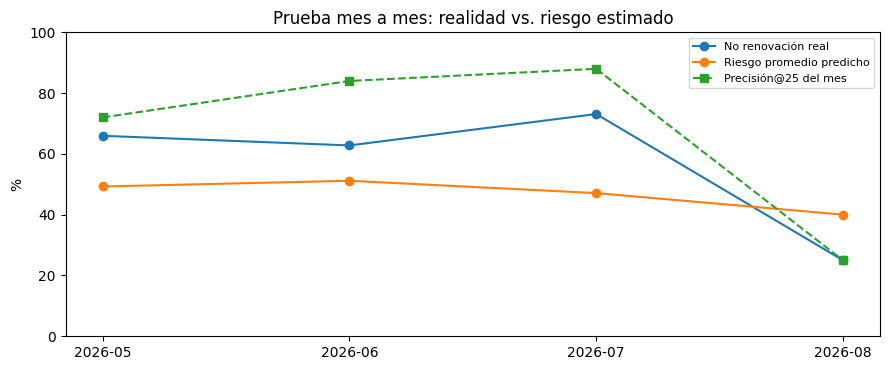

In [55]:
test_evaluado = test.copy()
test_evaluado["probabilidad"] = probabilidades_test
filas_mes = []
for mes, g in test_evaluado.groupby("mes_vencimiento"):
    y_m, p_m = g["no_renovo"].to_numpy(), g["probabilidad"].to_numpy()
    pred_m = (p_m >= umbral_seleccionado).astype(int)
    k_m = min(TOP_K, len(g)); orden_m = np.argsort(p_m)[::-1][:k_m]
    fila = {"mes": mes, "ciclos": len(g), "tasa_real_no_renovacion": y_m.mean(),
            "riesgo_promedio_predicho": p_m.mean(),
            "precision": precision_score(y_m, pred_m, zero_division=0),
            "recall": recall_score(y_m, pred_m, zero_division=0),
            "f1": f1_score(y_m, pred_m, zero_division=0),
            "brier": brier_score_loss(y_m, p_m),
            f"precision@{TOP_K}": y_m[orden_m].mean()}
    both = len(np.unique(y_m)) == 2
    fila["pr_auc"] = average_precision_score(y_m, p_m) if both else np.nan
    fila["roc_auc"] = roc_auc_score(y_m, p_m) if both else np.nan
    filas_mes.append(fila)
metricas_mensuales = pd.DataFrame(filas_mes)
display(metricas_mensuales.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(metricas_mensuales["mes"], 100 * metricas_mensuales["tasa_real_no_renovacion"], marker="o", label="No renovación real")
ax.plot(metricas_mensuales["mes"], 100 * metricas_mensuales["riesgo_promedio_predicho"], marker="o", label="Riesgo promedio predicho")
ax.plot(metricas_mensuales["mes"], 100 * metricas_mensuales[f"precision@{TOP_K}"], marker="s", ls="--", label=f"Precisión@{TOP_K} del mes")
ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.legend(fontsize=8)
ax.set_title("Prueba mes a mes: realidad vs. riesgo estimado")
plt.tight_layout(); plt.show()

#### Interpretación de los resultados

En **mayo, junio y julio** (≈90 ciclos cada uno) el modelo mantiene un desempeño **estable**: PR-AUC entre ≈0,75 y ≈0,87 y alta precisión en la lista. La línea del riesgo predicho queda **por debajo** de la realidad, confirmando que las probabilidades están subestimadas (problema de calibración, no de ordenamiento). **Agosto** solo tiene 4 ciclos evaluables (el resto está pendiente), así que sus métricas **no son interpretables**.

## Sección 12.9 · Importancia de las variables

**Descripción.** Se usa **Permutation Importance** (importancia por permutación) sobre validación: se "desordena" una variable a la vez y se mide cuánto empeora la PR-AUC.

**Justificación.** Si al desordenar una variable el modelo empeora mucho, esa variable contenía información útil. Es una forma de **explicar** un modelo complejo como el Random Forest sin abrirlo.

**Analogía.** para saber qué tan importante es un ingrediente en una receta, se prepara la receta con ese ingrediente cambiado al azar y se ve cuánto empeora el sabor.

**Objetivo.** dar explicabilidad global y verificar coherencia con el negocio.

,variable,importancia_media,desviacion
6,plan,0.0159,0.0089
7,forma_pago,0.0129,0.0083
9,inicio_aproximado,0.0055,0.0031
4,monto_historico,0.0030,0.0096
1,antiguedad_dias,0.0014,0.0026
3,monto_actual,0.0008,0.0047
8,mes_vencimiento,0.0000,0.0000
5,dias_desde_ultima_membresia,-0.0003,0.0121
0,ciclos_previos,-0.0015,0.0098
2,duracion_modelo,-0.0024,0.0043


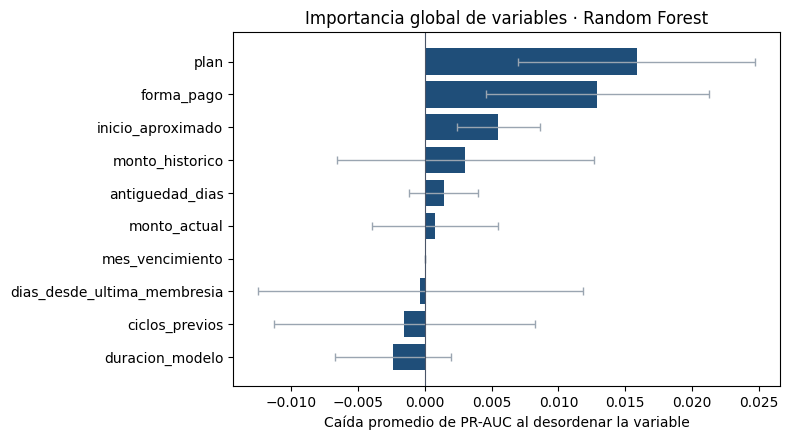

In [56]:
importancia = permutation_importance(modelo_seleccionado, X_validation, y_validation,
                                     scoring="average_precision", n_repeats=10, random_state=SEMILLA)
tabla_importancia = pd.DataFrame({"variable": VARIABLES_MODELO,
                                  "importancia_media": importancia.importances_mean,
                                  "desviacion": importancia.importances_std}
                                 ).sort_values("importancia_media", ascending=False)
display(tabla_importancia.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
t = tabla_importancia.sort_values("importancia_media")
ax.barh(t["variable"], t["importancia_media"], xerr=t["desviacion"], color=COLORES["azul"],
        error_kw={"ecolor": COLORES["gris"], "elinewidth": 1, "capsize": 3})
ax.axvline(0, color="#4A5568", lw=0.8)
ax.set_xlabel("Caída promedio de PR-AUC al desordenar la variable")
ax.set_title(f"Importancia global de variables · {modelo_seleccionado_nombre}")
plt.tight_layout(); plt.show()

#### Interpretación de los resultados

Las variables que más aportan al Random Forest son las de **relación comercial**: el **tipo de plan** y la **forma de pago**, seguidas de la bandera de fecha de inicio aproximada y del **monto histórico**. Las variables de permanencia (antigüedad, ciclos previos, días desde la última membresía) tienen importancias **cercanas a cero y con desviaciones amplias**: su aporte individual no es estable en validación. Dos matices importantes:

- En la Regresión Logística (Sección 9.7), `ciclos_previos` y `monto_actual` sí tienen pesos negativos claros (**más historia y más inversión → menos riesgo**), en línea con el Informe S5 y la literatura. El Random Forest reparte esa información entre variables correlacionadas (plan, monto, duración), por lo que al desordenar una sola variable el efecto se diluye.
- `mes_vencimiento` aporta 0 porque en validación aparecen meses de 2026 que el modelo nunca vio en entrenamiento (2025).

En conjunto, las importancias son **pequeñas**: la señal existe (Sección 12.7) pero es **moderada**, coherente con la ausencia de datos de asistencia.

> La importancia indica **asociación**, no causalidad: que la forma de pago sea importante no significa que cambiar la forma de pago de un socio cambie su decisión.

## Sección 12.10 · Efecto de las variables principales sobre el riesgo

**Descripción.** Para las variables más relevantes (tipo de plan, forma de pago y número de membresías previas) se compara, por grupo, la **tasa real de no renovación** con el **riesgo promedio estimado** por el modelo, en los períodos de validación y prueba (2026).

**Justificación.** La importancia global (Sección 12.9) indica **cuánto** aporta cada variable, pero no **en qué dirección**. Esta sección muestra **qué valores** de cada variable se asocian con mayor o menor riesgo, lo que permite explicar el comportamiento del modelo en términos de negocio.

**Objetivo.** complementar la explicación global con el sentido y la magnitud del efecto de cada variable.

,variable,valor,ciclos,tasa_real,riesgo_estimado
0,plan,ANUAL,23,0.913,0.646
1,plan,MENSUAL,417,0.590,0.441
2,plan,OTRO,12,0.833,0.635
3,plan,TRIMESTRAL,173,0.699,0.601
4,forma_pago,EFECTIVO,105,0.619,0.481
5,forma_pago,OTRO,41,0.634,0.553
6,forma_pago,TARJETA_DATAFAST,22,0.636,0.602
7,forma_pago,TRANSFERENCIA,457,0.643,0.490
8,membresias_previas,0 (socio nuevo),299,0.753,0.592
9,membresias_previas,1,121,0.603,0.455


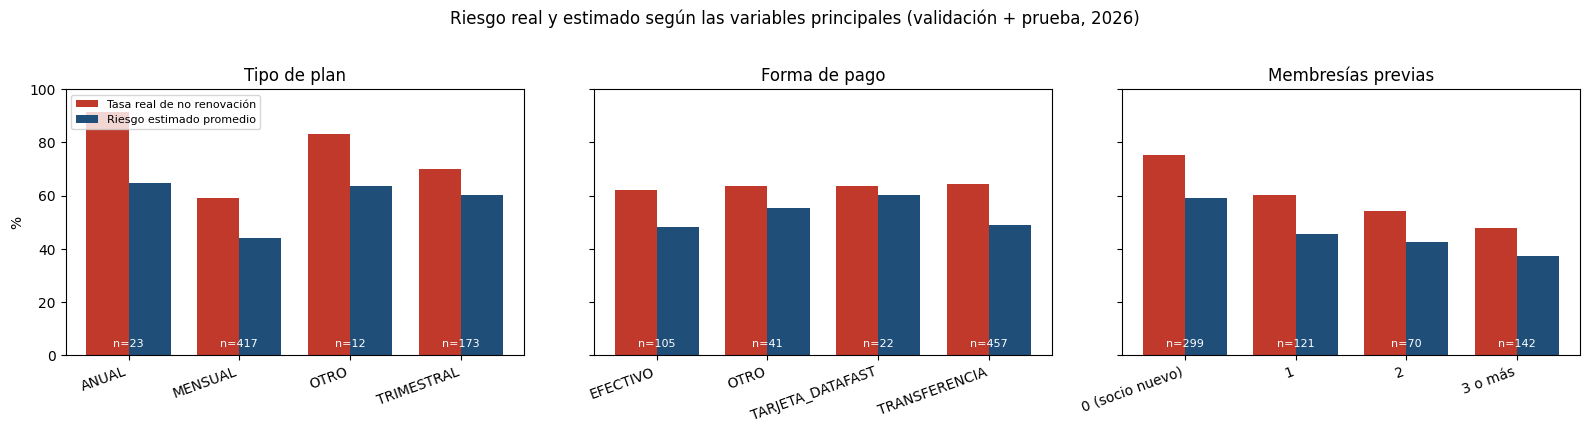

In [57]:
evaluacion_2026 = pd.concat([validation, test]).copy()
evaluacion_2026["riesgo_estimado"] = modelo_seleccionado.predict_proba(evaluacion_2026[VARIABLES_MODELO])[:, 1]
evaluacion_2026["membresias_previas"] = pd.cut(evaluacion_2026["ciclos_previos"], bins=[-1, 0, 1, 2, 100],
                                               labels=["0 (socio nuevo)", "1", "2", "3 o más"])

def perfil(variable, minimo=10):
    # Tasa real y riesgo estimado promedio por cada valor de la variable (grupos con al menos 'minimo' ciclos)
    t = (evaluacion_2026.groupby(variable, observed=True)
         .agg(ciclos=("no_renovo", "size"), tasa_real=("no_renovo", "mean"), riesgo_estimado=("riesgo_estimado", "mean"))
         .query("ciclos >= @minimo").reset_index())
    t.insert(0, "variable", variable)
    return t.rename(columns={variable: "valor"})

perfiles = pd.concat([perfil("plan"), perfil("forma_pago"), perfil("membresias_previas")], ignore_index=True)
display(perfiles.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, var, titulo in zip(axes, ["plan", "forma_pago", "membresias_previas"],
                           ["Tipo de plan", "Forma de pago", "Membresías previas"]):
    t = perfiles.loc[perfiles["variable"] == var]
    x = np.arange(len(t)); w = 0.38
    ax.bar(x - w/2, 100 * t["tasa_real"], w, label="Tasa real de no renovación", color=COLORES["rojo"])
    ax.bar(x + w/2, 100 * t["riesgo_estimado"], w, label="Riesgo estimado promedio", color=COLORES["azul"])
    for i, n in enumerate(t["ciclos"]):
        ax.text(i, 3, f"n={n}", ha="center", fontsize=8, color="white")
    ax.set_xticks(x); ax.set_xticklabels(t["valor"].astype(str), rotation=20, ha="right")
    ax.set_title(titulo); ax.set_ylim(0, 100)
axes[0].set_ylabel("%"); axes[0].legend(fontsize=8, loc="upper left")
plt.suptitle("Riesgo real y estimado según las variables principales (validación + prueba, 2026)", y=1.02)
plt.tight_layout(); plt.show()

#### Interpretación de los resultados

Cuando la barra azul (riesgo estimado) sube y baja junto con la barra roja (tasa real), el modelo está capturando correctamente la **dirección** del efecto de la variable. Los hallazgos principales son:

- **Membresías previas:** es el efecto más claro y ordenado. Los socios **nuevos** no renuevan en ≈75 % de los casos; con 1 membresía previa ≈60 %, con 2 ≈54 % y con 3 o más ≈48 %. El riesgo estimado desciende en el mismo orden: **a mayor historia con el gimnasio, menor riesgo**.
- **Tipo de plan:** los planes **mensuales** presentan la menor no renovación (≈59 %), mientras que **trimestrales** (≈70 %) y **anuales** (≈91 %, con solo 23 casos) presentan más; el modelo reproduce este orden. En los planes largos, la renovación ocurre con menos frecuencia dentro de la ventana de 30 días.
- **Forma de pago:** las diferencias reales entre medios de pago son pequeñas (≈62–64 %), por lo que su importancia en el modelo proviene principalmente de su combinación con otras variables.
 Las diferencias de nivel entre ambas barras (el azul suele quedar por debajo del rojo) corresponden al problema de calibración ya señalado, no a un error de ordenamiento. Esta tabla, junto con la importancia global y la explicación individual de la Sección 13.3, constituye la **explicación de variables** del sistema: qué variables pesan (12.9), en qué sentido influyen (12.10) y por qué un socio concreto aparece en la lista (13.3).

---
# Parte 13 · El producto: listas mensuales priorizadas

*Responde a la observación del tutor: "realicen listas mensuales considerando este ejemplo" (vencimiento 20 de agosto → aún no se puede confirmar la no renovación).*

## Sección 13.1 · Estimación del riesgo para los ciclos a priorizar

**Descripción.** Se aplica el modelo seleccionado a **todos** los ciclos con calidad suficiente cuya fecha T−30 ya ocurrió, **incluidos los pendientes** de agosto.

**Justificación.** En la operación real la lista se genera en T−30, cuando todavía no se sabe qué pasará. Por eso los pendientes **sí reciben una probabilidad**, aunque no tengan todavía un resultado real.

**Objetivo.** tener un puntaje de riesgo para cada ciclo que pueda aparecer en una lista mensual.

In [58]:
ciclos_para_lista = datos_modelables.loc[
    datos_modelables["fecha_prediccion"].notna() & (datos_modelables["fecha_prediccion"] <= fecha_corte_datos)
].copy()
ciclos_para_lista["probabilidad_no_renovacion"] = modelo_seleccionado.predict_proba(ciclos_para_lista[VARIABLES_MODELO])[:, 1]
print("Ciclos con una predicción disponible:", len(ciclos_para_lista))

Ciclos con una predicción disponible: 1660


## Sección 13.2 · Niveles de riesgo y código anónimo

**Descripción.**
1. Se asigna un **nivel visual**: ALTO (≥ 0,70), MEDIO (0,50–0,70), BAJO (< 0,50). Solo facilita la lectura; **la prioridad real es el orden** por probabilidad.
2. Se crea un **código anónimo** (`MTB-XXXXXXXX`) para cada socio mediante una función hash (una "huella digital" irreversible del identificador).

**Justificación.** Para que el informe académico, las capturas y la defensa **no muestren nombres, cédulas ni teléfonos**. La aplicación interna de Mtabolic sí puede mostrar el nombre, con acceso controlado.

**Objetivo.** listas legibles y respetuosas de la privacidad.

In [59]:
def nivel_riesgo(p):
    return "ALTO" if p >= 0.70 else ("MEDIO" if p >= 0.50 else "BAJO")

def id_anonimo(socio_id):
    return "MTB-" + hashlib.sha256(str(socio_id).encode("utf-8")).hexdigest()[:8].upper()   # huella irreversible

ciclos_para_lista["nivel_riesgo"] = ciclos_para_lista["probabilidad_no_renovacion"].apply(nivel_riesgo)
ciclos_para_lista["socio_anonimo"] = ciclos_para_lista["socio_id"].apply(id_anonimo)
display(ciclos_para_lista["nivel_riesgo"].value_counts().rename_axis("nivel").reset_index(name="ciclos"))

,nivel,ciclos
0,MEDIO,1053
1,BAJO,549
2,ALTO,58


**Nota:** como las probabilidades están desplazadas hacia abajo (Sección 12.5), casi ningún socio aparece como ALTO. Esto **no** significa que haya pocos socios en riesgo: significa que los niveles deben recalibrarse. Por eso la lista se construye con el **orden**, no con el nivel.

## Sección 13.3 · Explicación individual del riesgo de cada socio

**Descripción.** Para cada socio de la lista se identifica **qué características suyas elevan o reducen su riesgo**. Para ello se lo compara con un **socio típico** (el socio "promedio" del período de entrenamiento: plan más común, forma de pago más común, antigüedad y montos habituales, etc.).

El procedimiento es sencillo y se repite para cada característica:

1. Se calcula el riesgo del socio tal como es. Por ejemplo, **70 %**.
2. Se cambia **una sola** de sus características por la del socio típico, dejando todo lo demás igual. Por ejemplo, su plan trimestral se reemplaza por el plan mensual (el más común), y se vuelve a calcular el riesgo: **61 %**.
3. La diferencia (70 % − 61 % = **+9 puntos**) es el **aporte** de esa característica. En este caso, tener plan trimestral **eleva** su riesgo en 9 puntos.

Si al cambiar la característica el riesgo **baja**, esa característica **eleva** el riesgo del socio (aporte positivo). Si al cambiarla el riesgo **sube**, esa característica lo **protege** (aporte negativo). Con esta información, cada fila de la lista incluye los **tres factores que más elevan su riesgo**, escritos por ejemplo como "Plan: TRIMESTRAL (+0,09)", que significa "+9 puntos de riesgo por tener plan trimestral".

**Justificación.** La importancia global (Sección 12.9) describe el modelo en conjunto, pero el personal de Mtabolic necesita saber **por qué un socio concreto** aparece en la lista para preparar el contacto (por ejemplo, "socio nuevo con plan trimestral"). Es la "información explicativa" comprometida en el alcance del proyecto.

**Objetivo.** que cada recomendación de la lista sea **explicable** de forma individual.

**Nota metodológica:** en la literatura este procedimiento se conoce como explicación local por sustitución. Funciona con cualquier modelo y no requiere librerías adicionales. Una alternativa futura, con el mismo propósito, es el método SHAP.

In [60]:
# Valores de referencia: socio "típico" del período de entrenamiento
REFERENCIA = {v: X_train[v].median() for v in VARIABLES_NUMERICAS}
REFERENCIA.update({v: X_train[v].mode().iloc[0] for v in VARIABLES_CATEGORICAS})

# Nombres comprensibles para el personal de Mtabolic (mes_vencimiento no se explica: no es accionable)
NOMBRE_VARIABLE = {
    "ciclos_previos": "Membresías previas", "antiguedad_dias": "Antigüedad (días)",
    "duracion_modelo": "Duración del plan (días)", "monto_actual": "Monto actual (USD)",
    "monto_historico": "Monto histórico (USD)", "dias_desde_ultima_membresia": "Días desde la membresía anterior",
    "plan": "Plan", "forma_pago": "Forma de pago", "inicio_aproximado": "Fecha de inicio aproximada",
}

def aportes_individuales(modelo, X):
    # Devuelve una tabla (ciclos x variables) con el aporte de cada variable a la probabilidad
    base = modelo.predict_proba(X)[:, 1]
    aportes = {}
    for v in NOMBRE_VARIABLE:
        X_ref = X.copy()
        X_ref[v] = REFERENCIA[v]                                   # sustituimos solo esta variable
        aportes[v] = base - modelo.predict_proba(X_ref)[:, 1]      # cuánto cambia el riesgo
    return pd.DataFrame(aportes, index=X.index)

def texto_valor(v, valor):
    if pd.isna(valor):
        return "sin dato"
    if v in VARIABLES_NUMERICAS:
        return f"{valor:,.0f}".replace(",", ".")
    if v == "inicio_aproximado":
        return "sí" if str(valor) == "True" else "no"
    return str(valor)

def factores_principales(modelo, X, n=3):
    # Texto con los n factores que más ELEVAN el riesgo de cada ciclo
    aportes = aportes_individuales(modelo, X)
    textos = []
    for idx, fila in aportes.iterrows():
        positivos = fila[fila > 0.005].sort_values(ascending=False).head(n)
        if positivos.empty:
            textos.append("Sin factores de riesgo destacados")
            continue
        textos.append("; ".join(f"{NOMBRE_VARIABLE[v]}: {texto_valor(v, X.at[idx, v])} ({es(a, 2, True)})"
                                for v, a in positivos.items()))
    return pd.Series(textos, index=X.index), aportes

ciclos_para_lista["factores_principales"], aportes_lista = factores_principales(
    modelo_seleccionado, ciclos_para_lista[VARIABLES_MODELO])

# Ejemplo: los cinco ciclos de mayor riesgo de julio 2026 con su explicación
ejemplo = (ciclos_para_lista.loc[ciclos_para_lista["mes_vencimiento"] == "2026-07"]
           .sort_values("probabilidad_no_renovacion", ascending=False).head(5))
display(ejemplo[["socio_anonimo", "plan", "forma_pago", "ciclos_previos",
                 "probabilidad_no_renovacion", "factores_principales"]].round(3))

,socio_anonimo,plan,forma_pago,ciclos_previos,probabilidad_no_renovacion,factores_principales
5911,MTB-381BEF96,TRIMESTRAL,OTRO,0.0,0.708,"Plan: TRIMESTRAL (+0,09); Forma de pago: OTRO (+0,08); Duración del plan (días): 91 (+0,03)"
5874,MTB-31371ECE,TRIMESTRAL,EFECTIVO,0.0,0.706,"Plan: TRIMESTRAL (+0,09); Forma de pago: EFECTIVO (+0,07); Duración del plan (días): 91 (+0,03)"
6007,MTB-A5B0875B,TRIMESTRAL,TRANSFERENCIA,0.0,0.642,"Plan: TRIMESTRAL (+0,07); Duración del plan (días): 91 (+0,02); Monto actual (USD): 88 (+0,01)"
6008,MTB-58E6C24B,TRIMESTRAL,TRANSFERENCIA,0.0,0.642,"Plan: TRIMESTRAL (+0,07); Duración del plan (días): 91 (+0,02); Monto actual (USD): 88 (+0,01)"
5759,MTB-85E4348D,TRIMESTRAL,TRANSFERENCIA,0.0,0.633,"Plan: TRIMESTRAL (+0,06); Duración del plan (días): 91 (+0,02)"


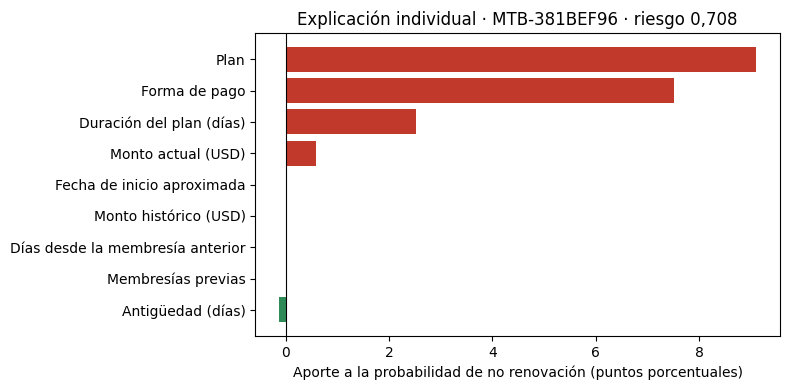

,factor,veces_entre_los_3_principales
0,Plan,140
1,Monto actual (USD),127
2,Duración del plan (días),96
3,Forma de pago,73
4,Antigüedad (días),50
5,Fecha de inicio aproximada,9


In [61]:
# Gráfico: explicación del socio de mayor riesgo de julio 2026 (aporte de cada variable)
idx0 = ejemplo.index[0]
a0 = aportes_lista.loc[idx0].rename(index=NOMBRE_VARIABLE).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(a0.index, 100 * a0.values, color=[COLORES["rojo"] if v > 0 else COLORES["verde"] for v in a0.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Aporte a la probabilidad de no renovación (puntos porcentuales)")
ax.set_title(f"Explicación individual · {ejemplo.at[idx0, 'socio_anonimo']} · "
             f"riesgo {es(ejemplo.at[idx0, 'probabilidad_no_renovacion'], 3)}")
plt.tight_layout(); plt.show()

# Resumen: con qué frecuencia cada variable aparece como factor principal en los top 25 de 2026
top_2026 = pd.concat([ciclos_para_lista.loc[ciclos_para_lista["mes_vencimiento"] == p]
                      .sort_values("probabilidad_no_renovacion", ascending=False)
                      .drop_duplicates("socio_id").head(TOP_K)
                      for p in sorted(ciclos_para_lista["mes_vencimiento"].unique()) if p >= "2026-01"])
frecuencia = (aportes_lista.loc[top_2026.index].apply(lambda f: f[f > 0.005].nlargest(3).index.tolist(), axis=1)
              .explode().map(NOMBRE_VARIABLE).value_counts().rename_axis("factor").reset_index(name="veces_entre_los_3_principales"))
display(frecuencia)

#### Interpretación de los resultados

En los socios de mayor riesgo de 2026, los factores que aparecen con más frecuencia entre los tres principales son el **tipo de plan** (en especial el trimestral), el **monto actual**, la **duración del plan** y la **forma de pago**, seguidos de la **antigüedad**. En el gráfico, las barras **rojas** son las características que **elevan** el riesgo del socio frente a un socio típico y las **verdes** las que lo **reducen**; la suma de todas explica la distancia entre el riesgo del socio y el de referencia. La tabla de frecuencias muestra qué factores explican con más frecuencia la presencia de un socio en las listas de 2026. De esta forma, cada recomendación va acompañada de su justificación, y el personal puede adaptar el contacto al motivo (por ejemplo, reforzar el seguimiento de socios nuevos o de planes con mayor abandono).

## Sección 13.4 · Generación de la lista mensual

**Descripción.** Dado un mes de vencimiento (por ejemplo `"2026-08"`), la función toma los ciclos que vencen ese mes, los ordena de mayor a menor probabilidad, **conserva una sola fila por socio** (la de mayor riesgo) y devuelve los primeros `TOP_K` (25). Para cada socio muestra las tres fechas clave (T−30, T, T+30), los **factores principales** de su riesgo y el **resultado real** si ya se conoce, o **"Pendiente de observación"** si no.

**Consolidación por socio:** en la base existen registros duplicados o varios ciclos de una misma persona que vencen en el mismo mes (Sección 5.4). Como el personal contacta **personas** y no ciclos, la lista agrupa por `socio_id` y conserva el ciclo con mayor probabilidad. Así, cada uno de los 25 cupos de contacto corresponde a un socio distinto.

**Justificación.** Es el entregable operativo: la lista que la asesora usaría al inicio de cada mes.

**Objetivo.** listas mensuales reproducibles, que respetan la regla del ejemplo del tutor.

In [62]:
def lista_mensual(periodo, top_k=TOP_K, mostrar_datos_personales=False):
    lista = (ciclos_para_lista.loc[ciclos_para_lista["mes_vencimiento"] == periodo]
             .sort_values("probabilidad_no_renovacion", ascending=False)
             .drop_duplicates("socio_id", keep="first")      # una sola fila por socio (la de mayor riesgo)
             .copy())
    lista["prioridad"] = np.arange(1, len(lista) + 1)
    columnas = ["prioridad", "socio_anonimo", "fecha_prediccion", "fecha_fin", "fecha_limite_observacion",
                "plan", "probabilidad_no_renovacion", "nivel_riesgo", "factores_principales", "resultado_real"]
    if mostrar_datos_personales:            # solo para uso interno de Mtabolic
        columnas.insert(2, "nombre")
    return lista[columnas].head(top_k).rename(columns={
        "fecha_prediccion": "T−30 (lista)", "fecha_fin": "T (vence)", "fecha_limite_observacion": "T+30 (verificación)",
        "probabilidad_no_renovacion": "probabilidad", "factores_principales": "factores principales",
        "resultado_real": "resultado real"})

def mostrar_lista(periodo, top_k=TOP_K):
    # Muestra la lista del mes y un resumen de cuántos priorizados renovaron, no renovaron o siguen pendientes
    tabla = lista_mensual(periodo, top_k)
    del_mes = ciclos_para_lista.loc[ciclos_para_lista["mes_vencimiento"] == periodo]
    print(f"LISTA PRIORIZADA · vencimientos de {periodo} · top {len(tabla)} de {del_mes['socio_id'].nunique()} socios "
          f"({len(del_mes)} ciclos; los ciclos repetidos de un mismo socio se consolidan en una sola fila)")
    display(tabla.assign(probabilidad=tabla["probabilidad"].round(3)).set_index("prioridad"))
    conteo = tabla["resultado real"].value_counts()
    print("Resultado real de los socios de la lista:", ", ".join(f"{k}: {v}" for k, v in conteo.items()))
    if (tabla["resultado real"] == "Pendiente de observación").any():
        print(f"Los pendientes tienen su ventana T+30 después del {fecha_corte_datos:%d-%m-%Y}: "
              "NO se clasifican como no renovación.")

## Sección 13.5 · Lista de agosto 2026 y aplicación del ejemplo del tutor

**Descripción.** Se genera la lista de los socios que vencen en agosto 2026.

**Aspecto a destacar:** los socios cuyo T+30 cae después del 31 de agosto aparecen como **"Pendiente de observación"**, nunca como "No renovó". Por ejemplo, un socio que vence el 20 de agosto tiene T+30 = 19 de septiembre: todavía no se puede confirmar si renovó.

In [63]:
mostrar_lista("2026-08")

LISTA PRIORIZADA · vencimientos de 2026-08 · top 25 de 97 socios (100 ciclos; los ciclos repetidos de un mismo socio se consolidan en una sola fila)


,socio_anonimo,T−30 (lista),T (vence),T+30 (verificación),plan,probabilidad,nivel_riesgo,factores principales,resultado real
prioridad,,,,,,,,,
1,MTB-2F8DBFDD,2026-08-01,2026-08-31,2026-09-30,OTRO,0.671,MEDIO,"Plan: OTRO (+0,08); Monto actual (USD): 49 (+0,02); Duración del plan (días): 49 (+0,02)",Pendiente de observación
2,MTB-ACECE793,2026-07-30,2026-08-29,2026-09-28,MENSUAL,0.666,MEDIO,"Monto actual (USD): 25 (+0,07); Forma de pago: EFECTIVO (+0,03); Antigüedad (días): 1 (+0,03)",Pendiente de observación
3,MTB-E901B9F4,2026-07-11,2026-08-10,2026-09-09,MENSUAL,0.666,MEDIO,"Monto actual (USD): 10 (+0,07); Forma de pago: EFECTIVO (+0,03); Antigüedad (días): 1 (+0,03)",Pendiente de observación
4,MTB-9A73DCED,2026-07-30,2026-08-29,2026-09-28,MENSUAL,0.666,MEDIO,"Monto actual (USD): 25 (+0,07); Forma de pago: EFECTIVO (+0,03); Antigüedad (días): 1 (+0,03)",Pendiente de observación
5,MTB-D2D43466,2026-07-04,2026-08-03,2026-09-02,MENSUAL,0.666,MEDIO,"Monto actual (USD): 20 (+0,07); Forma de pago: EFECTIVO (+0,03); Antigüedad (días): 1 (+0,03)",Pendiente de observación
6,MTB-157513F9,2026-07-02,2026-08-01,2026-08-31,MENSUAL,0.640,MEDIO,"Fecha de inicio aproximada: sí (+0,11); Antigüedad (días): 1 (+0,05)",Renovó
7,MTB-878296CC,2026-08-01,2026-08-31,2026-09-30,MENSUAL,0.632,MEDIO,"Monto actual (USD): 30 (+0,09); Antigüedad (días): 1 (+0,02)",Pendiente de observación
8,MTB-0CADCDEB,2026-07-28,2026-08-27,2026-09-26,MENSUAL,0.631,MEDIO,"Monto actual (USD): 25 (+0,09); Antigüedad (días): 1 (+0,02)",Pendiente de observación
9,MTB-0B78FCD7,2026-07-30,2026-08-29,2026-09-28,MENSUAL,0.631,MEDIO,"Monto actual (USD): 25 (+0,09); Antigüedad (días): 1 (+0,02)",Pendiente de observación


Resultado real de los socios de la lista: Pendiente de observación: 24, Renovó: 1
Los pendientes tienen su ventana T+30 después del 31-08-2026: NO se clasifican como no renovación.


In [64]:
# Control automático: ningún pendiente de agosto recibió una etiqueta de "no renovó"
pendientes_agosto = ciclos_para_lista.loc[(ciclos_para_lista["mes_vencimiento"] == "2026-08")
                                          & (ciclos_para_lista["resultado_real"] == "Pendiente de observación")]
assert pendientes_agosto["no_renovo"].isna().all()
print(f"Control aprobado: los {len(pendientes_agosto)} casos pendientes de agosto 2026 NO fueron tratados como no renovación.")

# Caso puntual equivalente al ejemplo del tutor (vencimiento el 20 de agosto o el más cercano)
ag = ciclos_para_lista.loc[ciclos_para_lista["mes_vencimiento"] == "2026-08"].copy()
caso = ag.iloc[(ag["fecha_fin"] - pd.Timestamp("2026-08-20")).abs().argsort()[:1]]
display(caso[["socio_anonimo", "fecha_prediccion", "fecha_fin", "fecha_limite_observacion",
             "probabilidad_no_renovacion", "resultado_real"]])

Control aprobado: los 96 casos pendientes de agosto 2026 NO fueron tratados como no renovación.


,socio_anonimo,fecha_prediccion,fecha_fin,fecha_limite_observacion,probabilidad_no_renovacion,resultado_real
6450,MTB-05045DCD,2026-07-21,2026-08-20,2026-09-19,0.551325,Pendiente de observación


## Sección 13.6 · Listas mensuales de 2026 (enero a julio)

**Descripción.** Se generan las listas de cada mes de 2026 con resultado ya conocido.

**Justificación.** Permiten comprobar **mes a mes** cómo habría funcionado el sistema si se hubiera usado en la práctica: la columna "resultado real" muestra cuántos de los priorizados efectivamente no renovaron.

**Nota:** enero–abril pertenecen a validación y mayo–julio a prueba. Las listas de 2025 (entrenamiento) también se generan y se exportan en la Parte 14, pero no se muestran porque el modelo aprendió de esos meses.

LISTA PRIORIZADA · vencimientos de 2026-01 · top 25 de 73 socios (76 ciclos; los ciclos repetidos de un mismo socio se consolidan en una sola fila)


,socio_anonimo,T−30 (lista),T (vence),T+30 (verificación),plan,probabilidad,nivel_riesgo,factores principales,resultado real
prioridad,,,,,,,,,
1,MTB-7927161B,2025-12-19,2026-01-18,2026-02-17,OTRO,0.712,ALTO,"Plan: OTRO (+0,10); Forma de pago: TARJETA_DATAFAST (+0,05); Duración del plan (días): 61 (+0,03)",Renovó
2,MTB-0542F40A,2025-12-14,2026-01-13,2026-02-12,ANUAL,0.681,MEDIO,"Forma de pago: TARJETA_DATAFAST (+0,06); Plan: ANUAL (+0,05); Fecha de inicio aproximada: sí (+0,02)",No renovó
3,MTB-767AB7B9,2026-01-01,2026-01-31,2026-03-02,SEMESTRAL,0.672,MEDIO,"Forma de pago: OTRO (+0,07); Plan: SEMESTRAL (+0,06); Monto actual (USD): 200 (+0,01)",No renovó
4,MTB-5993D45E,2025-12-28,2026-01-27,2026-02-26,ANUAL,0.671,MEDIO,"Forma de pago: OTRO (+0,07); Plan: ANUAL (+0,06); Monto actual (USD): 450 (+0,01)",No renovó
5,MTB-115EFB82,2025-12-08,2026-01-07,2026-02-06,ANUAL,0.671,MEDIO,"Forma de pago: OTRO (+0,07); Plan: ANUAL (+0,06); Monto actual (USD): 450 (+0,01)",No renovó
6,MTB-E6C3A541,2025-12-12,2026-01-11,2026-02-10,ANUAL,0.671,MEDIO,"Forma de pago: OTRO (+0,07); Plan: ANUAL (+0,06); Monto actual (USD): 225 (+0,01)",No renovó
7,MTB-44ED79B4,2025-12-30,2026-01-29,2026-02-28,TRIMESTRAL,0.671,MEDIO,"Forma de pago: OTRO (+0,08); Plan: TRIMESTRAL (+0,07); Monto actual (USD): 75 (+0,01)",Renovó
8,MTB-D831463E,2025-12-21,2026-01-20,2026-02-19,OTRO,0.667,MEDIO,"Plan: OTRO (+0,09); Monto actual (USD): 60 (+0,03); Duración del plan (días): 61 (+0,03)",Renovó
9,MTB-22C0139C,2025-12-09,2026-01-08,2026-02-07,ANUAL,0.667,MEDIO,"Forma de pago: SIN_DATO (+0,06); Plan: ANUAL (+0,06); Monto actual (USD): 250 (+0,01)",Renovó


Resultado real de los socios de la lista: No renovó: 18, Renovó: 7
LISTA PRIORIZADA · vencimientos de 2026-02 · top 25 de 102 socios (102 ciclos; los ciclos repetidos de un mismo socio se consolidan en una sola fila)


,socio_anonimo,T−30 (lista),T (vence),T+30 (verificación),plan,probabilidad,nivel_riesgo,factores principales,resultado real
prioridad,,,,,,,,,
1,MTB-2FC25B60,2026-01-21,2026-02-20,2026-03-22,ANUAL,0.671,MEDIO,"Forma de pago: OTRO (+0,07); Plan: ANUAL (+0,06); Monto actual (USD): 225 (+0,01)",No renovó
2,MTB-12D68ED5,2026-01-28,2026-02-27,2026-03-29,TRIMESTRAL,0.670,MEDIO,"Forma de pago: EFECTIVO (+0,08); Plan: TRIMESTRAL (+0,07); Monto actual (USD): 45 (+0,01)",No renovó
3,MTB-FD732D41,2026-01-06,2026-02-05,2026-03-07,MENSUAL,0.669,MEDIO,"Fecha de inicio aproximada: sí (+0,10); Antigüedad (días): 5 (+0,06); Forma de pago: EFECTIVO (+0,02)",No renovó
4,MTB-84A1D9F9,2026-01-27,2026-02-26,2026-03-28,SEMESTRAL,0.668,MEDIO,"Forma de pago: EFECTIVO (+0,06); Plan: SEMESTRAL (+0,05); Monto actual (USD): 150 (+0,01)",No renovó
5,MTB-EEDE9AFC,2026-01-27,2026-02-26,2026-03-28,SEMESTRAL,0.668,MEDIO,"Forma de pago: EFECTIVO (+0,06); Plan: SEMESTRAL (+0,05); Monto actual (USD): 150 (+0,01)",No renovó
6,MTB-35E8CE65,2026-01-03,2026-02-02,2026-03-04,ANUAL,0.666,MEDIO,"Forma de pago: TARJETA_DATAFAST (+0,06); Plan: ANUAL (+0,06); Monto actual (USD): 449 (+0,02)",No renovó
7,MTB-066C4B6F,2026-01-15,2026-02-14,2026-03-16,ANUAL,0.666,MEDIO,"Forma de pago: TARJETA_DATAFAST (+0,06); Plan: ANUAL (+0,06); Monto actual (USD): 225 (+0,02)",No renovó
8,MTB-7AC04B92,2026-01-11,2026-02-10,2026-03-12,TRIMESTRAL,0.657,MEDIO,"Forma de pago: EFECTIVO (+0,08); Plan: TRIMESTRAL (+0,06)",Renovó
9,MTB-D1DE4AC4,2026-01-15,2026-02-14,2026-03-16,MENSUAL,0.655,MEDIO,"Fecha de inicio aproximada: sí (+0,11); Antigüedad (días): 14 (+0,06)",No renovó


Resultado real de los socios de la lista: No renovó: 15, Renovó: 10
LISTA PRIORIZADA · vencimientos de 2026-03 · top 25 de 69 socios (69 ciclos; los ciclos repetidos de un mismo socio se consolidan en una sola fila)


...

Resultado real de los socios de la lista: No renovó: 18, Renovó: 7
LISTA PRIORIZADA · vencimientos de 2026-06 · top 25 de 83 socios (86 ciclos; los ciclos repetidos de un mismo socio se consolidan en una sola fila)


,socio_anonimo,T−30 (lista),T (vence),T+30 (verificación),plan,probabilidad,nivel_riesgo,factores principales,resultado real
prioridad,,,,,,,,,
1,MTB-06140001,2026-05-09,2026-06-08,2026-07-08,OTRO,0.755,ALTO,"Fecha de inicio aproximada: sí (+0,05); Antigüedad (días): 8 (+0,04); Plan: OTRO (+0,03)",No renovó
2,MTB-AA14A026,2026-05-10,2026-06-09,2026-07-09,TRIMESTRAL,0.657,MEDIO,"Forma de pago: OTRO (+0,08); Plan: TRIMESTRAL (+0,06)",No renovó
3,MTB-C554318A,2026-05-03,2026-06-02,2026-07-02,TRIMESTRAL,0.657,MEDIO,"Forma de pago: OTRO (+0,08); Plan: TRIMESTRAL (+0,06)",No renovó
4,MTB-FF60C45F,2026-05-10,2026-06-09,2026-07-09,TRIMESTRAL,0.657,MEDIO,"Forma de pago: EFECTIVO (+0,08); Plan: TRIMESTRAL (+0,06)",No renovó
5,MTB-763BFBB2,2026-05-21,2026-06-20,2026-07-20,MENSUAL,0.632,MEDIO,"Monto actual (USD): 30 (+0,09); Antigüedad (días): 1 (+0,02)",Renovó
6,MTB-D35E8325,2026-05-07,2026-06-06,2026-07-06,MENSUAL,0.632,MEDIO,"Monto actual (USD): 30 (+0,09); Antigüedad (días): 1 (+0,02)",No renovó
7,MTB-3E41353C,2026-05-07,2026-06-06,2026-07-06,MENSUAL,0.632,MEDIO,"Monto actual (USD): 30 (+0,09); Antigüedad (días): 1 (+0,02)",No renovó
8,MTB-891076D0,2026-05-08,2026-06-07,2026-07-07,MENSUAL,0.632,MEDIO,"Monto actual (USD): 30 (+0,09); Antigüedad (días): 1 (+0,02)",No renovó
9,MTB-164F1C3C,2026-05-16,2026-06-15,2026-07-15,MENSUAL,0.632,MEDIO,"Monto actual (USD): 30 (+0,09); Antigüedad (días): 1 (+0,02)",Renovó


Resultado real de los socios de la lista: No renovó: 21, Renovó: 4
LISTA PRIORIZADA · vencimientos de 2026-07 · top 25 de 92 socios (93 ciclos; los ciclos repetidos de un mismo socio se consolidan en una sola fila)


,socio_anonimo,T−30 (lista),T (vence),T+30 (verificación),plan,probabilidad,nivel_riesgo,factores principales,resultado real
prioridad,,,,,,,,,
1,MTB-381BEF96,2026-06-15,2026-07-15,2026-08-14,TRIMESTRAL,0.708,ALTO,"Plan: TRIMESTRAL (+0,09); Forma de pago: OTRO (+0,08); Duración del plan (días): 91 (+0,03)",No renovó
2,MTB-31371ECE,2026-06-13,2026-07-13,2026-08-12,TRIMESTRAL,0.706,ALTO,"Plan: TRIMESTRAL (+0,09); Forma de pago: EFECTIVO (+0,07); Duración del plan (días): 91 (+0,03)",No renovó
3,MTB-A5B0875B,2026-06-22,2026-07-22,2026-08-21,TRIMESTRAL,0.642,MEDIO,"Plan: TRIMESTRAL (+0,07); Duración del plan (días): 91 (+0,02); Monto actual (USD): 88 (+0,01)",No renovó
4,MTB-58E6C24B,2026-06-22,2026-07-22,2026-08-21,TRIMESTRAL,0.642,MEDIO,"Plan: TRIMESTRAL (+0,07); Duración del plan (días): 91 (+0,02); Monto actual (USD): 88 (+0,01)",No renovó
5,MTB-85E4348D,2026-06-06,2026-07-06,2026-08-05,TRIMESTRAL,0.633,MEDIO,"Plan: TRIMESTRAL (+0,06); Duración del plan (días): 91 (+0,02)",No renovó
6,MTB-0D4222C9,2026-06-06,2026-07-06,2026-08-05,TRIMESTRAL,0.633,MEDIO,"Plan: TRIMESTRAL (+0,06); Duración del plan (días): 91 (+0,02)",No renovó
7,MTB-5C3B9D9B,2026-06-13,2026-07-13,2026-08-12,TRIMESTRAL,0.633,MEDIO,"Plan: TRIMESTRAL (+0,06); Duración del plan (días): 91 (+0,02)",No renovó
8,MTB-11CDB390,2026-06-15,2026-07-15,2026-08-14,TRIMESTRAL,0.633,MEDIO,"Plan: TRIMESTRAL (+0,06); Duración del plan (días): 91 (+0,02)",No renovó
9,MTB-5A6AA593,2026-06-06,2026-07-06,2026-08-05,TRIMESTRAL,0.633,MEDIO,"Plan: TRIMESTRAL (+0,06); Duración del plan (días): 91 (+0,02)",No renovó


Resultado real de los socios de la lista: No renovó: 22, Renovó: 3


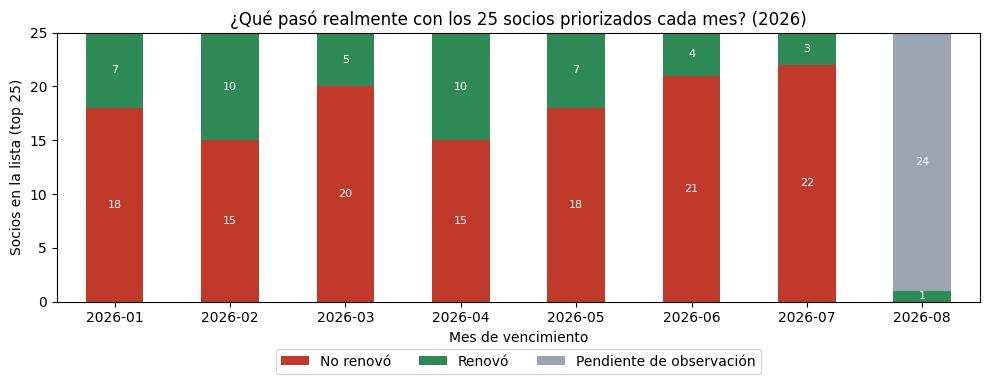

In [65]:
periodos_disponibles = sorted(ciclos_para_lista["mes_vencimiento"].dropna().unique())
for periodo in [p for p in periodos_disponibles if str(p).startswith("2026-") and p != "2026-08"]:
    mostrar_lista(periodo)

# Gráfico resumen: composición de cada lista de 25 según lo que realmente pasó
comp = pd.DataFrame({p: lista_mensual(p)["resultado real"].value_counts()
                     for p in periodos_disponibles if str(p).startswith("2026-")}).T.fillna(0)
comp = comp.reindex(columns=["No renovó", "Renovó", "Pendiente de observación"], fill_value=0)
ax = comp.plot(kind="bar", stacked=True, figsize=(10, 4), rot=0,
               color=[COLORES["rojo"], COLORES["verde"], COLORES["gris"]])
for c in ax.containers:
    ax.bar_label(c, labels=[f"{int(v)}" if v > 0 else "" for v in c.datavalues], label_type="center",
                 color="white", fontsize=8)
ax.set_ylabel("Socios en la lista (top 25)"); ax.set_xlabel("Mes de vencimiento")
ax.set_title("¿Qué pasó realmente con los 25 socios priorizados cada mes? (2026)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.tight_layout()
plt.show()

## Sección 13.7 · Efectividad mensual de las listas

**Descripción.** Se resume, en una tabla y dos gráficos, para cada mes cuántos de los 25 priorizados no renovaron y se compara con la tasa del mes (lo que se obtendría eligiendo al azar).

**Objetivo.** una sola tabla que muestre la utilidad de las listas en el tiempo.

,mes,particion,ciclos_del_mes,en_lista,pendientes_en_lista,tasa_no_renovacion_mes,precision_de_la_lista,lift,socios_distintos_en_lista,socios_repetidos_en_lista
11,2026-01,validación,76,25,0,0.605,0.72,1.190,25,0
12,2026-02,validación,102,25,0,0.657,0.60,0.913,25,0
13,2026-03,validación,69,25,0,0.652,0.80,1.227,25,0
14,2026-04,validación,108,25,0,0.565,0.60,1.062,25,0
15,2026-05,prueba,94,25,0,0.660,0.72,1.092,25,0
16,2026-06,prueba,86,25,0,0.628,0.84,1.338,25,0
17,2026-07,prueba,93,25,0,0.731,0.88,1.204,25,0
18,2026-08,prueba,100,25,24,0.250,NaN,NaN,25,0


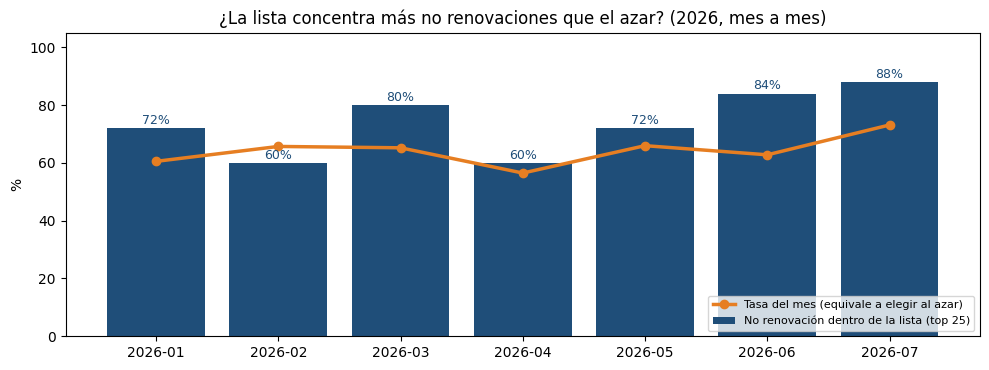

In [66]:
listas_mensuales = {p: lista_mensual(p, top_k=TOP_K) for p in periodos_disponibles}
filas = []
for p, tabla in listas_mensuales.items():
    todos = ciclos_para_lista.loc[ciclos_para_lista["mes_vencimiento"] == p]
    conocidos_mes = todos["no_renovo"].notna()
    conocidos_lista = tabla["resultado real"].isin(["Renovó", "No renovó"])
    tasa_mes = todos.loc[conocidos_mes, "no_renovo"].mean() if conocidos_mes.any() else np.nan
    # Si la lista tiene menos de 5 resultados conocidos (caso agosto), la precisión no es interpretable
    prec_lista = (tabla.loc[conocidos_lista, "resultado real"] == "No renovó").mean() if conocidos_lista.sum() >= 5 else np.nan
    filas.append({"mes": p, "particion": ("entrenamiento" if p < "2026-01" else "validación" if p < "2026-05" else "prueba"),
                  "ciclos_del_mes": len(todos), "en_lista": len(tabla),
                  "pendientes_en_lista": int((tabla["resultado real"] == "Pendiente de observación").sum()),
                  "tasa_no_renovacion_mes": tasa_mes, "precision_de_la_lista": prec_lista,
                  "lift": prec_lista / tasa_mes if tasa_mes else np.nan,
                  "socios_distintos_en_lista": tabla["socio_anonimo"].nunique(),
                  "socios_repetidos_en_lista": int(tabla["socio_anonimo"].duplicated().sum())})
resumen_listas = pd.DataFrame(filas)
display(resumen_listas.loc[resumen_listas["mes"] >= "2026-01"].round(3))

r26 = resumen_listas.loc[(resumen_listas["mes"] >= "2026-01") & (resumen_listas["mes"] <= "2026-07")]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(r26["mes"], 100 * r26["precision_de_la_lista"], color=COLORES["azul"], label="No renovación dentro de la lista (top 25)")
ax.plot(r26["mes"], 100 * r26["tasa_no_renovacion_mes"], color=COLORES["naranja"], marker="o", lw=2.5,
        label="Tasa del mes (equivale a elegir al azar)")
for x_, y_ in zip(r26["mes"], 100 * r26["precision_de_la_lista"]):
    ax.text(x_, y_ + 1.5, f"{y_:.0f}%", ha="center", fontsize=9, color=COLORES["azul"])
ax.set_ylim(0, 105); ax.set_ylabel("%"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("¿La lista concentra más no renovaciones que el azar? (2026, mes a mes)")
plt.tight_layout(); plt.show()

#### Interpretación de los resultados


- Cuando la **barra azul** (lista) supera la **línea naranja** (azar), la lista está concentrando socios en riesgo mejor que una selección sin criterio. El **lift** mayor a 1 indica cuántas veces mejor.
- En 6 de los 7 meses con resultado conocido de 2026 la lista supera al azar (lift > 1); **febrero** queda ligeramente por debajo. Las variaciones son esperables con solo 25 casos por lista, y por eso la evaluación global (Parte 12) es la referencia principal.
- **Agosto** aparece sin precisión (—) porque casi toda su lista está **pendiente de observación**: todavía no hay resultados suficientes para calificarla.
- **Una fila por socio:** la columna `socios_repetidos_en_lista` es 0 en todos los meses: cada lista contiene 25 socios distintos. Los duplicados de la base (Sección 5.4) se consolidan al generar la lista, sin modificar los registros originales.

## Sección 13.8 · Lista operativa para el próximo período (septiembre 2026)

**Descripción.** Se genera la lista que Mtabolic utilizaría **en la práctica** a partir del último día con datos (31 de agosto de 2026): socios cuyas membresías **vencen en los próximos 30 días** (1 al 30 de septiembre de 2026). Para estos ciclos la fecha T−30 ya ocurrió, por lo que el riesgo puede estimarse con la información disponible hoy. El procedimiento es:

1. **Cartera a vencer:** ciclos con vencimiento entre el 1 y el 30 de septiembre, que no sean pases diarios ni tengan duraciones implausibles. Estos ciclos estaban fuera del análisis histórico (motivo "vencimiento posterior al período disponible") porque su resultado aún no existe, pero son precisamente los que deben priorizarse.
2. **Exclusión de socios que ya renovaron:** si el socio ya registró una membresía posterior al ciclo que vence, no requiere contacto.
3. **Variables en T−30:** se calculan con las mismas reglas de la Parte 7 (historial previo, monto, duración, plan, forma de pago), sin usar información posterior.
4. **Modelo operativo:** se reentrena el Random Forest seleccionado, con los **mismos hiperparámetros**, usando **todos** los ciclos con resultado conocido (febrero 2025 – agosto 2026). La evaluación de las Partes 11 y 12 sigue siendo la evidencia de desempeño; el reentrenamiento solo incorpora el comportamiento más reciente (2026), que difiere del de 2025 (Sección 6.1).
5. **Lista final:** una fila por socio, ordenada por probabilidad, con sus **factores principales** y los días que quedan para contactarlo antes del vencimiento.

**Justificación.** Las listas de las secciones anteriores son **retrospectivas**: sirven para evaluar cómo habría funcionado el sistema. El entregable operativo del MVP es una lista **hacia adelante**, sobre socios cuyo resultado todavía no se conoce y sobre los que aún se puede actuar.

**Objetivo.** entregar una lista de contacto accionable, lista para el trabajo del personal de Mtabolic en septiembre de 2026.

In [67]:
FECHA_GENERACION = fecha_corte_datos                               # la lista se genera con los datos disponibles hoy
HORIZONTE_DIAS = 30                                                # vencimientos de los próximos 30 días
fin_horizonte = FECHA_GENERACION + pd.Timedelta(days=HORIZONTE_DIAS)

# 1) Cartera a vencer en el horizonte
cartera = datos.loc[
    (datos["fecha_fin"] > FECHA_GENERACION) & (datos["fecha_fin"] <= fin_horizonte)
    & datos["plan"].ne("DIARIO")
    & ~((datos["duracion_dias"] <= 21) | (datos["duracion_dias"] > 400))
].copy()
cartera["fecha_prediccion"] = cartera["fecha_fin"] - pd.Timedelta(days=DIAS_ANTES_PREDICCION)

# 2) Socios que ya registraron una membresía posterior (ya renovaron): no requieren contacto
def ya_renovo(fila):
    historial = actividades_por_socio.get(fila["socio_id"])
    if historial is None:
        return False
    return bool(((historial.index != fila.name) & (historial["fecha_actividad"] > fila["fecha_actividad"])).any())

cartera["ya_renovo"] = cartera.apply(ya_renovo, axis=1)

# 3) Variables en T-30 con las mismas reglas de la Parte 7
def variables_futuras(indice, fila):
    historial = historial_por_socio.get(fila["socio_id"], datos_modelables.iloc[0:0])
    previos = historial.loc[(historial.index != indice) & (historial["fecha_actividad"] < fila["fecha_actividad"])]
    primera = fila["fecha_actividad"] if previos.empty else min(previos["fecha_actividad"].min(), fila["fecha_actividad"])
    return pd.Series({
        "ciclos_previos": len(previos),
        "monto_historico": previos["monto_cobrado"].fillna(0).sum(),
        "dias_desde_ultima_membresia": np.nan if previos.empty else (fila["fecha_actividad"] - previos["fecha_actividad"].max()).days,
        "antiguedad_dias": max(0, (fila["fecha_prediccion"] - primera).days),
    })

cartera = cartera.join(pd.DataFrame([variables_futuras(i, f) for i, f in cartera.iterrows()], index=cartera.index))
cartera["monto_actual"] = (cartera["monto_cobrado"].fillna(cartera["plan"].map(mediana_por_plan)).fillna(mediana_general))
cartera["duracion_modelo"] = cartera["duracion_dias"].fillna(cartera["plan"].map(DURACION_ESTANDAR))
for c in VARIABLES_CATEGORICAS:
    cartera[c] = cartera[c].astype(str).astype(object)

resumen_cartera = pd.DataFrame([
    ["Ciclos que vencen entre el 01-09-2026 y el 30-09-2026", len(cartera)],
    ["  − ya registraron una membresía posterior (renovación anticipada)", int(cartera["ya_renovo"].sum())],
    ["Ciclos a priorizar", int((~cartera["ya_renovo"]).sum())],
    ["Socios distintos a priorizar", cartera.loc[~cartera["ya_renovo"], "socio_id"].nunique()],
], columns=["Concepto", "Cantidad"])
display(resumen_cartera)

,Concepto,Cantidad
0,Ciclos que vencen entre el 01-09-2026 y el 30-09-2026,59
1,− ya registraron una membresía posterior (renovación anticipada),2
2,Ciclos a priorizar,57
3,Socios distintos a priorizar,57


In [68]:
# 4) Modelo operativo: mismo algoritmo e hiperparámetros, reentrenado con todos los ciclos con resultado conocido
modelo_operativo = Pipeline([
    ("preparacion", crear_preprocesador()),
    ("modelo", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20,
                                      class_weight="balanced", random_state=SEMILLA)),
])
modelo_operativo.fit(analitico[VARIABLES_MODELO], analitico["no_renovo"])
print(f"Modelo operativo reentrenado con {len(analitico)} ciclos (feb-2025 a ago-2026).")

# 5) Lista operativa: una fila por socio, ordenada por riesgo y con su explicación
a_priorizar = cartera.loc[~cartera["ya_renovo"]].copy()
a_priorizar["probabilidad_no_renovacion"] = modelo_operativo.predict_proba(a_priorizar[VARIABLES_MODELO])[:, 1]
a_priorizar["factores_principales"], aportes_operativa = factores_principales(modelo_operativo, a_priorizar[VARIABLES_MODELO])
a_priorizar["nivel_riesgo"] = a_priorizar["probabilidad_no_renovacion"].apply(nivel_riesgo)
a_priorizar["socio_anonimo"] = a_priorizar["socio_id"].apply(id_anonimo)
a_priorizar["dias_para_vencer"] = (a_priorizar["fecha_fin"] - FECHA_GENERACION).dt.days

def lista_operativa(top_k=None, mostrar_datos_personales=False):
    lista = (a_priorizar.sort_values("probabilidad_no_renovacion", ascending=False)
             .drop_duplicates("socio_id", keep="first").copy())            # una fila por socio
    lista["prioridad"] = np.arange(1, len(lista) + 1)
    lista["dentro_de_capacidad"] = np.where(lista["prioridad"] <= TOP_K, "Sí", "No")
    columnas = ["prioridad", "socio_anonimo", "fecha_fin", "dias_para_vencer", "plan", "forma_pago",
                "probabilidad_no_renovacion", "nivel_riesgo", "factores_principales", "dentro_de_capacidad"]
    if mostrar_datos_personales:            # versión interna para Mtabolic, con acceso controlado
        columnas[2:2] = ["nombre", "celular", "correo"]
    lista = lista[columnas].rename(columns={"fecha_fin": "vence", "probabilidad_no_renovacion": "probabilidad",
                                            "factores_principales": "factores principales"})
    return lista if top_k is None else lista.head(top_k)

lista_septiembre = lista_operativa()
print(f"LISTA OPERATIVA · generada el {FECHA_GENERACION:%d-%m-%Y} · vencimientos del "
      f"{FECHA_GENERACION + pd.Timedelta(days=1):%d-%m-%Y} al {fin_horizonte:%d-%m-%Y} · "
      f"{len(lista_septiembre)} socios, top {TOP_K} dentro de la capacidad de contacto")
display(lista_septiembre.head(TOP_K).assign(probabilidad=lambda d: d["probabilidad"].round(3)).set_index("prioridad"))

Modelo operativo reentrenado con 1564 ciclos (feb-2025 a ago-2026).


LISTA OPERATIVA · generada el 31-08-2026 · vencimientos del 01-09-2026 al 30-09-2026 · 57 socios, top 25 dentro de la capacidad de contacto


,socio_anonimo,vence,dias_para_vencer,plan,forma_pago,probabilidad,nivel_riesgo,factores principales,dentro_de_capacidad
prioridad,,,,,,,,,
1,MTB-7C5F302E,2026-09-11,11,TRIMESTRAL,EFECTIVO,0.702,ALTO,"Forma de pago: EFECTIVO (+0,07); Plan: TRIMESTRAL (+0,04); Días desde la membresía anterior: sin dato (+0,02)",Sí
2,MTB-6381C1A6,2026-09-06,6,OTRO,EFECTIVO,0.701,ALTO,"Plan: OTRO (+0,07); Forma de pago: EFECTIVO (+0,06); Días desde la membresía anterior: sin dato (+0,02)",Sí
3,MTB-83546C29,2026-09-09,9,TRIMESTRAL,TARJETA_DATAFAST,0.687,MEDIO,"Forma de pago: TARJETA_DATAFAST (+0,05); Plan: TRIMESTRAL (+0,04); Monto actual (USD): 99 (+0,02)",Sí
4,MTB-43E410CA,2026-09-18,18,TRIMESTRAL,TARJETA_DATAFAST,0.684,MEDIO,"Forma de pago: TARJETA_DATAFAST (+0,05); Plan: TRIMESTRAL (+0,04); Días desde la membresía anterior: sin dato (+0,02)",Sí
5,MTB-FE5AB968,2026-09-18,18,TRIMESTRAL,TARJETA_DATAFAST,0.684,MEDIO,"Forma de pago: TARJETA_DATAFAST (+0,05); Plan: TRIMESTRAL (+0,04); Días desde la membresía anterior: sin dato (+0,02)",Sí
6,MTB-15BCA8EE,2026-09-26,26,TRIMESTRAL,TARJETA_DATAFAST,0.684,MEDIO,"Forma de pago: TARJETA_DATAFAST (+0,05); Plan: TRIMESTRAL (+0,04); Días desde la membresía anterior: sin dato (+0,02)",Sí
7,MTB-F42F3203,2026-09-10,10,TRIMESTRAL,OTRO,0.677,MEDIO,"Forma de pago: OTRO (+0,05); Plan: TRIMESTRAL (+0,03); Días desde la membresía anterior: sin dato (+0,02)",Sí
8,MTB-61C72731,2026-09-04,4,TRIMESTRAL,OTRO,0.677,MEDIO,"Forma de pago: OTRO (+0,05); Plan: TRIMESTRAL (+0,03); Días desde la membresía anterior: sin dato (+0,02)",Sí
9,MTB-1E601477,2026-09-01,1,ANUAL,TRANSFERENCIA,0.676,MEDIO,"Duración del plan (días): 365 (+0,05); Plan: ANUAL (+0,04); Monto actual (USD): 225 (+0,04)",Sí


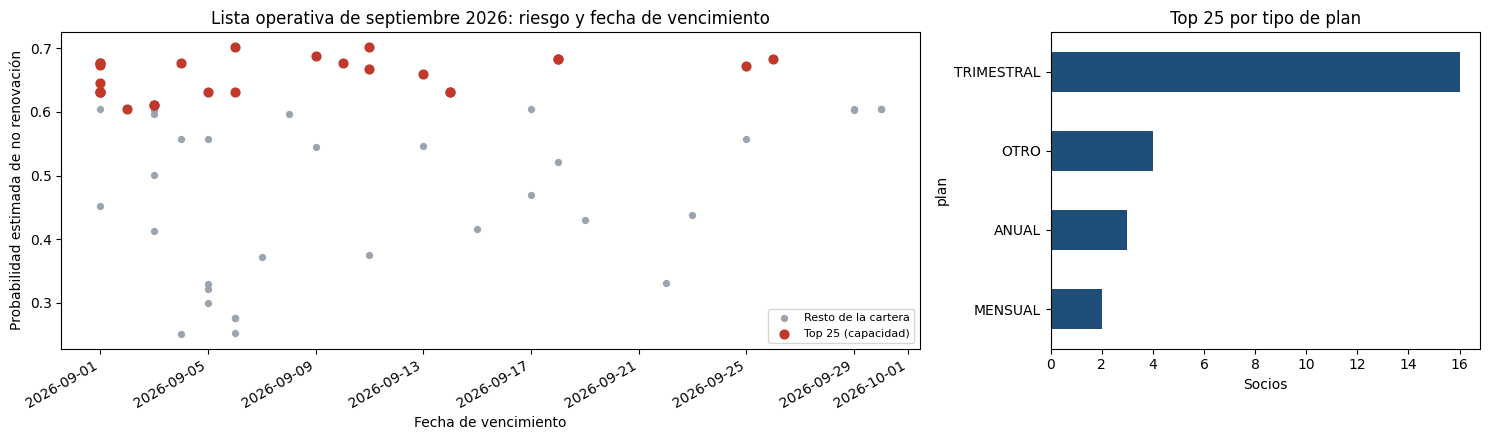

In [69]:
# Gráficos de la lista operativa
top = lista_septiembre.head(TOP_K)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})

# a) Calendario de contacto: cuándo vence cada socio priorizado y su riesgo
axes[0].scatter(lista_septiembre["vence"], lista_septiembre["probabilidad"], color=COLORES["gris"], s=18,
                label="Resto de la cartera")
axes[0].scatter(top["vence"], top["probabilidad"], color=COLORES["rojo"], s=40, label=f"Top {TOP_K} (capacidad)")
axes[0].set_ylabel("Probabilidad estimada de no renovación"); axes[0].set_xlabel("Fecha de vencimiento")
axes[0].set_title("Lista operativa de septiembre 2026: riesgo y fecha de vencimiento")
axes[0].legend(fontsize=8)
plt.setp(axes[0].get_xticklabels(), rotation=30, ha="right")

# b) Composición del top por tipo de plan
top["plan"].value_counts().sort_values().plot(kind="barh", ax=axes[1], color=COLORES["azul"])
axes[1].set_title(f"Top {TOP_K} por tipo de plan"); axes[1].set_xlabel("Socios")
plt.tight_layout(); plt.show()

#### Interpretación de los resultados

Al 31 de agosto de 2026 vencen **59 ciclos** en septiembre; **2** corresponden a socios que ya registraron una membresía posterior y se excluyen, por lo que la cartera a priorizar es de **57 socios distintos**. Esta es la lista **accionable** del MVP. Contiene socios cuyo vencimiento aún no ha ocurrido y cuyo resultado no se conoce; por eso no tiene columna de resultado real. Los primeros 25 (marcados como "dentro de capacidad") son los que se recomienda contactar primero; el gráfico de la izquierda permite organizar el contacto según la cercanía del vencimiento (un socio de alto riesgo que vence el 3 de septiembre debe atenderse antes que uno que vence el 28). La columna de factores principales indica el motivo de su priorización.

El mismo procedimiento se repite cada mes: al incorporar el Excel de un nuevo mes, se actualiza la fecha de corte y la lista cubre los vencimientos de los 30 días siguientes. Cuando se cumpla la ventana T+30 de estos socios (octubre 2026), sus resultados reales permitirán evaluar la lista y alimentar el reentrenamiento del modelo.

---
# Parte 14 · Exportación de resultados y controles de calidad finales

## Sección 14.1 · Exportación de tablas, listas y modelo

**Descripción.** Se guardan en la carpeta `salidas_mvp`:
- las comparaciones de modelos (validación y prueba) y la tabla de métricas para el documento;
- el resumen mensual y las métricas mensuales;
- **un Excel con una hoja por mes** con las listas priorizadas;
- el **modelo entrenado** (`.joblib`), que incluye el preprocesamiento, el umbral y las reglas usadas.
- la **lista operativa de septiembre 2026** (`lista_operativa_2026-09.xlsx`: top 25, cartera completa y resumen);
- el **modelo operativo** reentrenado (`modelo_mtabolic_operativo.joblib`), con los valores de referencia de la explicación individual.

**Justificación.** Para entregar evidencia revisable **sin necesidad de abrir Python**, y para que la aplicación (Streamlit) cargue el modelo tal como fue validado.

In [70]:
carpeta_salidas = Path("salidas_mvp")
carpeta_salidas.mkdir(exist_ok=True)

comparacion_validacion.to_csv(carpeta_salidas / "comparacion_modelos_validacion.csv", index=False)
comparacion_prueba.to_csv(carpeta_salidas / "comparacion_modelos_prueba.csv", index=False)
tabla_metricas_larga.to_csv(carpeta_salidas / "tabla_metricas_para_documento.csv", index=False)
resumen_mensual.to_csv(carpeta_salidas / "resumen_mensual_renovacion.csv", index=False)
metricas_mensuales.to_csv(carpeta_salidas / "metricas_mensuales_modelo.csv", index=False)
resumen_listas.to_csv(carpeta_salidas / "efectividad_listas_mensuales.csv", index=False)

with pd.ExcelWriter(carpeta_salidas / "listas_mensuales_priorizadas.xlsx", engine="openpyxl") as writer:
    for periodo, tabla in listas_mensuales.items():
        tabla.to_excel(writer, sheet_name=str(periodo)[:31], index=False)

with pd.ExcelWriter(carpeta_salidas / "lista_operativa_2026-09.xlsx", engine="openpyxl") as writer:
    lista_septiembre.head(TOP_K).to_excel(writer, sheet_name=f"top_{TOP_K}", index=False)
    lista_septiembre.to_excel(writer, sheet_name="cartera_completa", index=False)
    resumen_cartera.to_excel(writer, sheet_name="resumen", index=False)

joblib.dump({
    "modelo": modelo_operativo, "nombre_modelo": f"{modelo_seleccionado_nombre} (operativo, reentrenado)",
    "variables_modelo": VARIABLES_MODELO, "referencia_explicacion": REFERENCIA,
    "fecha_corte_datos": str(fecha_corte_datos.date()),
}, carpeta_salidas / "modelo_mtabolic_operativo.joblib")

joblib.dump({
    "modelo": modelo_seleccionado, "nombre_modelo": modelo_seleccionado_nombre,
    "variables_modelo": VARIABLES_MODELO, "umbral_clasificacion": umbral_seleccionado,
    "dias_antes_prediccion": DIAS_ANTES_PREDICCION, "dias_observacion": DIAS_OBSERVACION,
    "fecha_corte_datos": str(fecha_corte_datos.date()),
}, carpeta_salidas / "modelo_mtabolic.joblib")

display(pd.DataFrame({"archivo": sorted(p.name for p in carpeta_salidas.iterdir())}))

,archivo
0,comparacion_modelos_prueba.csv
1,comparacion_modelos_validacion.csv
2,efectividad_listas_mensuales.csv
3,lista_operativa_2026-09.xlsx
4,listas_mensuales_priorizadas.xlsx
5,metricas_mensuales_modelo.csv
6,modelo_mtabolic.joblib
7,modelo_mtabolic_operativo.joblib
8,resumen_mensual_renovacion.csv
9,tabla_metricas_para_documento.csv


## Sección 14.2 · Controles de coherencia

**Descripción.** Se verifican automáticamente ocho reglas críticas. Si alguna falla, el notebook se detiene con un error.

| # | Control | Qué protege |
|---|---|---|
| 1 | La prueba no está vacía | Que exista una evaluación independiente. |
| 2 | Ningún dato personal ni la respuesta están entre las variables | Ética y ausencia de fuga de información. |
| 3 | Ningún pendiente tiene etiqueta 0/1 | La regla T+30 del ejemplo del tutor. |
| 4 | Ninguna predicción usa una fecha posterior al corte | Que no se use información del futuro. |
| 5–6 | Una sola fila por socio en las listas | Que cada cupo de contacto corresponda a una persona distinta. |
| 7–8 | Lista operativa con vencimientos futuros y sin socios ya renovados | Que la lista sea accionable. |

**Objetivo.** que los resultados copiados al documento final sean confiables. Es el equivalente a una **inspección final de calidad** antes de despachar el producto.

In [71]:
controles = []
controles.append(("1. La prueba final no está vacía", len(test) > 0))
prohibidas = {"nombre", "cedula", "celular", "correo", "socio_id", "no_renovo", "fecha_renovacion_detectada"}
controles.append(("2. Sin datos personales ni la respuesta entre las variables", not prohibidas.intersection(VARIABLES_MODELO)))
controles.append(("3. Ningún pendiente tiene etiqueta 0/1", datos.loc[datos["estado_ciclo"].str.startswith("PENDIENTE"), "no_renovo"].isna().all()))
controles.append(("4. Ninguna predicción usa fechas posteriores al corte", (ciclos_para_lista["fecha_prediccion"] <= fecha_corte_datos).all()))
controles.append(("5. Cada lista mensual tiene una sola fila por socio",
                  all(not t["socio_anonimo"].duplicated().any() for t in listas_mensuales.values())))
controles.append(("6. La lista operativa tiene una sola fila por socio", not lista_septiembre["socio_anonimo"].duplicated().any()))
controles.append(("7. La lista operativa solo incluye vencimientos futuros con T−30 ya ocurrido",
                  ((a_priorizar["fecha_fin"] > FECHA_GENERACION) & (a_priorizar["fecha_prediccion"] <= FECHA_GENERACION)).all()))
controles.append(("8. La lista operativa excluye a quienes ya renovaron", not a_priorizar["ya_renovo"].any()))

tabla_controles = pd.DataFrame(controles, columns=["Control", "Aprobado"])
display(tabla_controles)
assert tabla_controles["Aprobado"].all(), "Algún control falló: revisar antes de usar los resultados."
print("Todos los controles finales fueron aprobados.")

,Control,Aprobado
0,1. La prueba final no está vacía,True
1,2. Sin datos personales ni la respuesta entre las variables,True
2,3. Ningún pendiente tiene etiqueta 0/1,True
3,4. Ninguna predicción usa fechas posteriores al corte,True
4,5. Cada lista mensual tiene una sola fila por socio,True
5,6. La lista operativa tiene una sola fila por socio,True
6,7. La lista operativa solo incluye vencimientos futuros con T−30 ya ocurrido,True
7,8. La lista operativa excluye a quienes ya renovaron,True


Todos los controles finales fueron aprobados.


---
# Parte 15 · Resultados consolidados, reconciliación y conclusiones

## Sección 15.1 · Resumen de resultados del MVP

,Bloque,Indicador,Valor,Comparación / nota
0,Datos,Registros leídos de las hojas mensuales,2.771,20 hojas · ene-2025 a ago-2026
1,Datos,Ciclos evaluables,1.564,"70,2 % no renovó"
2,Datos,Ciclos pendientes (ago-2026),96,T+30 aún no termina
3,Modelo,Modelo seleccionado,Random Forest,"umbral 0,31 elegido en validación"
4,Prueba,PR-AUC (ordenamiento),"0,790","piso 0,668 → +0,122"
5,Prueba,ROC-AUC,"0,695","0,50 = azar"
6,Prueba,F1,"0,820","piso 0,801 → +0,019"
7,Prueba,Brier (menor es mejor),"0,230","piso 0,228 → requiere calibración"
8,Utilidad,Aciertos en el top 25,20 de 25,"al azar ≈ 16,7"
9,Utilidad,Lift@25,"1,20",mejora de +20 % con el mismo esfuerzo


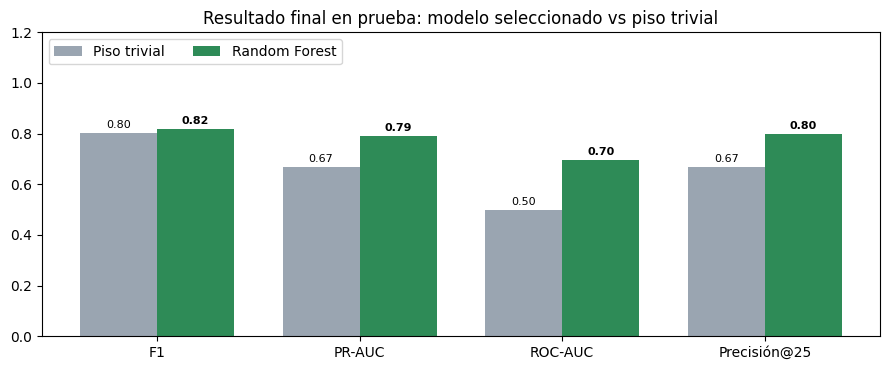

In [72]:
sel = comparacion_prueba.set_index("Modelo").loc[modelo_seleccionado_nombre]
piso = comparacion_prueba.iloc[0]
fila25 = utilidad_top_k.loc[utilidad_top_k["Socios contactados (K)"] == TOP_K].iloc[0]

resumen_resultados = pd.DataFrame([
    ["Datos", "Registros leídos de las hojas mensuales", f"{n_filas_utiles:,}".replace(",", "."), "20 hojas · ene-2025 a ago-2026"],
    ["Datos", "Ciclos evaluables", f"{len(analitico):,}".replace(",", "."), f"{es(100*analitico['no_renovo'].mean(), 1)} % no renovó"],
    ["Datos", "Ciclos pendientes (ago-2026)", str(int(datos["estado_ciclo"].str.startswith("PENDIENTE").sum())), "T+30 aún no termina"],
    ["Modelo", "Modelo seleccionado", modelo_seleccionado_nombre, f"umbral {es(umbral_seleccionado, 2)} elegido en validación"],
    ["Prueba", "PR-AUC (ordenamiento)", es(sel["PR-AUC"]), f"piso {es(piso['PR-AUC'])} → {es(sel['PR-AUC']-piso['PR-AUC'], 3, True)}"],
    ["Prueba", "ROC-AUC", es(sel["ROC-AUC"]), "0,50 = azar"],
    ["Prueba", "F1", es(sel["F1"]), f"piso {es(piso['F1'])} → {es(sel['F1']-piso['F1'], 3, True)}"],
    ["Prueba", "Brier (menor es mejor)", es(sel["Brier"]), f"piso {es(piso['Brier'])} → requiere calibración"],
    ["Utilidad", f"Aciertos en el top {TOP_K}", f"{int(fila25['Aciertos con el sistema'])} de {TOP_K}", f"al azar ≈ {es(fila25['Aciertos esperados al azar'], 1)}"],
    ["Utilidad", f"Lift@{TOP_K}", es(sel[f"Lift@{TOP_K}"], 2), f"mejora de {fila25['Mejora relativa']} con el mismo esfuerzo"],
    ["Operación", "Lista operativa septiembre 2026", f"{len(lista_septiembre)} socios", f"top {TOP_K} dentro de capacidad · una fila por socio"],
], columns=["Bloque", "Indicador", "Valor", "Comparación / nota"])
display(resumen_resultados)

# Gráfico resumen: cuánto supera el modelo seleccionado al piso en cada métrica "mayor es mejor"
m_graf = ["F1", "PR-AUC", "ROC-AUC", f"Precisión@{TOP_K}"]
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(m_graf)); w = 0.38
ax.bar(x - w/2, [piso[m] for m in m_graf], w, label="Piso trivial", color=COLORES["gris"])
ax.bar(x + w/2, [sel[m] for m in m_graf], w, label=modelo_seleccionado_nombre, color=COLORES["verde"])
for i, m in enumerate(m_graf):
    ax.text(i - w/2, piso[m] + 0.02, f"{piso[m]:.2f}", ha="center", fontsize=8)
    ax.text(i + w/2, sel[m] + 0.02, f"{sel[m]:.2f}", ha="center", fontsize=8, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(m_graf); ax.set_ylim(0, 1.2)
ax.set_title("Resultado final en prueba: modelo seleccionado vs piso trivial")
ax.legend(loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

## Sección 15.2 · Reconciliación con el Informe S5 y el documento final

**Descripción.** Se comparan las cifras de este notebook con las reportadas en el **Informe S5 de resultados preliminares** y en el **documento final**.

**Justificación.** El notebook se ejecutó con reglas ligeramente distintas a las de la corrida del Informe S5. Antes de presentar, **documento y código deben decir lo mismo**. Esta tabla muestra qué cambió y por qué.

**Objetivo.** transparencia y trazabilidad de todas las cifras.

In [73]:
nb_trazab = datos["estado_ciclo"].value_counts()
reconciliacion = pd.DataFrame([
    ["Filas leídas de hojas mensuales", "2.771", f"{n_filas_utiles:,}".replace(",", "."), "Coincide."],
    ["Registros con identidad utilizable", "2.748", f"{len(datos):,}".replace(",", "."), "Coincide."],
    ["Socios distintos", "1.474", f"{datos['socio_id'].nunique():,}".replace(",", "."), "Regla de identidad distinta (cédula ≥ 9 dígitos, si no, nombre)."],
    ["Ciclos evaluables", "1.557", f"{len(analitico):,}".replace(",", "."), f"Reglas de exclusión con pequeñas diferencias (sin fecha: 865 vs {nb_trazab.get('EXCLUIDO - Sin fecha de vencimiento',0)}; fuera de rango/posterior: 163 vs {nb_trazab.get('EXCLUIDO - Fecha fuera de rango',0)+nb_trazab.get('EXCLUIDO - Vencimiento posterior al período disponible',0)}; duración: 51 vs {nb_trazab.get('EXCLUIDO - Duración implausible',0)})."],
    ["No renovados / tasa", "1.080 (69,4 %)", f"{int(analitico['no_renovo'].sum()):,}".replace(",", ".") + f" ({es(100*analitico['no_renovo'].mean(), 1)} %)", "Consecuencia de las dos filas anteriores."],
    ["Entrenamiento / Validación / Prueba", "928 / 354 / 275", f"{len(train)} / {len(validation)} / {len(test)}", "Mismos períodos; diferencias de pocos casos por la población."],
    ["Modelo seleccionado", "Random Forest", modelo_seleccionado_nombre, "Coincide."],
    ["Umbral de clasificación", "No explícito", f"{es(umbral_seleccionado, 2)} (máx. F1 en validación)", "Ahora se reporta, como pidió el tutor."],
    ["PR-AUC en prueba (piso)", "0,765 (0,633)", f"{es(sel['PR-AUC'], 3)} ({es(piso['PR-AUC'], 3)})", "Mejora similar frente al piso (≈ +0,12/+0,13)."],
    ["Brier en prueba (piso)", "0,221 (0,232)", f"{es(sel['Brier'], 3)} ({es(piso['Brier'], 3)})", "En esta corrida no mejora al piso: calibración pendiente."],
    ["F1 en prueba (piso)", "0,777 (0,775)", f"{es(sel['F1'], 3)} ({es(piso['F1'], 3)})", "Margen estrecho en ambas corridas."],
    ["Aciertos top 25 (azar)", "19 (15,8)", f"{int(fila25['Aciertos con el sistema'])} ({es(fila25['Aciertos esperados al azar'], 1)})", "Misma conclusión: ≈ +20 % de efectividad."],
], columns=["Indicador", "Informe S5 / documento", "Este notebook", "Explicación"])
display(reconciliacion)

,Indicador,Informe S5 / documento,Este notebook,Explicación
0,Filas leídas de hojas mensuales,2.771,2.771,Coincide.
1,Registros con identidad utilizable,2.748,2.748,Coincide.
2,Socios distintos,1.474,1.410,"Regla de identidad distinta (cédula ≥ 9 dígitos, si no, nombre)."
3,Ciclos evaluables,1.557,1.564,Reglas de exclusión con pequeñas diferencias (sin fecha: 865 vs 855; fuera de rango/posterior: 163 vs 168; duración: 51 vs 49).
4,No renovados / tasa,"1.080 (69,4 %)","1.098 (70,2 %)",Consecuencia de las dos filas anteriores.
5,Entrenamiento / Validación / Prueba,928 / 354 / 275,932 / 355 / 277,Mismos períodos; diferencias de pocos casos por la población.
6,Modelo seleccionado,Random Forest,Random Forest,Coincide.
7,Umbral de clasificación,No explícito,"0,31 (máx. F1 en validación)","Ahora se reporta, como pidió el tutor."
8,PR-AUC en prueba (piso),"0,765 (0,633)","0,790 (0,668)","Mejora similar frente al piso (≈ +0,12/+0,13)."
9,Brier en prueba (piso),"0,221 (0,232)","0,230 (0,228)",En esta corrida no mejora al piso: calibración pendiente.


**Nota sobre versiones de librerías:** al ejecutar con versiones distintas de pandas/scikit-learn pueden aparecer diferencias de 1 caso o de 0,01 en algún umbral (por ejemplo, 1.564 vs 1.565 ciclos evaluables). No afectan las conclusiones; por eso las cifras del documento deben copiarse de **una única corrida registrada**.

**Recomendación:** actualizar la Tabla 1 del documento final y las Tablas 1, 2, 4 y 5 del Informe S5 con las cifras de este notebook (o bien ajustar el código a la regla anterior), de modo que **todo el proyecto use una sola versión**. Las conclusiones de fondo **no cambian**: el modelo seleccionado es el mismo, el ordenamiento supera claramente al piso, la mejora en F1 es estrecha y las probabilidades requieren calibración.

## Sección 15.3 · Conclusiones

1. **Se construyó un MVP completo y reproducible** que transforma los Excel operativos de Mtabolic en una lista mensual de socios priorizados por riesgo de no renovación, con trazabilidad desde cada fila original hasta cada predicción.

2. **La definición temporal es correcta y verificable.** Un ciclo solo se considera no renovado cuando termina su ventana T+30; los casos sin ventana completa quedan **pendientes**. Esto se comprobó automáticamente con el ejemplo del tutor y con los 96 casos de agosto 2026.

3. **El problema tiene una prevalencia alta** (≈70 % no renueva), lo que hace que métricas como accuracy o F1 parezcan altas incluso sin modelo. Por eso todas las métricas se presentan junto al **piso trivial**.

4. **El Random Forest fue seleccionado** con una regla fijada de antemano (F1, PR-AUC y Brier en validación). En prueba, **ordena claramente mejor que el azar** (PR-AUC ≈0,79 vs ≈0,67) y la lista de 25 concentra **≈20 % más** socios en riesgo que una selección sin criterio.

5. **La señal es real pero moderada** (ROC-AUC ≈0,69). La ausencia de datos de asistencia limita la capacidad predictiva.

6. **Las probabilidades aún no son confiables como porcentajes** (Brier similar al piso, curva de calibración desplazada). El sistema debe usarse para **priorizar**, no para comunicar un porcentaje exacto a cada socio.

7. **Cada recomendación es explicable.** Además de la importancia global (12.9) y el efecto de las variables (12.10), cada socio de la lista incluye sus tres factores principales de riesgo (13.3).

8. **El MVP produce una lista operativa hacia adelante.** Con los datos al 31 de agosto de 2026 se genera la lista de socios que vencen en septiembre, con una fila por socio y excluyendo a quienes ya renovaron, usando un modelo reentrenado con todos los resultados conocidos.

9. **El sistema es una herramienta de apoyo**, no un sustituto del criterio del personal, y no demuestra que el contacto cause la renovación.

## Sección 15.4 · Limitaciones y próximos pasos

**Limitaciones**

| Limitación | Efecto | Mitigación propuesta |
|---|---|---|
| Sin datos de asistencia | Menor capacidad predictiva | Incorporar registros del sistema biométrico. |
| 31 % de registros sin fecha de vencimiento | Se pierde casi un tercio de la información | Mejorar la captura de fechas en Mtabolic. |
| Cambio de comportamiento 2025 → 2026 | Probabilidades desplazadas | Calibrar y reentrenar periódicamente. |
| Pocos casos de planes anual/semestral | Resultados poco confiables en esos segmentos | Acumular más historia antes de conclusiones por segmento. |
| Registros duplicados en la base | Podrían duplicar socios en las listas | **Resuelto en las listas** (una fila por socio, Secciones 13.4 y 13.8). Pendiente acordar con Mtabolic una regla de depuración en la base. |
| Definición de no renovación (30 días) | Congelamientos o reingresos tardíos podrían mal clasificarse | Validar la definición con Mtabolic. |

**Próximos pasos (alineados con el backlog del Informe S5)**

| # | Tarea | Prioridad | Estado tras este notebook |
|---|---|---|---|
| 1 | Corregir (calibrar) las probabilidades | Alta | Diagnosticado con la curva de calibración (Sección 12.5). Pendiente aplicar la corrección. |
| 2 | Confirmar la capacidad real de contacto | Alta | Pendiente con Mtabolic. El notebook ya muestra resultados para K = 10, 25, 50 y 100. |
| 3 | Validar la definición de no renovación | Alta | Pendiente con Mtabolic. El parámetro `DIAS_OBSERVACION` permite cambiarla en un solo lugar. |
| 4 | Verificar que la mejora no sea azar | Media | **Realizado** con bootstrap (Sección 12.7). |
| 5 | Evaluar XGBoost como cuarta alternativa | Media | Pendiente; la estructura del notebook permite agregarlo en `modelos`. |
| 6 | Recuperar registros sin fecha de vencimiento | Baja | Pendiente con Mtabolic. |
| 7 | Una fila por socio en las listas | Media | **Realizado** (Secciones 13.4 y 13.8, controles 5 y 6). |
| 8 | Explicación individual de cada socio priorizado | Media | **Realizado** (Sección 13.3). Evaluar SHAP como alternativa. |
| 9 | Lista operativa hacia adelante | Alta | **Realizado** para septiembre 2026 (Sección 13.8). Pendiente automatizarla en la aplicación Streamlit. |

## Referencias

- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- de Lima Lemos, R. A., Silva, T. C., & Tabak, B. M. (2022). Propension to customer churn in a financial institution: A machine learning approach. *Neural Computing and Applications, 34*(14), 11751–11768.
- Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media.
- Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3.ª ed.). Wiley.
- International Organization for Standardization. (2023). *ISO/IEC 25059:2023 — Quality model for AI systems*. ISO.
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning with applications in Python*. Springer.
- Lalwani, P., Mishra, M. K., Chadha, J. S., & Sethi, P. (2022). Customer churn prediction system: A machine learning approach. *Computing, 104*(2), 271–294.
- McKinney, W. (2022). *Python for data analysis* (3.ª ed.). O'Reilly Media.
- Mena, G., Coussement, K., De Bock, K. W., De Caigny, A., & Lessmann, S. (2024). Exploiting time-varying RFM measures for customer churn prediction with deep neural networks. *Annals of Operations Research, 339*, 765–787.
- Sobreiro, P., Guedes-Carvalho, P., Santos, A., Pinheiro, P., & Gonçalves, C. (2021). Predicting fitness centre dropout. *International Journal of Environmental Research and Public Health, 18*(19), 10465.